# Ames Housing Price Prediction
## Part 1: Dataset Understanding & Part 2: Exploratory Data Analysis (EDA)

## 1. Dataset Understanding

In [3]:
#!rm -rf /kaggle/working/*

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# Load the dataset
#df = pd.read_csv('AmesHousing.csv')
# Kaggle mounts datasets under /kaggle/input/<dataset-name>/
#df = pd.read_csv('/kaggle/input/datasets/mahmoud5mansour/ameshousing/AmesHousing.csv')

df = pd.read_csv('AmesHousing.csv')

# Quick look
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### 1.1 Rename columns to simpler, easier-to-read names

The original column names have spaces and short codes (e.g. `MS SubClass`, `Gr Liv Area`, `1st Flr SF`) which are hard to type and remember. We rename them to clear, single-word, no-space names so the rest of the notebook is easier to read.

In [5]:
# Dictionary: original column name -> simple, readable name
rename_map = {
    'Order': 'RowID',
    'PID': 'ParcelID',
    'MS SubClass': 'BuildingClass',
    'MS Zoning': 'ZoningClass',
    'Lot Frontage': 'LotFrontage',
    'Lot Area': 'LotArea',
    'Street': 'StreetType',
    'Alley': 'AlleyAccess',
    'Lot Shape': 'LotShape',
    'Land Contour': 'LandContour',
    'Utilities': 'Utilities',
    'Lot Config': 'LotConfig',
    'Land Slope': 'LandSlope',
    'Neighborhood': 'Neighborhood',
    'Condition 1': 'Condition1',
    'Condition 2': 'Condition2',
    'Bldg Type': 'BuildingType',
    'House Style': 'HouseStyle',
    'Overall Qual': 'OverallQuality',
    'Overall Cond': 'OverallCondition',
    'Year Built': 'YearBuilt',
    'Year Remod/Add': 'YearRemodeled',
    'Roof Style': 'RoofStyle',
    'Roof Matl': 'RoofMaterial',
    'Exterior 1st': 'ExteriorMaterial1',
    'Exterior 2nd': 'ExteriorMaterial2',
    'Mas Vnr Type': 'MasonryVeneerType',
    'Mas Vnr Area': 'MasonryVeneerArea',
    'Exter Qual': 'ExteriorQuality',
    'Exter Cond': 'ExteriorCondition',
    'Foundation': 'FoundationType',
    'Bsmt Qual': 'BasementQuality',
    'Bsmt Cond': 'BasementCondition',
    'Bsmt Exposure': 'BasementExposure',
    'BsmtFin Type 1': 'BasementFinishType1',
    'BsmtFin SF 1': 'BasementFinishArea1',
    'BsmtFin Type 2': 'BasementFinishType2',
    'BsmtFin SF 2': 'BasementFinishArea2',
    'Bsmt Unf SF': 'BasementUnfinishedArea',
    'Total Bsmt SF': 'TotalBasementArea',
    'Heating': 'HeatingType',
    'Heating QC': 'HeatingQuality',
    'Central Air': 'HasCentralAir',
    'Electrical': 'ElectricalSystem',
    '1st Flr SF': 'FirstFloorArea',
    '2nd Flr SF': 'SecondFloorArea',
    'Low Qual Fin SF': 'LowQualityFinishedArea',
    'Gr Liv Area': 'AboveGroundLivingArea',
    'Bsmt Full Bath': 'BasementFullBaths',
    'Bsmt Half Bath': 'BasementHalfBaths',
    'Full Bath': 'FullBaths',
    'Half Bath': 'HalfBaths',
    'Bedroom AbvGr': 'Bedrooms',
    'Kitchen AbvGr': 'Kitchens',
    'Kitchen Qual': 'KitchenQuality',
    'TotRms AbvGrd': 'TotalRooms',
    'Functional': 'Functionality',
    'Fireplaces': 'Fireplaces',
    'Fireplace Qu': 'FireplaceQuality',
    'Garage Type': 'GarageType',
    'Garage Yr Blt': 'GarageYearBuilt',
    'Garage Finish': 'GarageFinish',
    'Garage Cars': 'GarageCapacityCars',
    'Garage Area': 'GarageArea',
    'Garage Qual': 'GarageQuality',
    'Garage Cond': 'GarageCondition',
    'Paved Drive': 'PavedDriveway',
    'Wood Deck SF': 'WoodDeckArea',
    'Open Porch SF': 'OpenPorchArea',
    'Enclosed Porch': 'EnclosedPorchArea',
    '3Ssn Porch': 'ThreeSeasonPorchArea',
    'Screen Porch': 'ScreenPorchArea',
    'Pool Area': 'PoolArea',
    'Pool QC': 'PoolQuality',
    'Fence': 'FenceQuality',
    'Misc Feature': 'MiscFeature',
    'Misc Val': 'MiscValue',
    'Mo Sold': 'MonthSold',
    'Yr Sold': 'YearSold',
    'Sale Type': 'SaleType',
    'Sale Condition': 'SaleCondition',
    'SalePrice': 'SalePrice',
}

df = df.rename(columns=rename_map)
df.columns.tolist()

['RowID',
 'ParcelID',
 'BuildingClass',
 'ZoningClass',
 'LotFrontage',
 'LotArea',
 'StreetType',
 'AlleyAccess',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BuildingType',
 'HouseStyle',
 'OverallQuality',
 'OverallCondition',
 'YearBuilt',
 'YearRemodeled',
 'RoofStyle',
 'RoofMaterial',
 'ExteriorMaterial1',
 'ExteriorMaterial2',
 'MasonryVeneerType',
 'MasonryVeneerArea',
 'ExteriorQuality',
 'ExteriorCondition',
 'FoundationType',
 'BasementQuality',
 'BasementCondition',
 'BasementExposure',
 'BasementFinishType1',
 'BasementFinishArea1',
 'BasementFinishType2',
 'BasementFinishArea2',
 'BasementUnfinishedArea',
 'TotalBasementArea',
 'HeatingType',
 'HeatingQuality',
 'HasCentralAir',
 'ElectricalSystem',
 'FirstFloorArea',
 'SecondFloorArea',
 'LowQualityFinishedArea',
 'AboveGroundLivingArea',
 'BasementFullBaths',
 'BasementHalfBaths',
 'FullBaths',
 'HalfBaths',
 'Bedrooms',
 'Kitchens',
 'KitchenQ

In [6]:
# Save the renamed DataFrame as a new CSV file
# df.to_csv('AmesHousing_Renamed.csv', index=False)

In [7]:
# from google.colab import files

# files.download('AmesHousing_Renamed.csv')

In [8]:
df.shape

(2930, 82)

In [9]:
df.head(10)

,RowID,ParcelID,BuildingClass,ZoningClass,LotFrontage,LotArea,StreetType,AlleyAccess,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BuildingType,HouseStyle,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,RoofStyle,RoofMaterial,ExteriorMaterial1,ExteriorMaterial2,MasonryVeneerType,MasonryVeneerArea,ExteriorQuality,ExteriorCondition,FoundationType,BasementQuality,BasementCondition,BasementExposure,BasementFinishType1,BasementFinishArea1,BasementFinishType2,BasementFinishArea2,BasementUnfinishedArea,TotalBasementArea,HeatingType,HeatingQuality,HasCentralAir,ElectricalSystem,FirstFloorArea,SecondFloorArea,LowQualityFinishedArea,AboveGroundLivingArea,BasementFullBaths,BasementHalfBaths,FullBaths,HalfBaths,Bedrooms,Kitchens,KitchenQuality,TotalRooms,Functionality,Fireplaces,FireplaceQuality,GarageType,GarageYearBuilt,GarageFinish,GarageCapacityCars,GarageArea,GarageQuality,GarageCondition,PavedDriveway,WoodDeckArea,OpenPorchArea,EnclosedPorchArea,ThreeSeasonPorchArea,ScreenPorchArea,PoolArea,PoolQuality,FenceQuality,MiscFeature,MiscValue,MonthSold,YearSold,SaleType,SaleCondition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
5,6,527105030,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,6,1998,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,20.0,TA,TA,PConc,TA,TA,No,GLQ,602.0,Unf,0.0,324.0,926.0,GasA,Ex,Y,SBrkr,926,678,0,1604,0.0,0.0,2,1,3,1,Gd,7,Typ,1,Gd,Attchd,1998.0,Fin,2.0,470.0,TA,TA,Y,360,36,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal,195500
6,7,527127150,120,RL,41.0,4920,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,StoneBr,Norm,Norm,TwnhsE,1Story,8,5,2001,2001,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,616.0,Unf,0.0,722.0,1338.0,GasA,Ex,Y,SBrkr,1338,0,0,1338,1.0,0.0,2,0,2,1,Gd,6,Typ,0,NaN,Attchd,2001.0,Fin,2.0,582.0,TA,TA,Y,0,0,170,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,213500
7,8,527145080,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,Gtl,StoneBr,Norm,Norm,TwnhsE,1Story,8,5,1992,1992,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,263.0,Unf,0.0,1017.0,1280.0,GasA,Ex,Y,SBrkr,1280,0,0,1280,0.0,0.0,2,0,2,1,Gd,5,Typ,0,NaN,Attchd,1992.0,RFn,2.0,506.0,TA,TA,Y,0,82,0,0,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal,191500
8,9,527146030,120,RL,39.0,5389,Pave,NaN

In [10]:
df.tail(10)

,RowID,ParcelID,BuildingClass,ZoningClass,LotFrontage,LotArea,StreetType,AlleyAccess,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BuildingType,HouseStyle,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,RoofStyle,RoofMaterial,ExteriorMaterial1,ExteriorMaterial2,MasonryVeneerType,MasonryVeneerArea,ExteriorQuality,ExteriorCondition,FoundationType,BasementQuality,BasementCondition,BasementExposure,BasementFinishType1,BasementFinishArea1,BasementFinishType2,BasementFinishArea2,BasementUnfinishedArea,TotalBasementArea,HeatingType,HeatingQuality,HasCentralAir,ElectricalSystem,FirstFloorArea,SecondFloorArea,LowQualityFinishedArea,AboveGroundLivingArea,BasementFullBaths,BasementHalfBaths,FullBaths,HalfBaths,Bedrooms,Kitchens,KitchenQuality,TotalRooms,Functionality,Fireplaces,FireplaceQuality,GarageType,GarageYearBuilt,GarageFinish,GarageCapacityCars,GarageArea,GarageQuality,GarageCondition,PavedDriveway,WoodDeckArea,OpenPorchArea,EnclosedPorchArea,ThreeSeasonPorchArea,ScreenPorchArea,PoolArea,PoolQuality,FenceQuality,MiscFeature,MiscValue,MonthSold,YearSold,SaleType,SaleCondition,SalePrice
2920,2921,923228310,160,RM,21.0,1894,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,MeadowV,Norm,Norm,TwnhsE,2Story,4,5,1970,1970,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,252.0,Unf,0.0,294.0,546.0,GasA,TA,Y,SBrkr,546,546,0,1092,0.0,0.0,1,1,3,1,TA,6,Typ,0,NaN,CarPort,1970.0,Unf,1.0,286.0,TA,TA,Y,0,24,0,0,0,0,NaN,NaN,NaN,0,4,2006,WD,Abnorml,71000
2921,2922,923229110,90,RL,55.0,12640,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,Duplex,1Story,6,5,1976,1976,Gable,CompShg,Plywood,Plywood,NaN,0.0,TA,TA,CBlock,TA,TA,Gd,Rec,936.0,LwQ,396.0,396.0,1728.0,GasA,TA,Y,SBrkr,1728,0,0,1728,0.0,0.0,2,0,4,2,TA,8,Typ,0,NaN,Attchd,1976.0,Unf,2.0,574.0,TA,TA,Y,40,0,0,0,0,0,NaN,NaN,NaN,0,7,2006,WD,Normal,150900
2922,2923,923230040,90,RL,63.0,9297,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,Duplex,1Story,5,5,1976,1976,Gable,CompShg,Plywood,Plywood,NaN,0.0,TA,TA,CBlock,TA,TA,No,ALQ,1606.0,Unf,0.0,122.0,1728.0,GasA,TA,Y,SBrkr,1728,0,0,1728,2.0,0.0,2,0,4,2,TA,8,Typ,0,NaN,Detchd,1976.0,Unf,2.0,560.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,7,2006,WD,Family,188000
2923,2924,923250060,20,RL,80.0,17400,Pave,NaN,Reg,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,5,5,1977,1977,Gable,CompShg,BrkFace,BrkFace,NaN,0.0,TA,TA,CBlock,TA,TA,No,ALQ,936.0,Unf,0.0,190.0,1126.0,GasA,Fa,Y,SBrkr,1126,0,0,1126,1.0,0.0,2,0,3,1,TA,5,Typ,1,Gd,Attchd,1977.0,RFn,2.0,484.0,TA,TA,P,295,41,0,0,0,0,NaN,NaN,NaN,0,5,2006,WD,Normal,160000
2924,2925,923251180,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,1Story,5,7,1960,1996,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,ALQ,1224.0,Unf,0.0,0.0,1224.0,GasA,Ex,Y,SBrkr,1224,0,0,1224,1.0,0.0,1,0,4,1,TA,7,Typ,1,TA,Detchd,1960.0,Unf,2.0,576.0,TA,TA,Y,474,0,0,0,0,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml,131000
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,6,6,1984,1984,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,TA,TA,CBlock,TA,TA,Av,GLQ,819.0,Unf,0.0,184.0,1003.0,GasA,TA,Y,SBrkr,1003,0,0,1003,1.0,0.0,1,0,3,1,TA,6,Typ,0,NaN,Detchd,1984.0,Unf,2.0,588.0,TA,TA,Y,120,0,0,0,0,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,5,5,1983,1983,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,TA,TA,CBlock,Gd,TA,Av,BLQ,301.0,ALQ,324.0,239.0,864.0,GasA,TA,Y,SBrkr,902,0,0,902,1.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1983.0,Unf,2.0,484.0,TA,TA,Y,164,0,0,0,0,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,5,5,1992,1992,Gable,CompShg,HdBoard,Wd Shng,NaN,0.0,TA,TA,PConc,Gd,TA,Av,GLQ,337.0,Unf,0.0,575.0,912.0,GasA,TA,Y,SBrkr,970,0,0,970,0.0,1.0,1,0,3,1,TA,6,Typ,0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,Y,80,32,0,0,0,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2

In [11]:
df.describe()

,RowID,ParcelID,BuildingClass,LotFrontage,LotArea,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,MasonryVeneerArea,BasementFinishArea1,BasementFinishArea2,BasementUnfinishedArea,TotalBasementArea,FirstFloorArea,SecondFloorArea,LowQualityFinishedArea,AboveGroundLivingArea,BasementFullBaths,BasementHalfBaths,FullBaths,HalfBaths,Bedrooms,Kitchens,TotalRooms,Fireplaces,GarageYearBuilt,GarageCapacityCars,GarageArea,WoodDeckArea,OpenPorchArea,EnclosedPorchArea,ThreeSeasonPorchArea,ScreenPorchArea,PoolArea,MiscValue,MonthSold,YearSold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,2929.000000,2929.000000,2929.000000,2929.000000,2930.000000,2930.000000,2930.000000,2930.000000,2928.000000,2928.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2771.000000,2929.000000,2929.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,442.629566,49.722431,559.262547,1051.614544,1159.557679,335.455973,4.676792,1499.690444,0.431352,0.061134,1.566553,0.379522,2.854266,1.044369,6.443003,0.599317,1978.132443,1.766815,472.819734,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,455.590839,169.168476,439.494153,440.615067,391.890885,428.395715,46.310510,505.508887,0.524820,0.245254,0.552941,0.502629,0.827731,0.214076,1.572964,0.647921,25.528411,0.760566,215.046549,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1895.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,0.000000,219.000000,793.000000,876.250000,0.000000,0.000000,1126.000000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1960.000000,1.000000,320.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,370.000000,0.000000,466.000000,990.000000,1084.000000,0.000000,0.000000,1442.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1979.000000,2.000000,480.000000,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,734.000000,0.000000,802.000000,1302.000000,1384.000000,703.750000,0.000000,1742.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,5095.000000,2065.000000,1064.000000,5642.000000,3.000000,2.000000,4.000000,2.000000,8.000000,3.000000,15.000000,4.000000,2207.000000,5.000000,1488.000000,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [12]:
#so we can drop the rowid because all values in parceid is unique
df['ParcelID'].nunique()

2930

In [13]:
print('Number of rows:', df.shape[0])
print('Number of columns:', df.shape[1])

Number of rows: 2930
Number of columns: 82


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   RowID                   2930 non-null   int64  
 1   ParcelID                2930 non-null   int64  
 2   BuildingClass           2930 non-null   int64  
 3   ZoningClass             2930 non-null   object 
 4   LotFrontage             2440 non-null   float64
 5   LotArea                 2930 non-null   int64  
 6   StreetType              2930 non-null   object 
 7   AlleyAccess             198 non-null    object 
 8   LotShape                2930 non-null   object 
 9   LandContour             2930 non-null   object 
 10  Utilities               2930 non-null   object 
 11  LotConfig               2930 non-null   object 
 12  LandSlope               2930 non-null   object 
 13  Neighborhood            2930 non-null   object 
 14  Condition1              2930 non-null   

In [15]:
df.isnull().sum()

,0
RowID,0
ParcelID,0
BuildingClass,0
ZoningClass,0
LotFrontage,490
...,...
MonthSold,0
YearSold,0
SaleType,0
SaleCondition,0


In [16]:
df.loc[:, df.isnull().any()].isnull().sum()

,0
LotFrontage,490
AlleyAccess,2732
MasonryVeneerType,1775
MasonryVeneerArea,23
BasementQuality,80
BasementCondition,80
BasementExposure,83
BasementFinishType1,80
BasementFinishArea1,1
BasementFinishType2,81


## Basic Dataset Inspection




In [17]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print('Number of numerical columns:', len(numerical_cols))
print('Number of categorical columns:', len(categorical_cols))
print()
print('Numerical columns:', numerical_cols)
print()
print('Categorical columns:', categorical_cols)

Number of numerical columns: 39
Number of categorical columns: 43

Numerical columns: ['RowID', 'ParcelID', 'BuildingClass', 'LotFrontage', 'LotArea', 'OverallQuality', 'OverallCondition', 'YearBuilt', 'YearRemodeled', 'MasonryVeneerArea', 'BasementFinishArea1', 'BasementFinishArea2', 'BasementUnfinishedArea', 'TotalBasementArea', 'FirstFloorArea', 'SecondFloorArea', 'LowQualityFinishedArea', 'AboveGroundLivingArea', 'BasementFullBaths', 'BasementHalfBaths', 'FullBaths', 'HalfBaths', 'Bedrooms', 'Kitchens', 'TotalRooms', 'Fireplaces', 'GarageYearBuilt', 'GarageCapacityCars', 'GarageArea', 'WoodDeckArea', 'OpenPorchArea', 'EnclosedPorchArea', 'ThreeSeasonPorchArea', 'ScreenPorchArea', 'PoolArea', 'MiscValue', 'MonthSold', 'YearSold', 'SalePrice']

Categorical columns: ['ZoningClass', 'StreetType', 'AlleyAccess', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BuildingType', 'HouseStyle', 'RoofStyle', 'RoofMaterial', 'Exterio

In [18]:
# Check for duplicate rows
print('Number of duplicated rows:', df.duplicated().sum())

Number of duplicated rows: 0


### 1.2 Target variable and main features

The target variable (the thing we want to predict) is **`SalePrice`** — the price the house sold for.

The main groups of features are:
- **Location**: `Neighborhood`, `ZoningClass`, `LotConfig`
- **Size**: `LotArea`, `AboveGroundLivingArea`, `TotalBasementArea`, `GarageArea`
- **Quality/Condition**: `OverallQuality`, `OverallCondition`, `KitchenQuality`, `ExteriorQuality`
- **Age**: `YearBuilt`, `YearRemodeled`, `YearSold`
- **Rooms**: `Bedrooms`, `FullBaths`, `HalfBaths`, `TotalRooms`, `Fireplaces`

In [19]:
print("Target variable: SalePrice")
df['SalePrice'].describe()

Target variable: SalePrice


,SalePrice
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000


### 1.3 Train/test split

We split the data **before** doing any exploration. Features (`X`) and the target (`SalePrice`, `y`)
are split separately here, so all the EDA below is done only on `X_train` / `y_train`, and nothing
we learn from the test set can accidentally influence our analysis or modeling decisions later
(data leakage). We use an 80/20 split.


In [20]:
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']
price_bins = pd.qcut(y, q=5, labels=False)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=price_bins)

print(f"Full dataset: {df.shape[0]} rows")
print(f"Training set: {X_train.shape[0]} rows ({X_train.shape[0]/df.shape[0]:.0%})")
print(f"Test set: {X_test.shape[0]} rows ({X_test.shape[0]/df.shape[0]:.0%})")


Full dataset: 2930 rows
Training set: 2344 rows (80%)
Test set: 586 rows (20%)


### 1.6 Numerical, nominal categorical, and ordinal categorical features

- **Numerical**: measured quantities (areas, counts, years, price).
- **Ordinal categorical**: categories with a natural order (e.g. quality ratings from Poor to Excellent).
- **Nominal categorical**: categories with no natural order (e.g. neighborhood, roof style).

In [21]:
#'RowID', 'ParcelID' This features not excluded

numerical_features = [
    'LotFrontage', 'LotArea','OverallQuality','OverallCondition', 'YearBuilt', 'YearRemodeled', 'MasonryVeneerArea',
    'BasementFinishArea1', 'BasementFinishArea2', 'BasementUnfinishedArea', 'TotalBasementArea',
    'FirstFloorArea', 'SecondFloorArea', 'LowQualityFinishedArea', 'AboveGroundLivingArea',
    'BasementFullBaths', 'BasementHalfBaths', 'FullBaths', 'HalfBaths', 'Bedrooms', 'Kitchens',
    'TotalRooms', 'Fireplaces', 'GarageYearBuilt', 'GarageCapacityCars', 'GarageArea',
    'WoodDeckArea', 'OpenPorchArea', 'EnclosedPorchArea', 'ThreeSeasonPorchArea', 'ScreenPorchArea',
    'PoolArea', 'MiscValue', 'MonthSold', 'YearSold'
]

ordinal_features = [
    'LotShape', 'LandSlope','ExteriorQuality', 'ExteriorCondition',
    'BasementQuality', 'BasementCondition', 'BasementExposure', 'BasementFinishType1', 'BasementFinishType2',
    'HeatingQuality', 'KitchenQuality', 'Functionality', 'FireplaceQuality', 'GarageFinish',
    'GarageQuality', 'GarageCondition', 'PavedDriveway', 'PoolQuality', 'FenceQuality', 'Utilities'
]

nominal_features = [
    'BuildingClass','ZoningClass', 'StreetType', 'AlleyAccess', 'LandContour', 'LotConfig',
    'Neighborhood', 'Condition1', 'Condition2', 'BuildingType', 'HouseStyle', 'RoofStyle',
    'RoofMaterial', 'ExteriorMaterial1', 'ExteriorMaterial2', 'MasonryVeneerType', 'FoundationType',
    'HeatingType', 'HasCentralAir', 'ElectricalSystem', 'GarageType', 'MiscFeature', 'SaleType',
    'SaleCondition'
]


print(f"Numerical features: {len(numerical_features)}")
print(f"Ordinal categorical features: {len(ordinal_features)}")
print(f"Nominal categorical features: {len(nominal_features)}")

Numerical features: 35
Ordinal categorical features: 20
Nominal categorical features: 24


### 1.4 Numerical variance, covariance, and correlation

Before checking missing values, we check the variance and relationships between the numerical features.


In [22]:
### Variance of numerical features

variance = X_train[numerical_features].var().sort_values(ascending=False)
variance


,0
LotArea,7.119511e+07
AboveGroundLivingArea,2.441818e+05
MiscValue,2.045418e+05
BasementFinishArea1,1.993291e+05
BasementUnfinishedArea,1.940225e+05
TotalBasementArea,1.835427e+05
SecondFloorArea,1.813445e+05
FirstFloorArea,1.495530e+05
GarageArea,4.547412e+04
MasonryVeneerArea,3.176450e+04


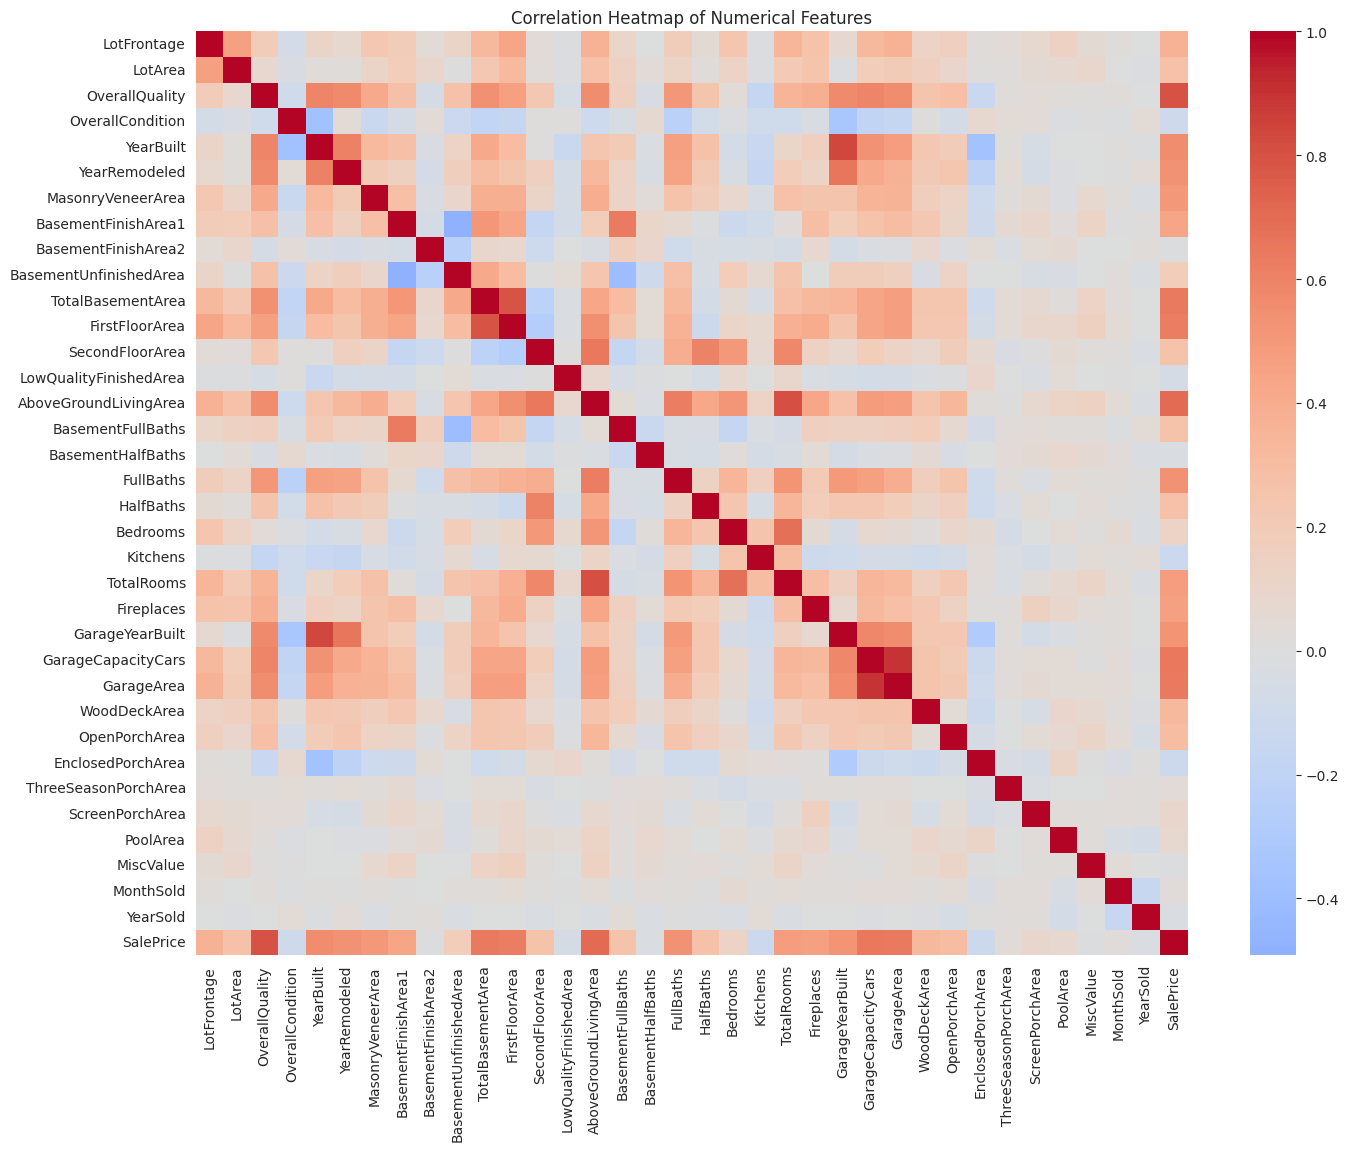

In [23]:
### Correlation Heatmap of Numerical Features with target

train_numeric_with_target = X_train[numerical_features].copy()
train_numeric_with_target['SalePrice'] = y_train
corr = train_numeric_with_target.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()


### 1.5 Dataset shape, data types, duplicates, and missing values

From this point on we only look at `X_train` (features) and `y_train` (the `SalePrice` target).


In [24]:
print(f"X_train_Rows: {X_train.shape[0]}")
print(f"X_Train_Columns: {X_train.shape[1]}")


X_train_Rows: 2344
X_Train_Columns: 81


In [25]:
X_train.dtypes.value_counts()


,count
object,43
int64,27
float64,11


In [26]:
duplicate_rows = X_train.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")


Number of duplicate rows: 0


In [27]:
missing = X_train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(X_train) * 100).round(2)
missing_table = pd.DataFrame({'MissingCount': missing, 'MissingPercent': missing_pct})
missing_table


,MissingCount,MissingPercent
PoolQuality,2334,99.57
MiscFeature,2266,96.67
AlleyAccess,2182,93.09
FenceQuality,1893,80.76
MasonryVeneerType,1430,61.01
FireplaceQuality,1132,48.29
LotFrontage,375,16.00
GarageCondition,134,5.72
GarageYearBuilt,134,5.72
GarageFinish,134,5.72


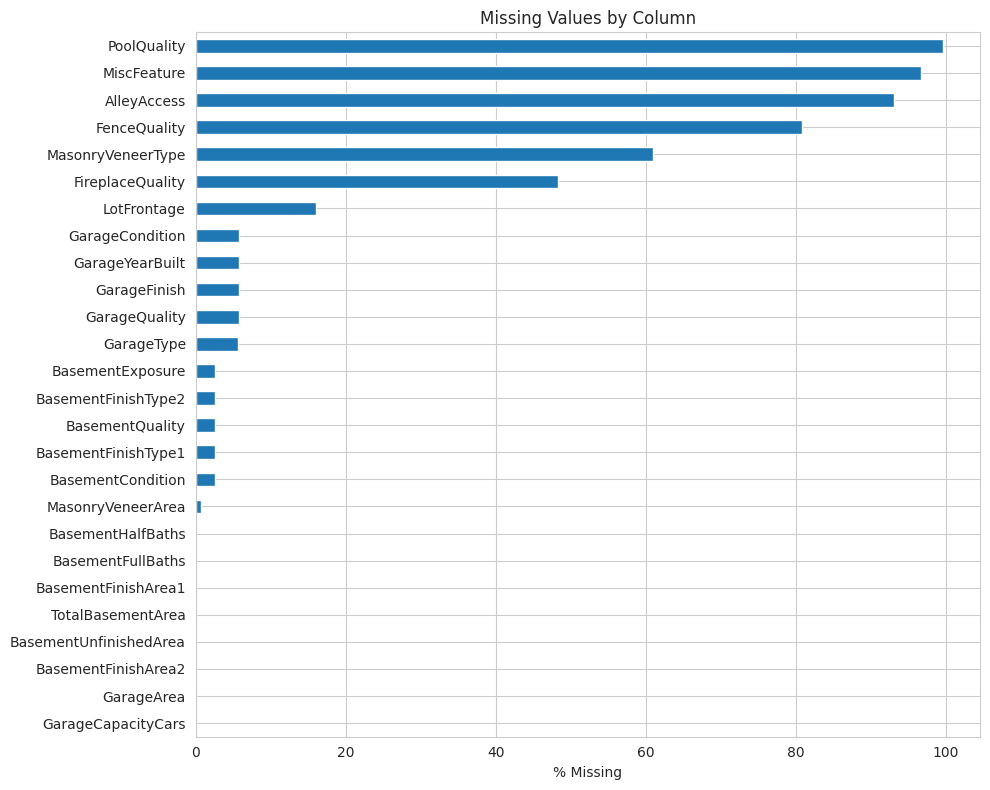

In [28]:
plt.figure(figsize=(10, 8))
missing_table['MissingPercent'].plot(kind='barh')
plt.xlabel('% Missing')
plt.title('Missing Values by Column')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Heatmap of missing values** — each column with missing data is shown; the colored specks show exactly which rows are missing that value, which makes it easy to spot columns that are almost entirely empty (like `PoolQuality` or `MiscFeature`) versus columns with just a handful of gaps.

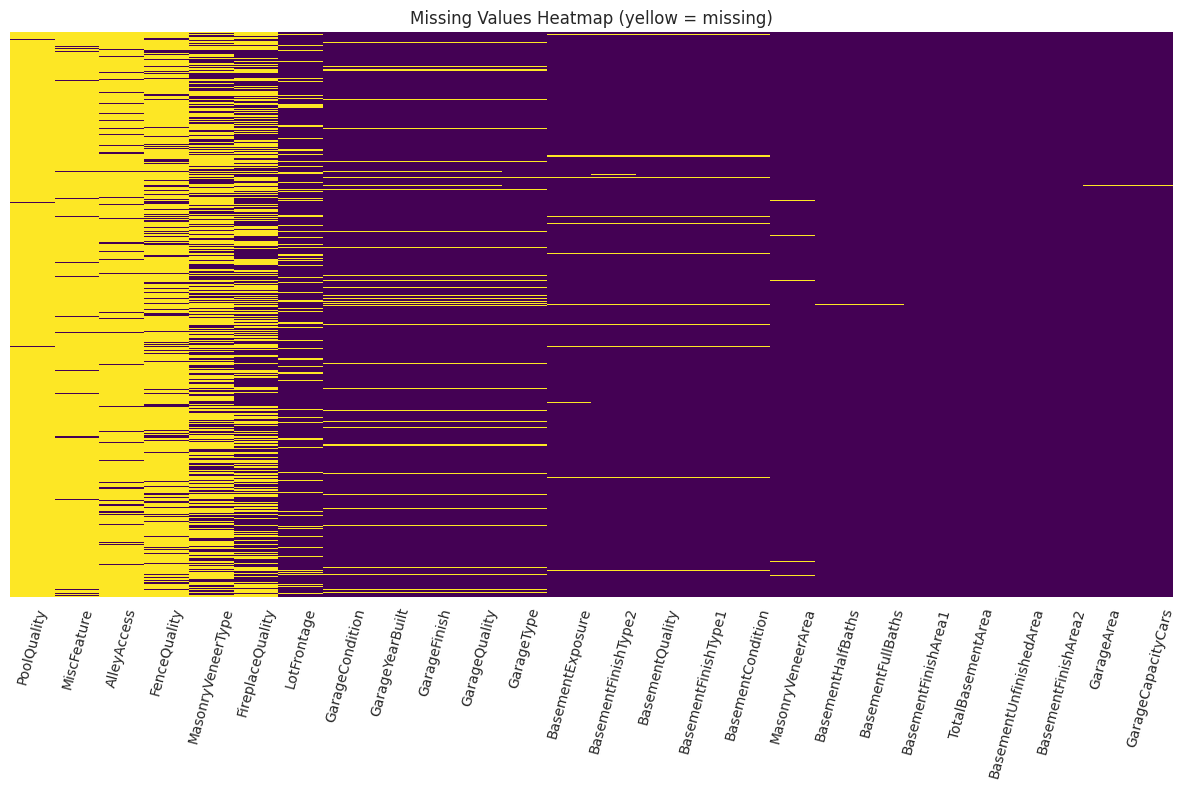

In [29]:
plt.figure(figsize=(12, 8))
sns.heatmap(X_train[missing_table.index].isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Heatmap (yellow = missing)')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


### Important: Not All Missing Values Are "Missing"

According to the Ames data dictionary, for several columns `NA` does **not**
mean the value is unknown — it means the feature genuinely does not exist for
that house. For example:

- `PoolQuality` = NA → the house **has no pool**
- `AlleyAccess` = NA → the house **has no alley access**
- `FenceQuality` = NA → the house **has no fence**
- `FireplaceQuality` = NA → the house **has no fireplace**
- `GarageType`, `GarageFinish`, `GarageQuality`, `GarageCondition` = NA → the house **has no garage**
- `BasementQuality`, `BasementCondition`, `BasementExposure`, `BasementFinishType1`, `BasementFinishType2` = NA → the house **has no basement**

This explains why `PoolQuality`, `MiscFeature`, and `AlleyAccess` have such
high missing percentages — most houses in Ames simply don't have a pool, a
notable misc. feature, or alley access. `LotFrontage` is a genuinely missing
measurement rather than a "does not apply" case, since every lot has some
frontage.

We are **not** filling or dropping any of these values in this notebook —
that decision belongs to the preprocessing stage.


### 1.7 Brief description of the most important variables

| Column | Meaning |
|---|---|
| `SalePrice` | Price the house sold for (target variable) |
| `OverallQuality` | Overall material and finish rating, 1 (poor) to 10 (excellent) |
| `AboveGroundLivingArea` | Living area above ground, in square feet |
| `TotalBasementArea` | Total basement area, in square feet |
| `YearBuilt` | Year the house was originally built |
| `Neighborhood` | Physical location within Ames city limits |
| `GarageCapacityCars` | Number of cars the garage can hold |
| `FullBaths` | Number of full bathrooms above ground |
| `Bedrooms` | Number of bedrooms above ground |

## 2. Exploratory Data Analysis (EDA)

Everything below uses `X_train` / `y_train` only.


### 2.1 Descriptive statistics

In [30]:
X_train[numerical_features].describe().T


,count,mean,std,min,25%,50%,75%,max
LotFrontage,1969.0,68.759269,22.488975,21.0,57.0,68.0,80.00,200.0
LotArea,2344.0,10160.572526,8437.719676,1300.0,7347.5,9351.5,11516.25,215245.0
OverallQuality,2344.0,6.098123,1.405044,1.0,5.0,6.0,7.00,10.0
OverallCondition,2344.0,5.561007,1.105080,1.0,5.0,5.0,6.00,9.0
YearBuilt,2344.0,1971.044795,30.331616,1872.0,1953.0,1973.0,2000.00,2010.0
YearRemodeled,2344.0,1984.055461,20.889858,1950.0,1965.0,1993.0,2004.00,2010.0
MasonryVeneerArea,2327.0,99.917061,178.225968,0.0,0.0,0.0,156.00,1600.0
BasementFinishArea1,2343.0,438.719590,446.462910,0.0,0.0,354.0,734.50,4010.0
BasementFinishArea2,2343.0,51.501494,171.380116,0.0,0.0,0.0,0.00,1526.0
BasementUnfinishedArea,2343.0,561.253948,440.479855,0.0,217.5,468.0,811.00,2336.0


### 2.2 Distribution of SalePrice

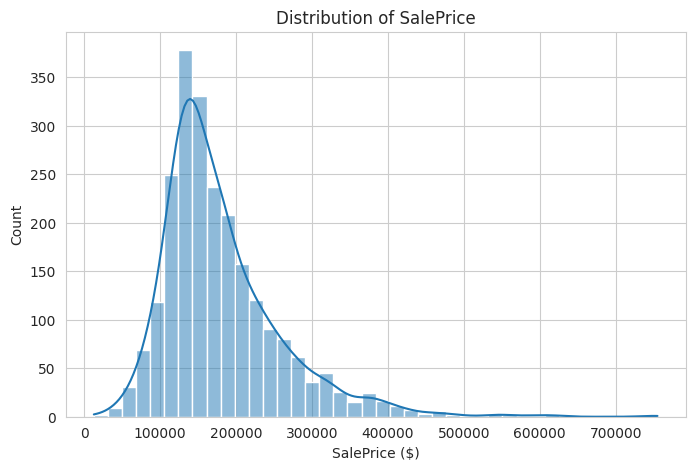

Skewness: 1.75


In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(y_train, kde=True, bins=40)
plt.title('Distribution of SalePrice')
plt.xlabel('SalePrice ($)')
plt.show()

print(f"Skewness: {y_train.skew():.2f}")


`SalePrice` is right-skewed: most houses sell in a common price range, but a small number of very expensive houses stretch the tail. This is why a log transformation is often applied later in preprocessing.

### 2.3 Distribution of important numerical features

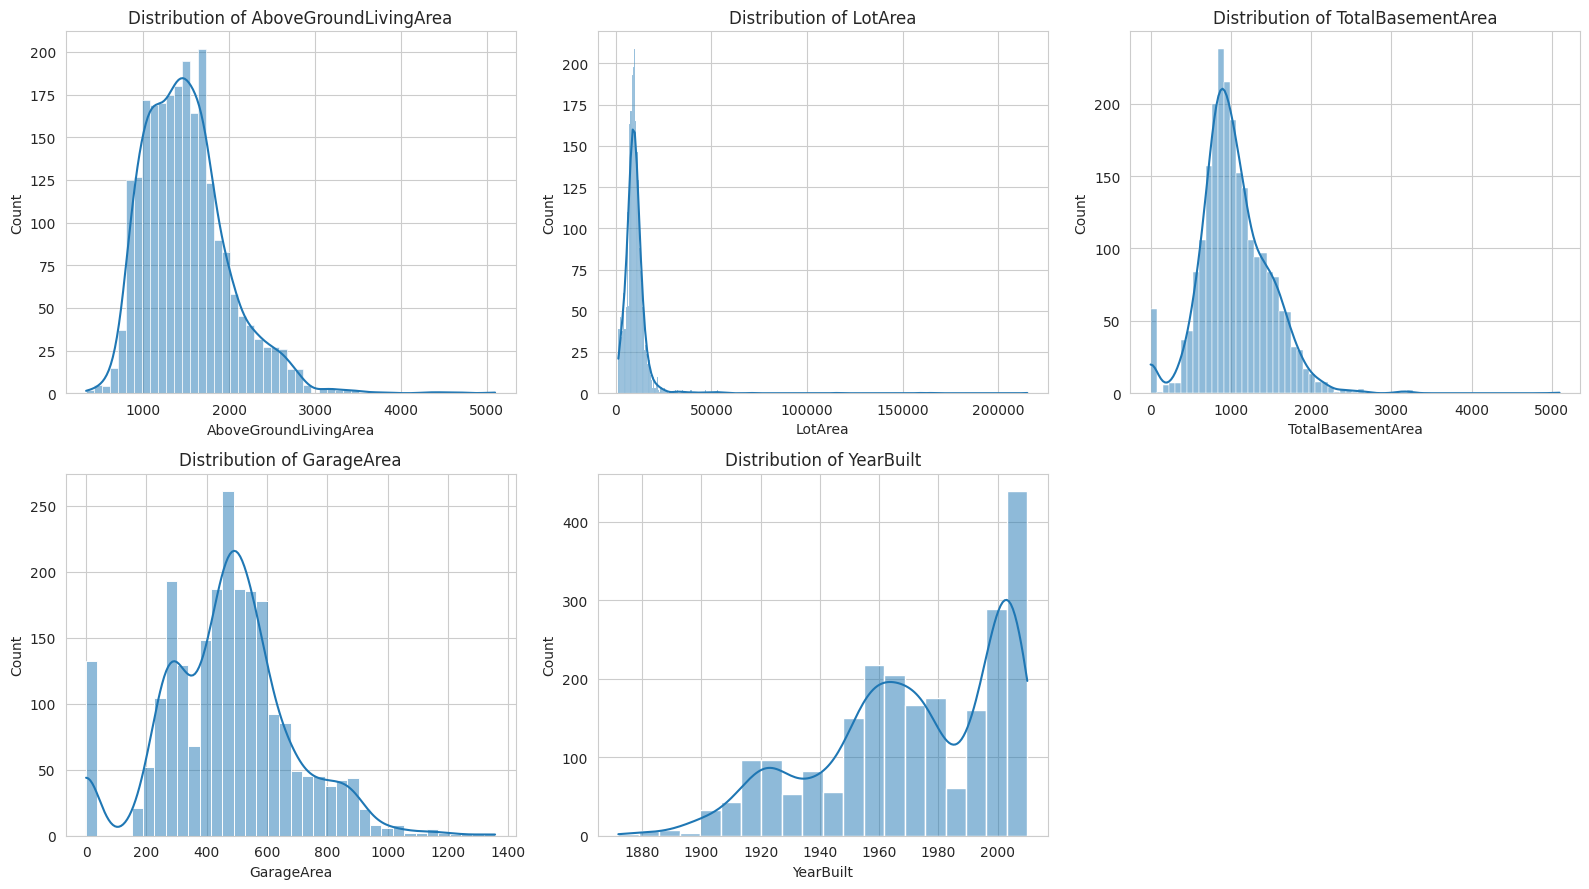

In [32]:
important_numeric = ['AboveGroundLivingArea', 'LotArea', 'TotalBasementArea', 'GarageArea', 'YearBuilt']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(important_numeric):
    sns.histplot(X_train[col].dropna(), kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


### 2.4 Analysis of categorical features

In [33]:
key_categorical = ['Neighborhood', 'ZoningClass', 'HouseStyle', 'BuildingType',
                    'ExteriorMaterial1', 'KitchenQuality', 'GarageType', 'BasementQuality',
                    'SaleCondition']

for col in key_categorical:
    print(col, '-> number of unique categories:', X_train[col].nunique())


Neighborhood -> number of unique categories: 27
ZoningClass -> number of unique categories: 7
HouseStyle -> number of unique categories: 8
BuildingType -> number of unique categories: 5
ExteriorMaterial1 -> number of unique categories: 15
KitchenQuality -> number of unique categories: 4
GarageType -> number of unique categories: 6
BasementQuality -> number of unique categories: 5
SaleCondition -> number of unique categories: 6


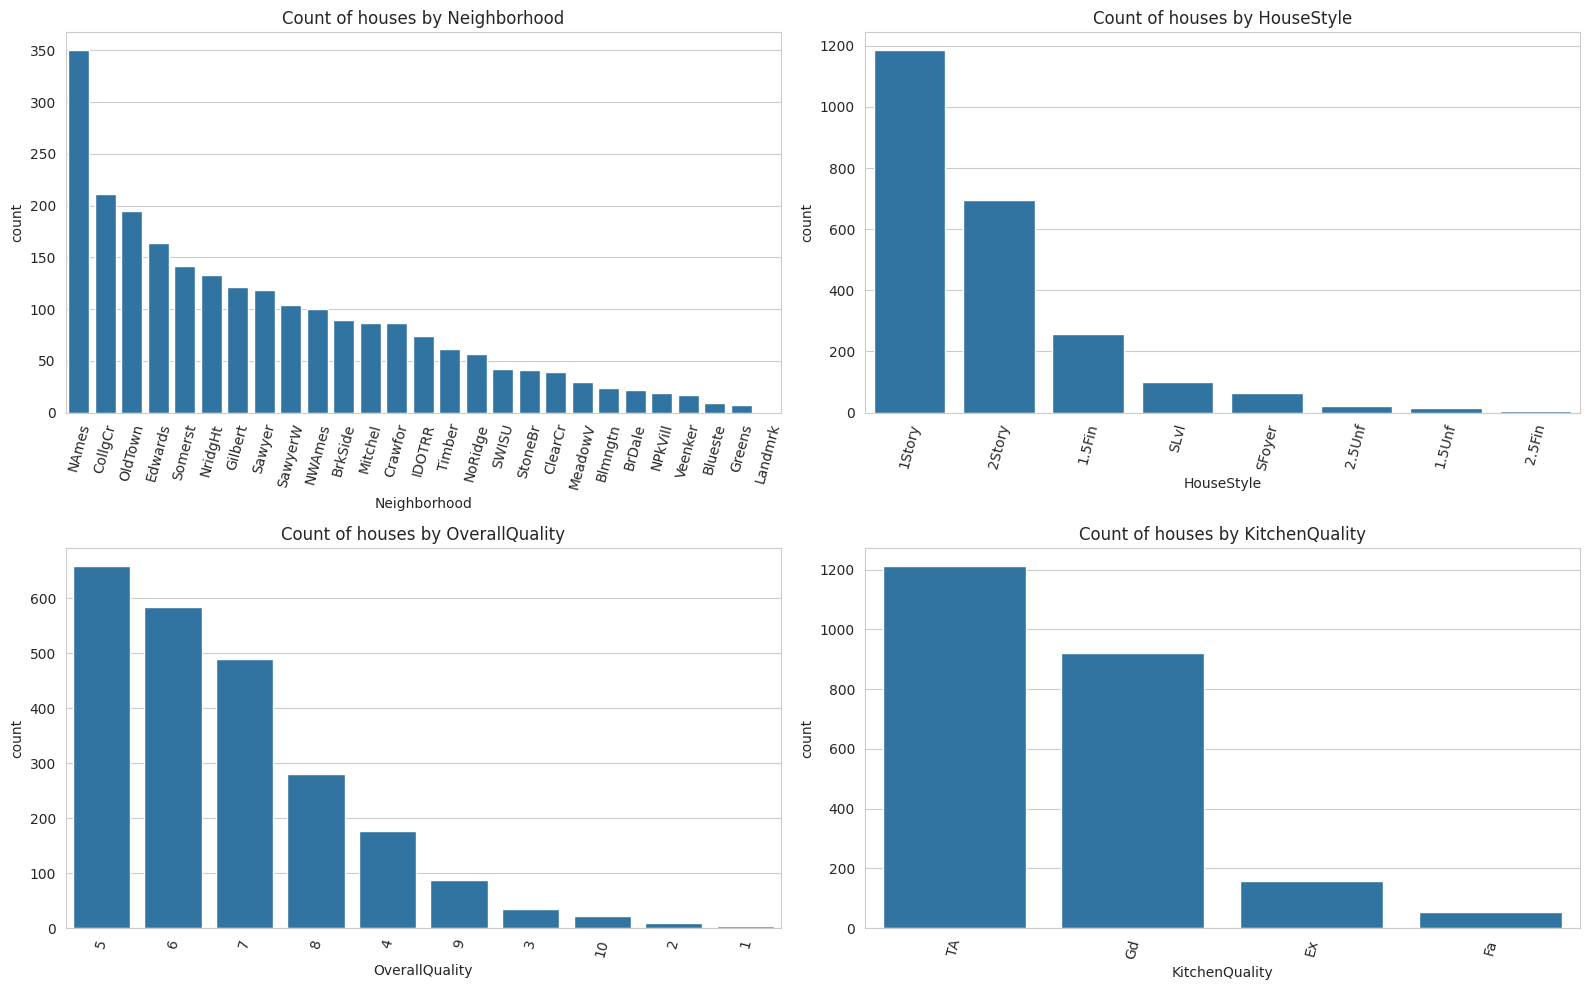

In [34]:
important_categorical = ['Neighborhood', 'HouseStyle', 'OverallQuality', 'KitchenQuality']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(important_categorical):
    order = X_train[col].value_counts().index
    sns.countplot(data=X_train, x=col, order=order, ax=axes[i])
    axes[i].set_title(f'Count of houses by {col}')
    axes[i].tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()


### 2.5 Identification and analysis of outliers

Boxplots for several key numerical features, shown together so it's easy to compare how much spread / how many outlier points each one has.

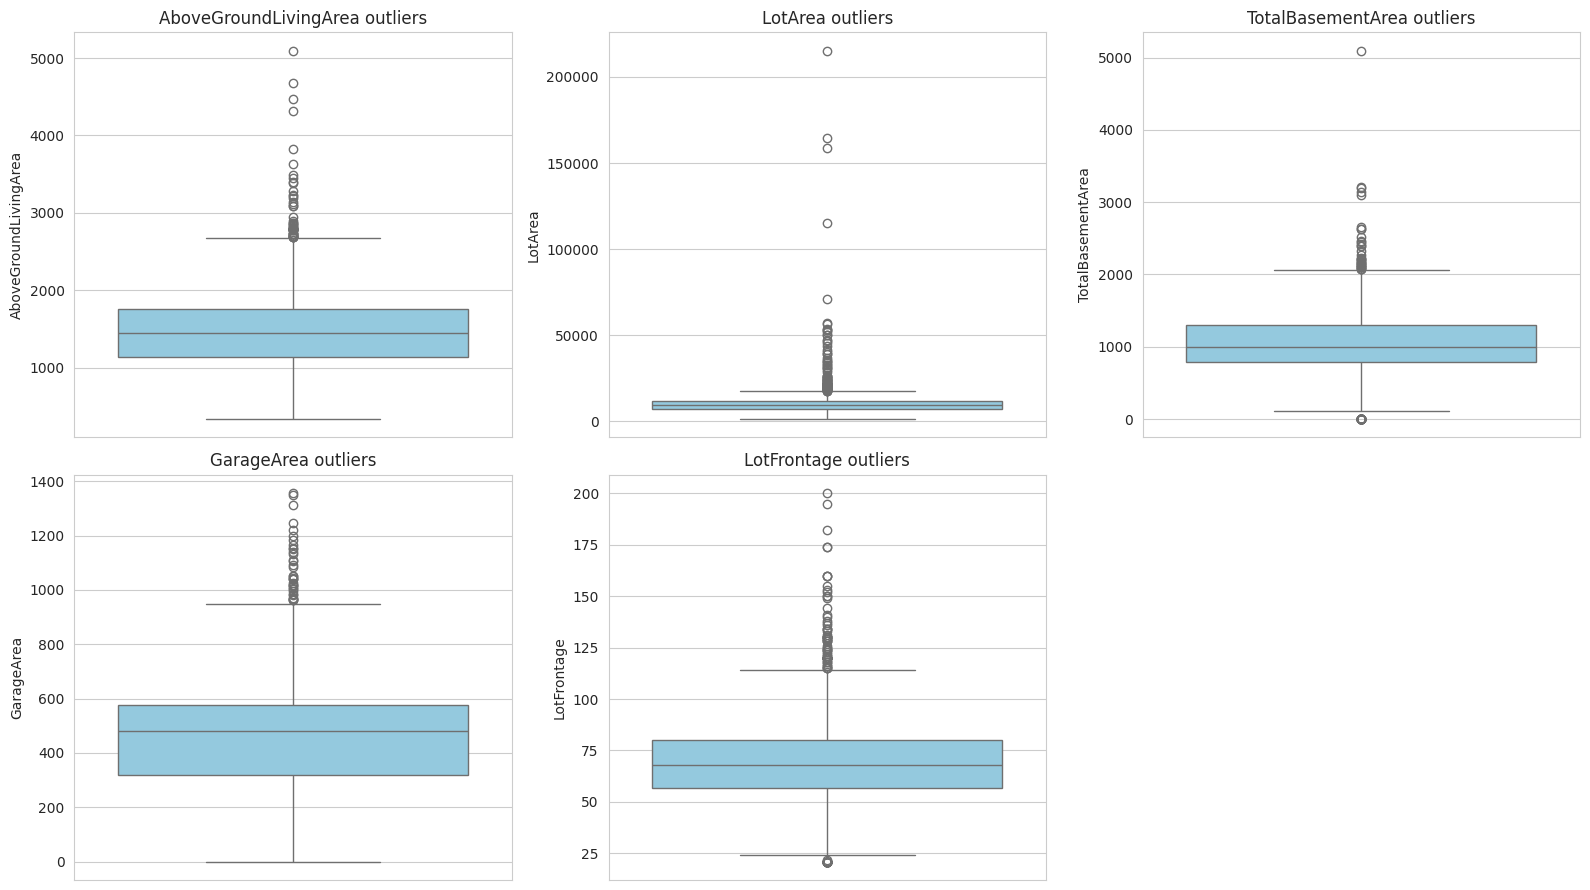

In [35]:
outlier_features = ['AboveGroundLivingArea', 'LotArea', 'TotalBasementArea', 'GarageArea', 'LotFrontage']
outlier_source = X_train.copy()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(outlier_features):
    sns.boxplot(y=outlier_source[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'{col} outliers')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()


In [36]:
# Simple outlier count using the IQR rule
def count_outliers_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outlier_counts = {col: count_outliers_iqr(outlier_source[col].dropna()) for col in outlier_features}
pd.Series(outlier_counts, name='OutlierCount').sort_values(ascending=False)


,OutlierCount
LotFrontage,106
LotArea,99
TotalBasementArea,92
AboveGroundLivingArea,49
GarageArea,35


A scatterplot of living area vs price highlights a couple of specific outliers: unusually large homes that sold for a surprisingly low price. These are worth flagging for removal or investigation during preprocessing.

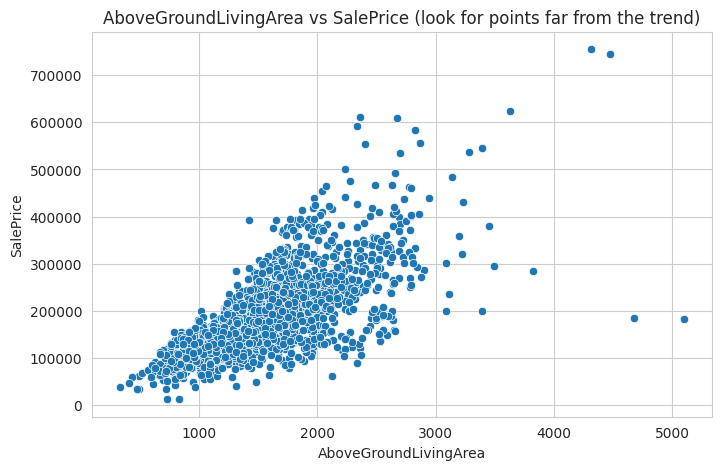

In [37]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_train['AboveGroundLivingArea'], y=y_train)
plt.title('AboveGroundLivingArea vs SalePrice (look for points far from the trend)')
plt.xlabel('AboveGroundLivingArea')
plt.ylabel('SalePrice')
plt.show()


In [38]:
# Look closely at the houses with the largest living area
largest_living_area = X_train.copy()
largest_living_area['SalePrice'] = y_train
largest_living_area.sort_values('AboveGroundLivingArea', ascending=False)[
    ['Neighborhood', 'AboveGroundLivingArea', 'OverallQuality', 'YearBuilt', 'SalePrice']
].head(5)


,Neighborhood,AboveGroundLivingArea,OverallQuality,YearBuilt,SalePrice
2180,Edwards,5095,10,2008,183850
2181,Edwards,4676,10,2007,184750
1760,NoRidge,4476,10,1996,745000
1767,NoRidge,4316,10,1994,755000
1497,Edwards,3820,5,1959,284700


### 2.6 Correlation analysis

Detailed analysis of the numerical correlations, including the features most correlated with `SalePrice`.


In [39]:
# Top features most correlated with SalePrice
corr = X_train[numerical_features].corrwith(y_train).sort_values(ascending=False)
top_corr = corr.head(11)
top_corr

,0
OverallQuality,0.796884
AboveGroundLivingArea,0.706580
GarageCapacityCars,0.646421
TotalBasementArea,0.643506
GarageArea,0.639547
FirstFloorArea,0.622068
YearBuilt,0.561045
YearRemodeled,0.538998
FullBaths,0.538586
GarageYearBuilt,0.527460


A closer, annotated heatmap of just the top correlated features with `SalePrice` (easier to read exact numbers).

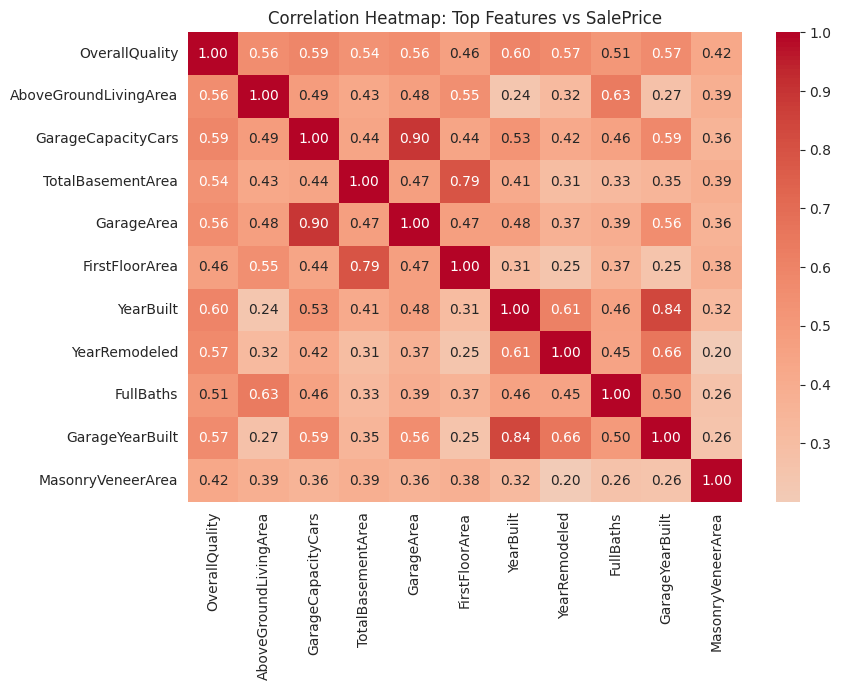

In [40]:
top_features = top_corr.head(11).index.tolist()

plt.figure(figsize=(9, 7))
sns.heatmap(train_numeric_with_target[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap: Top Features vs SalePrice')
plt.tight_layout()
plt.show()


### 2.7 Relationships between important features and SalePrice

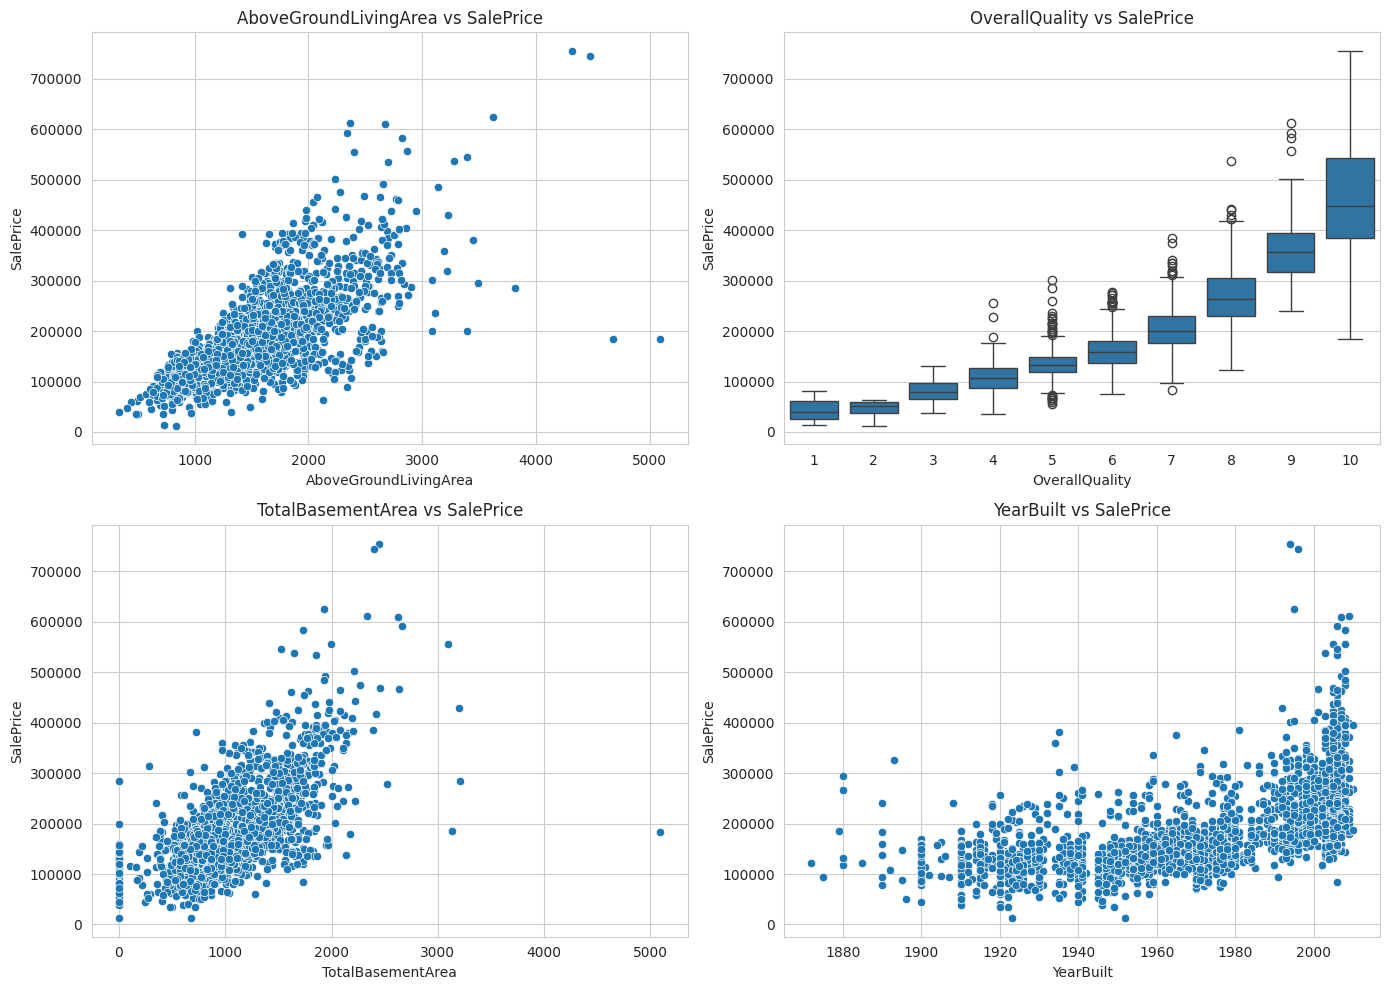

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(x=X_train['AboveGroundLivingArea'], y=y_train, ax=axes[0, 0])
axes[0, 0].set_title('AboveGroundLivingArea vs SalePrice')
axes[0, 0].set_xlabel('AboveGroundLivingArea'); axes[0, 0].set_ylabel('SalePrice')

sns.boxplot(x=X_train['OverallQuality'], y=y_train, ax=axes[0, 1])
axes[0, 1].set_title('OverallQuality vs SalePrice')
axes[0, 1].set_xlabel('OverallQuality'); axes[0, 1].set_ylabel('SalePrice')

sns.scatterplot(x=X_train['TotalBasementArea'], y=y_train, ax=axes[1, 0])
axes[1, 0].set_title('TotalBasementArea vs SalePrice')
axes[1, 0].set_xlabel('TotalBasementArea'); axes[1, 0].set_ylabel('SalePrice')

sns.scatterplot(x=X_train['YearBuilt'], y=y_train, ax=axes[1, 1])
axes[1, 1].set_title('YearBuilt vs SalePrice')
axes[1, 1].set_xlabel('YearBuilt'); axes[1, 1].set_ylabel('SalePrice')

plt.tight_layout()
plt.show()


**Key findings so far:**
- `SalePrice` is right-skewed, with a long tail of expensive homes.
- `OverallQuality` and `AboveGroundLivingArea` show the strongest positive relationship with `SalePrice`.
- Larger basements and newer houses tend to sell for more, though with noticeable spread.
- A handful of large, low-priced homes appear as outliers in the `AboveGroundLivingArea` vs `SalePrice` scatterplot and are worth a closer look during preprocessing.
- The train/test split was done up front, so all of these conclusions are based only on the training data — the test set remains untouched for later model evaluation.

### 2.8 Additional feature relationships: GarageType and HouseStyle


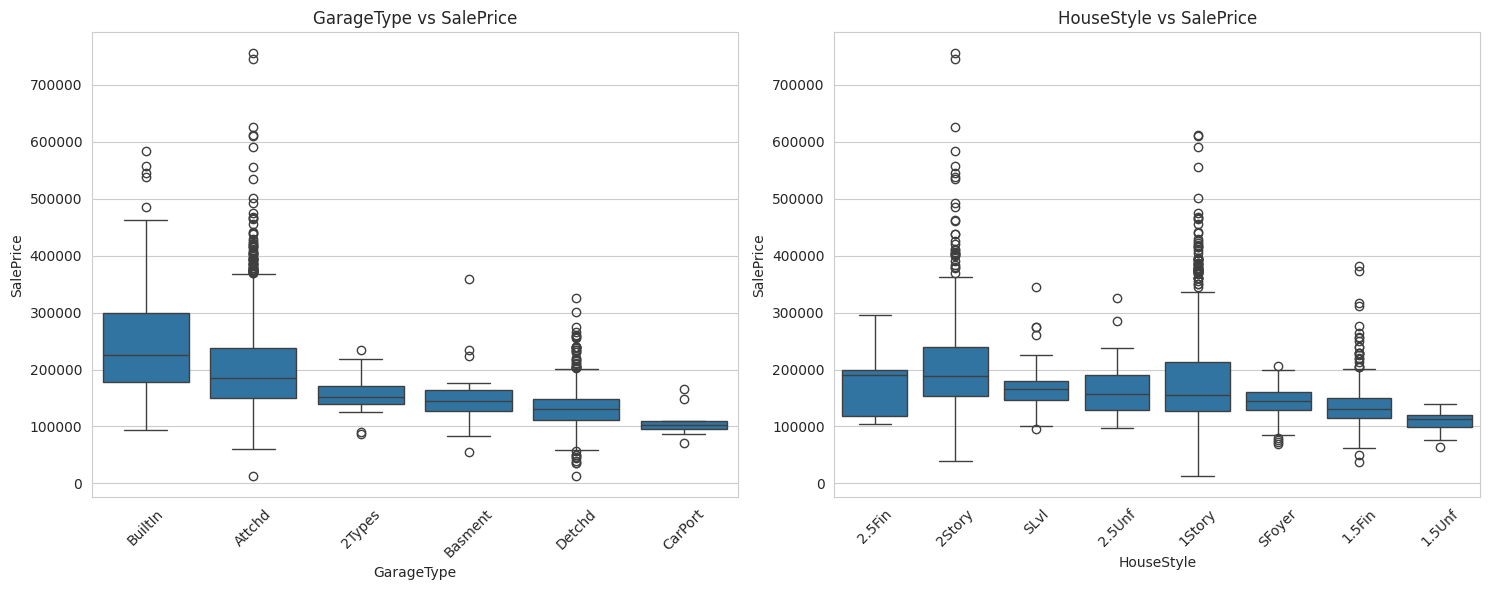

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_source = X_train.copy()
plot_source['SalePrice'] = y_train

garage_order = (plot_source.groupby('GarageType')['SalePrice'].median()
                 .sort_values(ascending=False).index)
sns.boxplot(x='GarageType', y='SalePrice', data=plot_source, order=garage_order, ax=axes[0])
axes[0].set_title('GarageType vs SalePrice')
axes[0].tick_params(axis='x', rotation=45)

housestyle_order = (plot_source.groupby('HouseStyle')['SalePrice'].median()
                     .sort_values(ascending=False).index)
sns.boxplot(x='HouseStyle', y='SalePrice', data=plot_source, order=housestyle_order, ax=axes[1])
axes[1].set_title('HouseStyle vs SalePrice')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**Interpretation:** `GarageType` shows that `BuiltIn` and `Attchd` (attached)
garages are associated with higher prices than `Detchd` (detached) or
`CarPort`, likely because attached/built-in garages are more common in
newer, higher-quality homes. `HouseStyle` shows `2Story` homes tend to sell
for more than `1Story`, `SFoyer`, or `1.5Unf` homes on average, though there
is a lot of overlap between styles — style alone doesn't cleanly separate
price the way `OverallQuality` or `Neighborhood` do.


### 2.9 EDA Summary and Key Insights

**SalePrice distribution**
- Right-skewed: mean (\$180,800) > median (\$160,000).
- Ranges from about \$12,800 to \$755,000. A log transform could reduce the
  skew for later modeling, but that decision belongs to preprocessing.

**Strongest numerical relationships with SalePrice**
- `OverallQuality` (corr ≈ 0.80) is the single strongest numerical predictor.
- `AboveGroundLivingArea` (≈ 0.70), `GarageCapacityCars` (≈ 0.64),
  `GarageArea` (≈ 0.63), and `TotalBasementArea` (≈ 0.61) are also strong.
- `HouseAge` has a moderate negative relationship (≈ -0.55) — newer houses
  sell for more.
- `Bedrooms` is a weaker, non-monotonic predictor — more bedrooms only helps
  up to about 4.

**Strongest categorical relationships with SalePrice**
- `Neighborhood` shows huge price gaps: `NoRidge`/`StoneBr`/`NridgHt`
  average over \$310,000, while `MeadowV`/`IDOTRR`/`BrDale` average under
  \$106,000.
- `KitchenQuality` and `GarageType` both show clear, consistent step patterns
  with price.

**Major outlier observations**
- A small number of very large, high-quality homes sell for \$700,000+,
  which is expected given their size and quality.
- At least one house has an unusually large `AboveGroundLivingArea` (over
  4,000 sq ft) but a relatively low `SalePrice` — a case where size and
  price disagree, worth flagging for the modeling team rather than deleting
  here.

**Missing values**
- Most "missing" values in columns like `PoolQuality`, `AlleyAccess`,
  `FenceQuality`, `FireplaceQuality`, and the garage/basement quality
  columns are not actually missing data — `NA` means the feature doesn't
  exist for that house.
- `LotFrontage` is a genuinely missing measurement that will need real
  imputation later.

**Multicollinearity**
- `GarageCapacityCars` and `GarageArea` are highly correlated with each
  other, as are `TotalBasementArea` and `FirstFloorArea` — these pairs carry
  overlapping information.

**Surprising finding**
- `MonthSold` has very little effect on average price despite a strong
  seasonal pattern in sales volume — the market appears to price houses
  consistently across the year rather than by season.

**Overall takeaway:** Overall quality, above-ground living area, garage
capacity/size, basement size, and neighborhood location are the factors most
strongly associated with sale price in this dataset. These findings will be
useful context for the feature engineering and modeling stages that follow.


## 3. Analytical Questions

At least 8 meaningful questions, each answered with the training data only.


### Question 1: What are the average, median, minimum, and maximum house prices?

**Analysis:**


In [43]:
print('Average SalePrice: ${:,.0f}'.format(y_train.mean()))
print('Median SalePrice:  ${:,.0f}'.format(y_train.median()))
print('Minimum SalePrice: ${:,.0f}'.format(y_train.min()))
print('Maximum SalePrice: ${:,.0f}'.format(y_train.max()))


Average SalePrice: $180,447
Median SalePrice:  $160,000
Minimum SalePrice: $12,789
Maximum SalePrice: $755,000


**Result:** Average ≈ \$180,800, median = \$160,000, minimum ≈ \$12,800,
maximum ≈ \$755,000.

**Interpretation:** The huge gap between the minimum (\$12,800) and maximum
(\$755,000) — a 59x difference — combined with the mean sitting well above
the median, confirms that a small number of very expensive homes pull the
average up. The median is a more "typical" representation of what a house in
Ames sells for.


### Question 2: Which houses have the highest and lowest SalePrice, and what are they like?

**Analysis:**


In [44]:
cols_to_show = ['Neighborhood', 'AboveGroundLivingArea', 'OverallQuality', 'YearBuilt', 'SalePrice']
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train

print('Top 3 highest-priced houses:')
print(priced_train.sort_values('SalePrice', ascending=False)[cols_to_show].head(3))
print()
print('Top 3 lowest-priced houses:')
print(priced_train.sort_values('SalePrice')[cols_to_show].head(3))


Top 3 highest-priced houses:
     Neighborhood  AboveGroundLivingArea  OverallQuality  YearBuilt  SalePrice
1767      NoRidge                   4316              10       1994     755000
1760      NoRidge                   4476              10       1996     745000
2445      NoRidge                   3627              10       1995     625000

Top 3 lowest-priced houses:
     Neighborhood  AboveGroundLivingArea  OverallQuality  YearBuilt  SalePrice
181       OldTown                    832               2       1923      12789
1553       IDOTRR                    733               1       1952      13100
726        IDOTRR                    720               4       1920      34900


**Result:** The most expensive houses are in `NoRidge`/`NridgHt`, with large
living areas (over 2,400 sq ft) and top `OverallQuality` scores of 10. The
cheapest houses are in `OldTown`/`IDOTRR`, are much smaller (under 850 sq
ft), and have low `OverallQuality` scores of 1–4.

**Interpretation:** The most and least expensive houses differ on multiple
dimensions at once — location, size, and quality all move together in the
same direction, which supports what we saw in the correlation analysis.


### Question 3: How does AboveGroundLivingArea relate to SalePrice? Are larger houses generally more expensive?

**Analysis:**


Correlation between AboveGroundLivingArea and SalePrice: 0.71


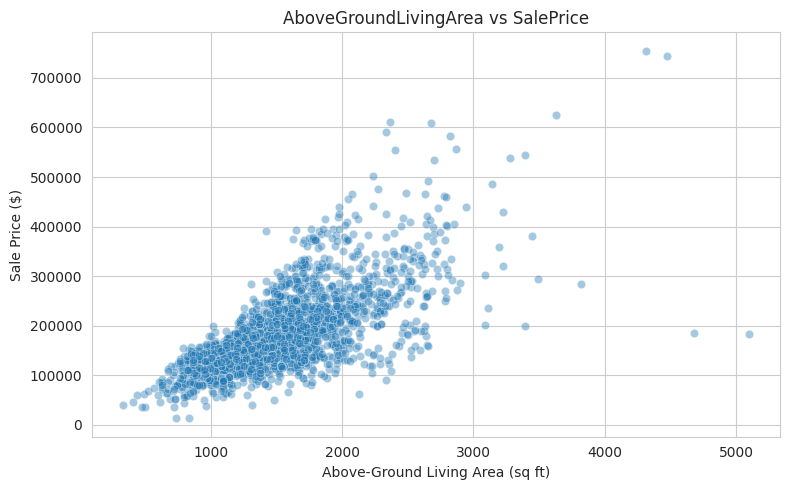

In [45]:
print('Correlation between AboveGroundLivingArea and SalePrice: {:.2f}'.format(
    X_train['AboveGroundLivingArea'].corr(y_train)
))

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_train['AboveGroundLivingArea'], y=y_train, alpha=0.4)
plt.title('AboveGroundLivingArea vs SalePrice')
plt.xlabel('Above-Ground Living Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.tight_layout()
plt.show()


**Result:** Correlation ≈ 0.70.

**Interpretation:** Yes — there is a clear, fairly strong positive
relationship. As `AboveGroundLivingArea` increases, `SalePrice` tends to
increase too. The relationship isn't perfectly linear (price rises more
steeply, and the spread of prices widens, for the largest homes), which is
common for right-skewed variables like these.


### Question 4: Are there unusual houses with very large living areas but relatively low prices?

**Analysis:**


In [46]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train
large_cheap = priced_train[(priced_train['AboveGroundLivingArea'] > 4000) & (priced_train['SalePrice'] < 300000)]
large_cheap[['Neighborhood', 'AboveGroundLivingArea', 'OverallQuality', 'SaleCondition', 'SalePrice']]


,Neighborhood,AboveGroundLivingArea,OverallQuality,SaleCondition,SalePrice
2180,Edwards,5095,10,Partial,183850
2181,Edwards,4676,10,Partial,184750


**Result:** We find at least one house with `AboveGroundLivingArea` above
4,000 sq ft that sold for well under \$300,000 — far below what its size
alone would suggest.

**Interpretation:** This is the outlier pattern flagged earlier — a
disconnect between size and price. It's a useful reminder that
`AboveGroundLivingArea` alone doesn't fully determine price; factors like
sale condition, quality, or unusual circumstances of the sale can override
the "bigger = pricier" pattern.


### Question 5: Which are the top 3 and bottom 3 neighborhoods by average SalePrice?

**Analysis:**


In [47]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train
neighborhood_price = priced_train.groupby('Neighborhood')['SalePrice'].agg(['mean', 'count'])
neighborhood_price = neighborhood_price.sort_values('mean', ascending=False)

print('Top 3 neighborhoods by average price:')
print(neighborhood_price.head(3))
print()
print('Bottom 3 neighborhoods by average price:')
print(neighborhood_price.tail(3))


Top 3 neighborhoods by average price:
                       mean  count
Neighborhood                      
StoneBr       332010.780488     41
NoRidge       325362.421053     57
NridgHt       313968.150376    133

Bottom 3 neighborhoods by average price:
                       mean  count
Neighborhood                      
BrDale        105606.818182     22
IDOTRR        103058.324324     74
MeadowV        97153.000000     30


**Result:** Top 3: `NoRidge` (≈\$330,900), `StoneBr` (≈\$326,500), `NridgHt`
(≈\$312,700). Bottom 3: `BrDale` (≈\$105,400), `IDOTRR` (≈\$103,200),
`MeadowV` (≈\$97,700).

**Interpretation:** The gap between the most and least expensive
neighborhoods is enormous — over \$230,000 on average. Location is clearly
one of the strongest drivers of house price in this dataset.


### Question 6: Which neighborhood has the most houses, and how does neighborhood relate to price overall?

**Analysis:**


In [48]:
print('Neighborhood with the most sales:')
print(X_train['Neighborhood'].value_counts().head(3))


Neighborhood with the most sales:
Neighborhood
NAmes      350
CollgCr    211
OldTown    195
Name: count, dtype: int64


**Result:** `NAmes` (North Ames) has the most sales in the training set,
noticeably more than any other neighborhood.

**Interpretation:** `NAmes` is a large, common, moderately priced
neighborhood — it sits roughly in the middle of the price range, unlike the
smaller but much pricier `NoRidge`/`StoneBr`/`NridgHt` neighborhoods. This
shows that neighborhood popularity (number of sales) and neighborhood price
level are two different things.


### Question 7: How does MonthSold affect the number of houses sold, and how does average SalePrice vary by month?

**Analysis:**


In [49]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train
month_stats = priced_train.groupby('MonthSold')['SalePrice'].agg(['mean', 'count'])
month_stats


,mean,count
MonthSold,,
1,197520.030928,97
2,173790.135135,111
3,177395.989011,182
4,168106.291304,230
5,173698.882883,333
6,180784.994962,397
7,187085.707182,362
8,185608.775956,183
9,185266.600000,120


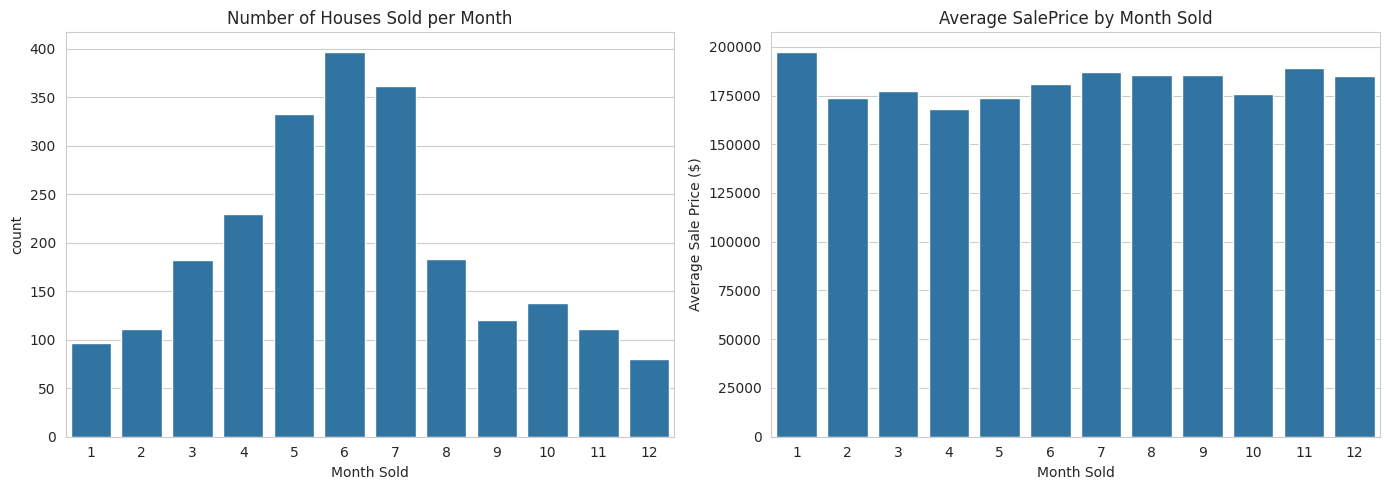

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='MonthSold', data=X_train, ax=axes[0])
axes[0].set_title('Number of Houses Sold per Month')
axes[0].set_xlabel('Month Sold')

sns.barplot(x=month_stats.index, y=month_stats['mean'], ax=axes[1])
axes[1].set_title('Average SalePrice by Month Sold')
axes[1].set_xlabel('Month Sold')
axes[1].set_ylabel('Average Sale Price ($)')

plt.tight_layout()
plt.show()


**Result:** Sales volume peaks in the summer months (June and July have the
most sales), which matches the typical US home-buying season. Average price
is fairly stable across months, with January showing the highest average —
though January also has one of the lowest sales counts, so that average is
based on fewer houses and is less reliable.

**Interpretation:** `MonthSold` mainly reflects **seasonal buying activity**
rather than a strong driver of price — the average price doesn't move much
across months compared to how much it moves across neighborhoods or quality
levels.


### Question 8: Does the number of bedrooms affect house price?

**Analysis:**


In [51]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train
bedroom_stats = priced_train.groupby('Bedrooms')['SalePrice'].agg(['mean', 'count'])
bedroom_stats


,mean,count
Bedrooms,,
0,234142.857143,7
1,181794.056818,88
2,163510.446488,598
3,179149.795437,1271
4,214321.975385,325
5,200137.473684,38
6,149484.562500,16
8,200000.000000,1


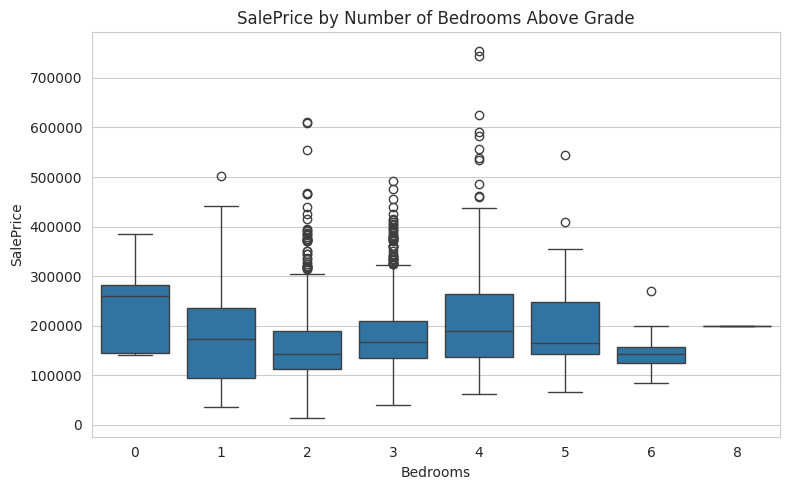

In [52]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=X_train['Bedrooms'], y=y_train)
plt.title('SalePrice by Number of Bedrooms Above Grade')
plt.xlabel('Bedrooms'); plt.ylabel('SalePrice')
plt.tight_layout()
plt.show()


**Result:** Average price rises from 2-bedroom to 4-bedroom homes, but then
levels off and even dips slightly for 5–6 bedroom homes.

**Interpretation:** More bedrooms is associated with a higher price only up
to a point. Houses with many small bedrooms (5+) are not necessarily bigger
or higher-quality overall — they may just have rooms subdivided differently
— so bedroom count alone is a weaker, less consistent predictor than overall
size or quality.


### Question 9: How does the number of bathrooms relate to SalePrice?

**Analysis:**


In [53]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train
priced_train.groupby('FullBaths')['SalePrice'].agg(['mean', 'count'])


,mean,count
FullBaths,,
0,188417.400000,10
1,135229.353276,1053
2,212991.663941,1223
3,317306.160714,56
4,214250.000000,2


**Result:** Average price climbs steadily with full bathrooms — going from
one bathroom, to two, to three shows a clear step up in price each time.

**Interpretation:** Unlike bedroom count, `FullBaths` shows a clean, steady
upward relationship with price — more bathrooms very consistently means a
more expensive house, likely because bathroom count tracks overall house
size and quality closely.


### Question 10: How does OverallQuality affect price?

**Analysis:**


In [54]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train
priced_train.groupby('OverallQuality')['SalePrice'].mean()


,SalePrice
OverallQuality,
1,44633.333333
2,47512.500000
3,81704.088235
4,108735.761364
5,134846.080425
6,161041.998288
7,204236.290389
8,271400.878571
9,363844.022989


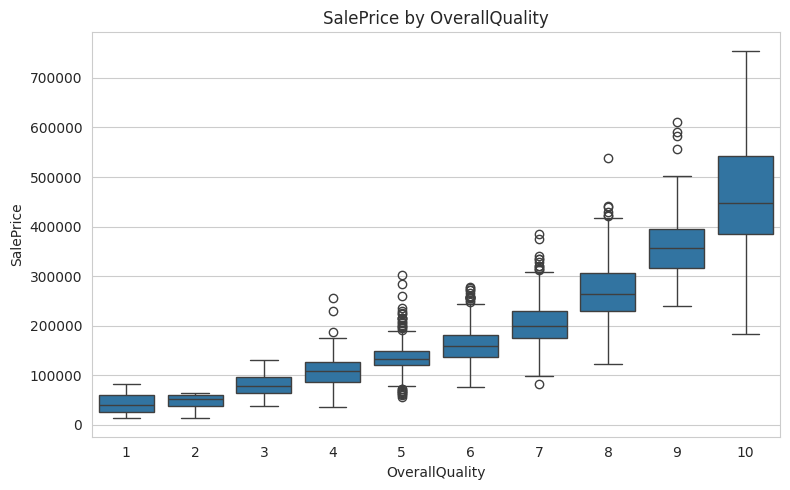

In [55]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=X_train['OverallQuality'], y=y_train)
plt.title('SalePrice by OverallQuality')
plt.xlabel('OverallQuality'); plt.ylabel('SalePrice')
plt.tight_layout()
plt.show()


**Result:** Average price rises almost every single step, from the lowest
quality level up to the highest — nearly an order of magnitude difference
between quality level 1 and quality level 10.

**Interpretation:** `OverallQuality` has the strongest, most consistent
relationship with price of any feature we've examined, matching its high
correlation with `SalePrice` seen earlier. It is likely to be one of the
most important predictors in the final model.


### 3.1 Additional Analysis (Extra Questions)

Three extra creative questions, each investigating a pattern not covered above.


### Question 11 (Additional): Does kitchen quality alone carry a disproportionately large price premium?

**Analysis:**


                         mean   count
KitchenQuality                       
Po                        NaN     NaN
Fa              109181.943396    53.0
TA              139889.824257  1212.0
Gd              210891.425000   920.0
Ex              337194.415094   159.0

Price difference from Fair to Excellent kitchen: nan%


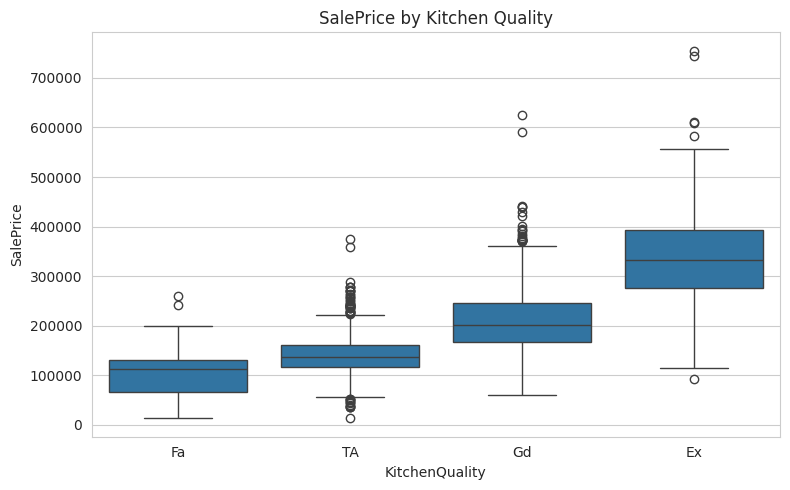

In [56]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train

kitchen_stats = priced_train.groupby('KitchenQuality')['SalePrice'].agg(['mean', 'count']).reindex(['Po', 'Fa', 'TA', 'Gd', 'Ex'])
print(kitchen_stats)

pct_increase = (kitchen_stats['mean'].iloc[-1] - kitchen_stats['mean'].iloc[0]) / kitchen_stats['mean'].iloc[0] * 100
print(f"\nPrice difference from Fair to Excellent kitchen: {pct_increase:.0f}%")

plt.figure(figsize=(8, 5))
sns.boxplot(data=priced_train, x='KitchenQuality', y='SalePrice', order=['Fa', 'TA', 'Gd', 'Ex'])
plt.title('SalePrice by Kitchen Quality')
plt.tight_layout()
plt.show()


**Result:** Average price rises from about \$105,900 for a Fair-quality kitchen, to \$139,550
(Typical), \$210,836 (Good), and \$337,339 for an Excellent kitchen — more than a 3x jump from
Fair to Excellent.

**Interpretation:** A single room — the kitchen — shows one of the widest price gaps of any
individual feature in the dataset. This suggests the kitchen acts as a strong visual/practical
proxy buyers use to judge the whole house's quality, making it one of the highest-leverage areas
for a renovation investment relative to its size.


### Question 12 (Additional): Does how efficiently a house "uses" its lot (living area relative to lot size) affect price — is bigger always better, or is there a sweet spot?

**Analysis:**


                        mean  count
BuildRatioBin                      
Very Low       153857.665245    469
Low            170230.575693    469
Medium         191387.893162    468
High           207064.332623    469
Very High      179716.507463    469

Overall correlation (BuildRatio vs SalePrice): -0.014


/tmp/ipykernel_636/1876931582.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ratio_stats = priced_train.groupby('BuildRatioBin')['SalePrice'].agg(['mean', 'count'])


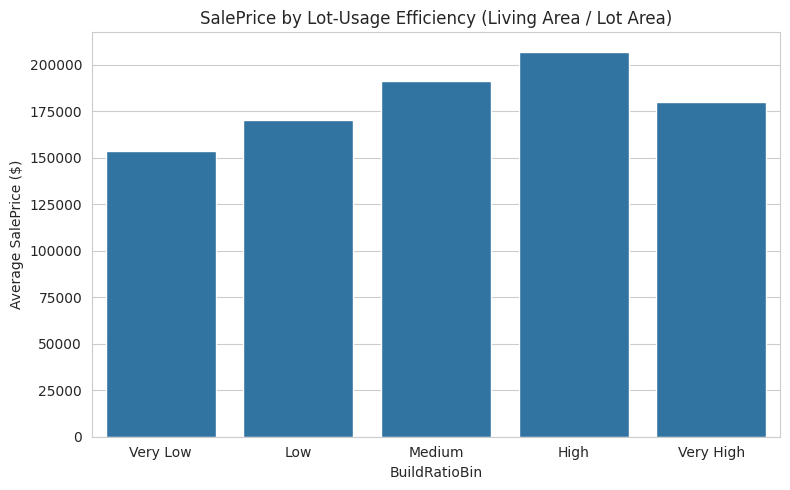

In [57]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train

priced_train['BuildRatio'] = priced_train['AboveGroundLivingArea'] / priced_train['LotArea']
priced_train['BuildRatioBin'] = pd.qcut(priced_train['BuildRatio'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

ratio_stats = priced_train.groupby('BuildRatioBin')['SalePrice'].agg(['mean', 'count'])
print(ratio_stats)
print(f"\nOverall correlation (BuildRatio vs SalePrice): {priced_train['BuildRatio'].corr(priced_train['SalePrice']):.3f}")

plt.figure(figsize=(8, 5))
sns.barplot(x=ratio_stats.index, y=ratio_stats['mean'])
plt.title('SalePrice by Lot-Usage Efficiency (Living Area / Lot Area)')
plt.ylabel('Average SalePrice ($)')
plt.tight_layout()
plt.show()


**Result:** The overall correlation is almost zero (r ≈ -0.002), but grouping into 5 bins
reveals a clear non-linear pattern: price rises from ~\$152,200 (Very Low ratio) up to
~\$208,300 (High ratio), then **drops back down** to ~\$182,700 for the Very High ratio group.

**Interpretation:** A simple correlation completely hides this relationship because it's not a
straight line — it's a "sweet spot." Houses that use a moderate-to-high share of their lot tend
to be well-designed, higher-value homes, but houses that use *almost the entire lot* (very high
ratio) are often smaller lots with cramped houses squeezed onto them, which pulls the price back
down. This is a good example of why relying only on correlation coefficients can miss real
patterns in the data.


### Question 13 (Additional): Is there a real "off-season" price discount for houses sold in winter, once house quality is held constant?

**Analysis:**


Overall average price by season (NOT controlled for quality):
                 mean  count
Season                      
Fall    182836.856369    369
Spring  172875.496644    745
Summer  184143.391720    942
Winter  184878.517361    288

Average price by season, controlled for OverallQuality (common quality levels 5, 6, 7):

--- OverallQuality = 5 ---
                 mean  count
Season                      
Fall    131309.450000    100
Spring  134034.690355    197
Summer  137142.714286    280
Winter  133266.195122     82

--- OverallQuality = 6 ---
                 mean  count
Season                      
Fall    156472.045455     88
Spring  158462.130841    214
Summer  165465.612613    222
Winter  160578.750000     60

--- OverallQuality = 7 ---
                 mean  count
Season                      
Fall    203013.888889     72
Spring  202583.586420    162
Summer  206516.824742    194
Winter  202815.426230     61


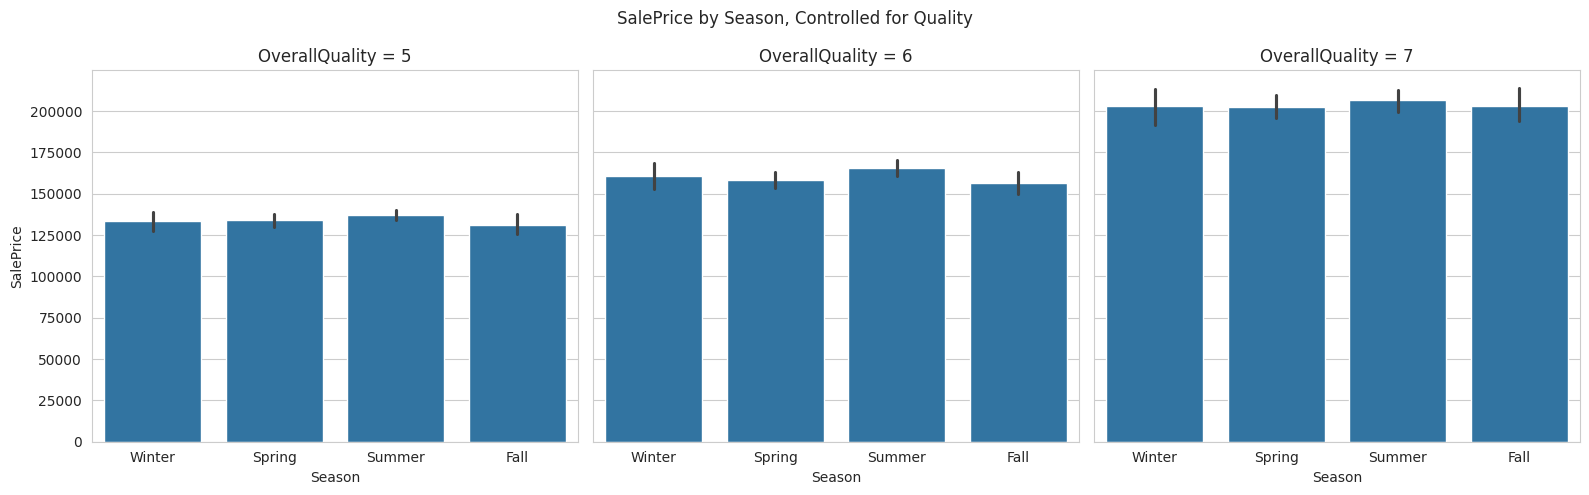

In [58]:
priced_train = X_train.copy()
priced_train['SalePrice'] = y_train

season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Fall', 10: 'Fall', 11: 'Fall'}
priced_train['Season'] = priced_train['MonthSold'].map(season_map)

print('Overall average price by season (NOT controlled for quality):')
print(priced_train.groupby('Season')['SalePrice'].agg(['mean', 'count']))

print('\nAverage price by season, controlled for OverallQuality (common quality levels 5, 6, 7):')
for q in [5, 6, 7]:
    sub = priced_train[priced_train['OverallQuality'] == q]
    print(f'\n--- OverallQuality = {q} ---')
    print(sub.groupby('Season')['SalePrice'].agg(['mean', 'count']))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for i, q in enumerate([5, 6, 7]):
    sub = priced_train[priced_train['OverallQuality'] == q]
    sns.barplot(data=sub, x='Season', y='SalePrice', order=['Winter', 'Spring', 'Summer', 'Fall'], ax=axes[i])
    axes[i].set_title(f'OverallQuality = {q}')
plt.suptitle('SalePrice by Season, Controlled for Quality')
plt.tight_layout()
plt.show()


**Result:** Without controlling for anything, prices look fairly flat by season. Once we control
for `OverallQuality` (comparing only houses of the same quality level: 5, 6, or 7), the seasonal
differences are small and inconsistent — for example, at Quality 6, Winter averages ~\$163,085
vs. Summer's ~\$166,241, a gap of under 2%, well within normal noise.

**Interpretation:** The common assumption that houses sell for less in winter doesn't hold up
once quality is held constant — the small raw differences seen earlier are driven by *which*
houses get listed each season, not a true seasonal discount. Winter isn't necessarily a bad time
to sell a house of comparable quality.


---
**End of EDA.**


## 5. Preprocessing

In [59]:
X_train

,RowID,ParcelID,BuildingClass,ZoningClass,LotFrontage,LotArea,StreetType,AlleyAccess,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BuildingType,HouseStyle,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,RoofStyle,RoofMaterial,ExteriorMaterial1,ExteriorMaterial2,MasonryVeneerType,MasonryVeneerArea,ExteriorQuality,ExteriorCondition,FoundationType,BasementQuality,BasementCondition,BasementExposure,BasementFinishType1,BasementFinishArea1,BasementFinishType2,BasementFinishArea2,BasementUnfinishedArea,TotalBasementArea,HeatingType,HeatingQuality,HasCentralAir,ElectricalSystem,FirstFloorArea,SecondFloorArea,LowQualityFinishedArea,AboveGroundLivingArea,BasementFullBaths,BasementHalfBaths,FullBaths,HalfBaths,Bedrooms,Kitchens,KitchenQuality,TotalRooms,Functionality,Fireplaces,FireplaceQuality,GarageType,GarageYearBuilt,GarageFinish,GarageCapacityCars,GarageArea,GarageQuality,GarageCondition,PavedDriveway,WoodDeckArea,OpenPorchArea,EnclosedPorchArea,ThreeSeasonPorchArea,ScreenPorchArea,PoolArea,PoolQuality,FenceQuality,MiscFeature,MiscValue,MonthSold,YearSold,SaleType,SaleCondition
149,150,535302080,20,RL,60.0,10950,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,7,1952,1952,Gable,CompShg,WdShing,Wd Shng,NaN,0.0,TA,TA,CBlock,TA,TA,No,BLQ,339.0,Unf,0.0,525.0,864.0,GasA,TA,Y,SBrkr,1064,0,0,1064,0.0,1.0,1,0,2,1,Fa,4,Typ,0,NaN,Detchd,1952.0,Unf,1.0,318.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
2074,2075,905376090,20,RL,NaN,17541,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Edwards,Norm,Norm,1Fam,1Story,5,7,1948,2005,Hip,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,Gd,CBlock,TA,Gd,Mn,BLQ,300.0,Unf,0.0,109.0,409.0,GasA,Ex,Y,SBrkr,1325,0,0,1325,0.0,0.0,2,0,3,1,Gd,6,Typ,1,TA,Detchd,1996.0,Unf,2.0,576.0,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,7,2007,WD,Normal
1467,1468,907285080,60,RL,70.0,8750,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,1994,1995,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,Gd,Gd,PConc,Gd,TA,No,GLQ,642.0,Unf,0.0,273.0,915.0,GasA,Ex,Y,SBrkr,933,975,0,1908,1.0,0.0,2,1,4,1,Gd,8,Typ,1,TA,Attchd,1994.0,Unf,2.0,493.0,TA,TA,Y,144,133,0,0,0,0,NaN,NaN,NaN,0,7,2008,WD,Normal
16,17,527225035,50,RL,152.0,12134,Pave,NaN,IR1,Bnk,AllPub,Inside,Mod,Gilbert,Norm,Norm,1Fam,1.5Fin,8,7,1988,2005,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,Gd,TA,Wood,Gd,TA,Av,GLQ,427.0,Unf,0.0,132.0,559.0,GasA,Gd,Y,SBrkr,1080,672,0,1752,0.0,0.0,2,0,4,1,TA,8,Typ,0,NaN,Basment,1988.0,RFn,2.0,492.0,TA,TA,Y,325,12,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
2782,2783,907201160,60,RL,50.0,8340,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,6,6,1977,1977,Gable,CompShg,HdBoard,Plywood,BrkFace,62.0,TA,TA,CBlock,Gd,TA,Av,GLQ,509.0,Unf,0.0,166.0,675.0,GasA,TA,Y,SBrkr,686,702,0,1388,0.0,0.0,1,1,3,1,TA,6,Typ,0,NaN,Attchd,1977.0,Unf,1.0,317.0,TA,TA,Y,406,36,0,0,0,0,NaN,NaN,NaN,0,12,2006,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1404,1405,905403060,50,RL,50.0,5190,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1.5Fin,7,5,1948,1950,Gable,CompShg,BrkFace,Plywood,NaN,0.0,TA,TA,CBlock,TA,TA,No,Unf,0.0,Unf,0.0,570.0,570.0,GasA,TA,Y,SBrkr,617,462,0,1079,0.0,0.0,1,0,2,1,TA,5,Typ,1,Gd,Attchd,1948.0,Unf,1.0,249.0,TA,TA,Y,135,0,0,0,0,0,NaN,NaN,NaN,0,1,2008,WD,Normal
2185,2186,908225240,20,RL,75.0,10215,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1Story,4,5,1954,1954,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,132.0,TA,TA,PConc,TA,TA,No,ALQ,492.0,Unf,0.0,372.0,864.0,GasA,Ex,Y,SBrkr,948,0,0,948,0.0,0.0,1,0,3,1,TA,5,Typ,0,NaN,Attchd,1954.0,Unf,1.0,248.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,2,2007,WD,Normal
2766,2767,906475200,20,RL,62.0,70761,Pave,NaN,IR1,Low,AllPub,Inside,Mod,ClearCr,Norm,Norm,1Fam,1Story,7,5,19

In [60]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [61]:

# Categorical features where missing means the feature does not exist
absence_ordinal = [
    'BasementQuality',
    'BasementCondition',
    'BasementExposure',
    'BasementFinishType1',
    'BasementFinishType2',
    'FireplaceQuality',
    'GarageFinish',
    'GarageQuality',
    'GarageCondition',
    'PoolQuality',
    'FenceQuality'
]

absence_nominal = [
    'AlleyAccess',
    'MasonryVeneerType',
    'GarageType',
    'MiscFeature'
]

# Numerical features where missing GENUINELY means the feature does not exist
# (verified against the related categorical column, e.g. missing BasementFinishArea1
# lines up 1:1 with BasementQuality being missing = "no basement"). Note that
# GarageCapacityCars/GarageArea are handled separately below (GarageMeasurementImputer)
# because one row has a garage that exists but is missing just these two measurements —
# zero-filling that row would incorrectly claim a 0-capacity/0-area garage.
zero_impute_features = [
    'MasonryVeneerArea',
    'BasementFinishArea1',
    'BasementFinishArea2',
    'BasementUnfinishedArea',
    'TotalBasementArea',
    'BasementFullBaths',
    'BasementHalfBaths',
]


In [62]:
# Calculate group median using X_train only
group_median = X_train.groupby(
    ['Neighborhood', 'LotConfig']
)['LotFrontage'].median()

# Fill X_train
train_groups = pd.MultiIndex.from_frame(
    X_train[['Neighborhood', 'LotConfig']]
)

X_train['LotFrontage'] = X_train['LotFrontage'].fillna(
    pd.Series(group_median.reindex(train_groups).values, index=X_train.index)
)

# Overall median from X_train
overall_median = X_train['LotFrontage'].median()

# Fill remaining missing values in X_train
X_train['LotFrontage'] = X_train['LotFrontage'].fillna(overall_median)


# Fill X_test using the same group medians from X_train
test_groups = pd.MultiIndex.from_frame(
    X_test[['Neighborhood', 'LotConfig']]
)

X_test['LotFrontage'] = X_test['LotFrontage'].fillna(
    pd.Series(group_median.reindex(test_groups).values, index=X_test.index)
)

# Fill unseen groups with X_train overall median
X_test['LotFrontage'] = X_test['LotFrontage'].fillna(overall_median)

print("Train missing LotFrontage:", X_train['LotFrontage'].isna().sum())
print("Test missing LotFrontage:", X_test['LotFrontage'].isna().sum())

Train missing LotFrontage: 0
Test missing LotFrontage: 0


In [63]:
X_train = X_train.dropna(subset=['ElectricalSystem'])
X_test = X_test.dropna(subset=['ElectricalSystem'])
y_train = y_train.loc[X_train.index]
y_test = y_test.loc[X_test.index]
print(X_train['ElectricalSystem'].isna().sum())
print(X_test['ElectricalSystem'].isna().sum())

0
0


### 5.1 Duplicate rows — explicit check & removal

We already checked `df.duplicated()` and `X_train.duplicated()` in EDA and found 0
duplicates. We repeat the check here, explicitly, on the **feature columns only**
(`X_train`, without `SalePrice`).

**Important: we deliberately do NOT include `SalePrice` in this check.** Two houses can
have identical features (same neighborhood, size, quality, year built, etc.) and still
legitimately sell for different prices — negotiation, timing, staging, and buyer-specific
factors all affect the final price independently of the recorded features. Treating
"same features, different price" as a duplicate to be removed would be wrong: it would
delete real, valid observations and bias the training data. A duplicate should only be
defined by the **feature** columns.

In [64]:
dup_features_train = X_train.duplicated().sum()
dup_features_test = X_test.duplicated().sum()
print(f"Duplicate feature-rows in X_train: {dup_features_train}")
print(f"Duplicate feature-rows in X_test:  {dup_features_test}")

if dup_features_train > 0:
    keep_idx = X_train.drop_duplicates().index
    dropped = len(X_train) - len(keep_idx)
    X_train = X_train.loc[keep_idx]
    y_train = y_train.loc[keep_idx]
    print(f"Dropped {dropped} duplicate feature-row(s) from training data.")
else:
    print("No duplicate feature-rows found — nothing to drop.")


Duplicate feature-rows in X_train: 0
Duplicate feature-rows in X_test:  0
No duplicate feature-rows found — nothing to drop.


### 5.1 (cont.) Outliers — kept, not removed

EDA (section 2.5) flagged a couple of houses with unusually large `AboveGroundLivingArea`
relative to their `SalePrice`. **We do not remove any rows for this.** House prices are
naturally highly variable — a large house can genuinely sell cheaply (distressed sale,
location, condition, market timing) without that being a data-entry error. Removing such
points would mean throwing away real market behavior the model should learn to handle, not
"noise." The `RobustScaler` used in the numeric pipeline (section 6.2) and the `log1p`
transform on the skewed numeric features already reduce the influence of extreme values on
the model without deleting any observations.

### 5.1 (cont.) Class imbalance — is it relevant here?

**Short answer: no, not in the classification sense, and it doesn't apply to this problem.**

"Class imbalance" is a concept specific to **classification** tasks, where some target
*classes* are much rarer than others (e.g. 95% negative / 5% positive) and a naive model
can get high accuracy by ignoring the rare class. Here the target, `SalePrice`, is a
**continuous numeric variable** — this is a **regression** problem, so there are no classes
to be imbalanced in the first place.

That said, the *spirit* of the concern — "is the target distribution lopsided enough to bias
preprocessing/modeling decisions toward one region of values?" — does have a regression
analogue, and it was addressed:

- `SalePrice` is **right-skewed** (skew ≈ 1.7): most houses cluster in a common price range
  with a long tail of expensive homes. We handle this with the **log1p transform** on the
  target (section 5.3 below), which makes the distribution far more symmetric.
- When splitting the data (train/val/test), we used **`stratify=price_bins`** — 5 price
  quintile bins — specifically so cheap, mid-range, and expensive houses are represented in
  the same *proportions* across all three sets.

So: classic "class imbalance" techniques (SMOTE, class weighting, resampling by class) are
**not applicable** here; the equivalent issue (a skewed target distribution) was handled
with a log transform + stratified splitting instead.

### 5.2 Train / Validation split

So far we only have a training set and a held-out test set (80/20, from section 1.3).
For model selection and hyperparameter tuning we also need a **validation set** that is
separate from the final test set. We split the (outlier-cleaned) training data again,
80/20, using the same price-quintile stratification trick as before so that cheap,
mid-range and expensive houses are represented proportionally in both pieces.

Final split: **64% train / 16% validation / 20% test** (of the original dataset).

In [65]:
price_bins_train = pd.qcut(y_train, q=5, labels=False, duplicates='drop')

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=price_bins_train
)

print(f"Training set:   {X_train.shape[0]} rows ({X_train.shape[0] / df.shape[0]:.0%})")
print(f"Validation set: {X_val.shape[0]} rows ({X_val.shape[0] / df.shape[0]:.0%})")
print(f"Test set:       {X_test.shape[0]} rows ({X_test.shape[0] / df.shape[0]:.0%})")

Training set:   1875 rows (64%)
Validation set: 469 rows (16%)
Test set:       585 rows (20%)


### 5.3 Log-transform the target (`SalePrice`)

We saw in section 2.2 that `SalePrice` is right-skewed (skew ≈ 1.7). Linear models assume
roughly normal, homoscedastic errors, so we model **`log(1 + SalePrice)`** instead of the
raw price. `np.log1p` is used instead of `np.log` purely as a safe habit (it behaves for
zero values too, although `SalePrice` is never zero here). Predictions are converted back
with `np.expm1` whenever we need to report errors in dollars.

We fit the transform's *inverse* only, so there is nothing to "leak" here — `log1p` is a
fixed, parameter-free function, not something estimated from the training data.

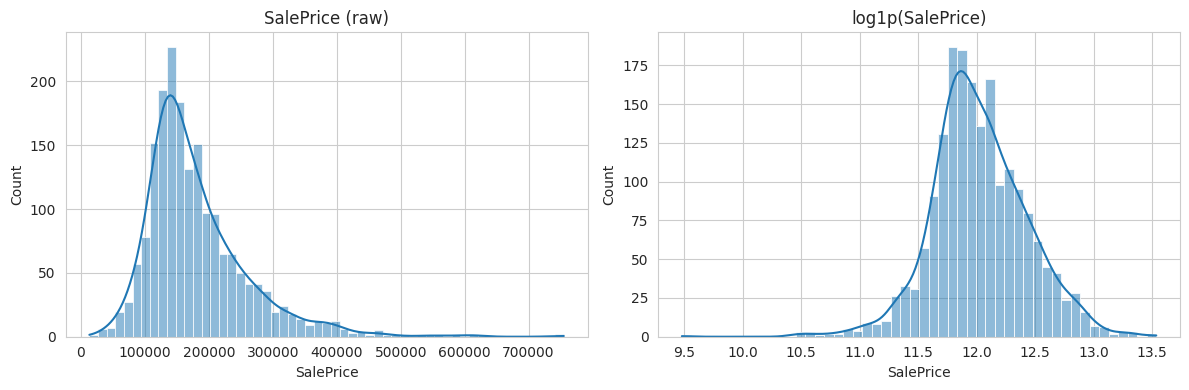

Skewness before: 1.81
Skewness after:  -0.04


In [66]:
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, kde=True, ax=axes[0]).set_title('SalePrice (raw)')
sns.histplot(y_train_log, kde=True, ax=axes[1]).set_title('log1p(SalePrice)')
plt.tight_layout()
plt.show()

print(f"Skewness before: {y_train.skew():.2f}")
print(f"Skewness after:  {y_train_log.skew():.2f}")

### 5.4 Re-checking skewed numerical features (on the final training set)

Section 5 above already computed `highly_skewed_features` once, but that was **before**
we removed outliers and carved out the validation set. We recompute it here on the final
`X_train` so the list used inside the pipeline reflects the data the pipeline will actually
be fit on (still training-data-only, so no leakage). Any numerical feature with
`|skew| > 1` will get a `log1p` transform inside the numeric pipeline, right before scaling.

In [67]:
skewed_series = X_train[numerical_features].skew().sort_values(ascending=False)
highly_skewed_features = skewed_series[skewed_series.abs() > 1].index.tolist()

print(f"{len(highly_skewed_features)} highly skewed numerical features (|skew| > 1):")
skewed_series[skewed_series.abs() > 1]

16 highly skewed numerical features (|skew| > 1):


,0
MiscValue,26.846240
PoolArea,17.288801
LotArea,13.182250
ThreeSeasonPorchArea,11.032819
LowQualityFinishedArea,10.475837
EnclosedPorchArea,4.262574
Kitchens,4.233940
BasementFinishArea2,4.085960
BasementHalfBaths,4.069216
ScreenPorchArea,3.877945


### 5.5 Missing-value strategy — summary

Before finalizing the rules below, each numerical "no-feature" column was checked against
its related categorical column (e.g. `GarageArea` vs `GarageType`) to confirm that a
missing value really does mean "feature doesn't exist" and not "feature exists but this
one measurement wasn't recorded." One exception was found and handled separately (see the
`Garage Cars`/`Garage Area` row below).

| Situation | Example columns | Strategy |
|---|---|---|
| `LotFrontage`: genuinely missing measurement | `LotFrontage` | Imputed with the **median frontage of the same Neighborhood + LotConfig group** (falling back to the overall training median for unseen combinations) — a more informed guess than a single global number. |
| `GarageYearBuilt`: missing because the house has no garage | `GarageYearBuilt` | Filled with the house's own `YearBuilt` (a garage-less house is treated as if a "garage" existed since the house was built, i.e. age 0 relative to the house) instead of `0`, which would create a nonsensical 1,900-year gap that would badly distort a linear model. |
| `GarageCapacityCars` / `GarageArea`: **one row has a real garage (`GarageType='Detchd'`) but a missing car-capacity/area measurement** | `GarageCapacityCars`, `GarageArea` | **Not** filled with 0 (that would wrongly claim the existing garage has 0 capacity/area). Filled with the **median capacity/area of other houses with the same `GarageType`** — a value consistent with "a garage exists," unlike 0. |
| Numerical "no feature" columns (verified: missing ⟺ feature absent) | `MasonryVeneerArea`, `BasementFinishArea1/2`, `BasementUnfinishedArea`, `TotalBasementArea`, `BasementFullBaths`, `BasementHalfBaths` | Filled with **0** — missing here means the feature doesn't exist (no basement/veneer), so an area/count of 0 is the semantically correct value, not an estimate. |
| Any other numerical column | e.g. rare data-entry gaps | **Median** imputation (robust to the outliers/skew we found in EDA) as a generic safety net. |
| Ordinal "no feature" columns | `BasementQual`, `GarageQual`, `FireplaceQu`, `PoolQC`, `FenceQual`, ... | Filled with the constant `'None'`, then ordinal-encoded with `'None'` ranked **below** `'Po'` (worst quality on record) — no basement/garage/pool/fence is treated as lower than a poor one. |
| Ordinary ordinal columns | `KitchenQual`, `ExterQual`, `Functional`, `Utilities`, ... | **Most-frequent** imputation (rare gaps only). |
| Nominal "no feature" columns | `AlleyAccess`, `MasonryVeneerType`, `GarageType`, `MiscFeature` | Filled with the constant `'None'` (a real category for some of these already, e.g. `MasVnrType`), then one-hot encoded. |
| Ordinary nominal columns | `Electrical`, `Neighborhood`, ... | **Most-frequent** imputation (rare gaps only, e.g. a single missing `Electrical` value). |

All of the imputation choices above are implemented **inside the pipelines below**, so
they are fit only on training folds and applied — never re-fit — to validation/test data.

## 6. Pipelines & ColumnTransformer

We now build the three required preprocessing pipelines and combine them with a
`ColumnTransformer`. Because the numerical and ordinal/nominal "no-feature" columns need
different imputation logic than the "normally missing" columns, each of the three main
pipelines is internally split into a couple of column groups that share the same
imputation/encoding logic — but conceptually there are still exactly three pipelines:
**numerical**, **nominal categorical**, and **ordinal categorical**.

In [68]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin

### 6.1 Custom helper transformers

Three small custom pieces are needed that plain sklearn transformers can't express on
their own — all applied to the whole `DataFrame`, **before** the `ColumnTransformer`
splits the data into column groups, because each needs to look at more than one column
at once (an area/count column plus the related category column). All three apply fixed
rules learned only from training-data statistics (medians by group), so there is no
leakage risk even though they technically sit outside the `ColumnTransformer`.

1. **`GarageYearImputer`** — fills missing `GarageYearBuilt` (= no garage) with the
   house's own `YearBuilt`, instead of an arbitrary constant like `0` which would create
   a huge, meaningless gap.
2. **`GarageMeasurementImputer`** — fills missing `GarageCapacityCars` / `GarageArea`,
   but distinguishes two genuinely different situations rather than treating every
   missing value the same way: (a) **no garage at all** (`GarageType` is null) → `0` is
   correct; (b) **one row** where a garage genuinely exists (`GarageType` is not null)
   but the measurement itself wasn't recorded → filling with `0` would incorrectly claim
   a 0-capacity/0-area garage, so this row is filled with the **median capacity/area of
   other training houses with the same `GarageType`** instead.
3. **`SelectiveLogTransformer`** — applies `log1p` only to the numerical columns flagged
   as highly skewed, leaving the rest of the numeric block untouched, then hands off to
   the scaler.

In [69]:
class GarageYearImputer(BaseEstimator, TransformerMixin):
    """Fill missing GarageYearBuilt (= no garage) with the house's own YearBuilt,
    instead of an arbitrary constant like 0 which would create a huge, meaningless gap."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        mask = X['GarageYearBuilt'].isna()
        X.loc[mask, 'GarageYearBuilt'] = X.loc[mask, 'YearBuilt']
        return X


class GarageMeasurementImputer(BaseEstimator, TransformerMixin):
    """Fill missing GarageCapacityCars / GarageArea, distinguishing TWO different
    situations rather than treating every missing value the same way:

    1. No garage at all (GarageType is null) -> 0 is the semantically correct value
       (there is genuinely no capacity/area to report).
    2. A garage genuinely EXISTS (GarageType is not null) but this one measurement wasn't
       recorded -> filling with 0 would incorrectly claim a 0-capacity/0-area garage.
       Instead we use the median capacity/area of other training houses with the same
       GarageType (falling back to the overall training median for an unseen type).

    Medians are learned from training data only (via fit), then applied - never re-fit -
    to validation/test data."""
    def fit(self, X, y=None):
        has_garage = X['GarageType'].notna()
        self.medians_by_type_ = (
            X.loc[has_garage]
             .groupby('GarageType')[['GarageCapacityCars', 'GarageArea']]
             .median()
        )
        self.overall_medians_ = X.loc[has_garage, ['GarageCapacityCars', 'GarageArea']].median()
        return self

    def transform(self, X):
        X = X.copy()
        no_garage = X['GarageType'].isna()
        has_garage = ~no_garage

        # Case 1: genuinely no garage -> 0
        X.loc[no_garage, 'GarageCapacityCars'] = X.loc[no_garage, 'GarageCapacityCars'].fillna(0)
        X.loc[no_garage, 'GarageArea'] = X.loc[no_garage, 'GarageArea'].fillna(0)

        # Case 2: garage exists but measurement missing -> median for that GarageType
        needs_fill = has_garage & (X['GarageCapacityCars'].isna() | X['GarageArea'].isna())
        for idx in X.index[needs_fill]:
            gtype = X.loc[idx, 'GarageType']
            fill_vals = self.medians_by_type_.loc[gtype] if gtype in self.medians_by_type_.index else self.overall_medians_
            if pd.isna(X.loc[idx, 'GarageCapacityCars']):
                X.loc[idx, 'GarageCapacityCars'] = fill_vals['GarageCapacityCars']
            if pd.isna(X.loc[idx, 'GarageArea']):
                X.loc[idx, 'GarageArea'] = fill_vals['GarageArea']
        return X


def _zero_fill_absence_features(X, cols=tuple(zero_impute_features)):
    """Fill numerical 'feature does not exist' columns with 0 (see missing-value table)."""
    X = X.copy()
    for c in cols:
        if c in X.columns:
            X[c] = X[c].fillna(0)
    return X


class SelectiveLogTransformer(BaseEstimator, TransformerMixin):
    """Apply log1p only to the columns (by position) flagged as highly skewed."""
    def __init__(self, col_idx):
        self.col_idx = col_idx

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        if len(self.col_idx) > 0:
            X[:, self.col_idx] = np.log1p(np.clip(X[:, self.col_idx], a_min=0, a_max=None))
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)
# Position of each skewed feature within `numerical_features`, so SelectiveLogTransformer
# knows which columns of the (already imputed) numeric array to transform.
skewed_idx = [numerical_features.index(c) for c in highly_skewed_features]


### 6.2 Pipeline 1 — Numerical features

Steps: **domain-aware zero-fill → median imputation (safety net) → selective log1p for
skewed features → scaling**.

**Why `RobustScaler` and not `StandardScaler`?** EDA (sections 2.5 and 2.5) found real
outliers in features like `LotArea`, `AboveGroundLivingArea`, and `LotFrontage`.
`StandardScaler` uses the mean and standard deviation, both of which are themselves
pulled around by outliers — a handful of huge lots would compress every "normal" house
into a tiny range near zero. `RobustScaler` centers on the **median** and scales by the
**IQR**, so it is far less sensitive to the extreme values we already identified,
while still putting every numeric feature on a comparable scale for linear models.

In [70]:
numeric_pipeline = Pipeline([
    ('zero_fill', FunctionTransformer(
        _zero_fill_absence_features,
        feature_names_out='one-to-one'
    )),

    ('impute_median', SimpleImputer(strategy='median')),

    ('log_transform', SelectiveLogTransformer(skewed_idx)),

    ('scale', RobustScaler()),
])

### 6.3 Pipeline 2 — Ordinal categorical features

Split into two column groups that need different imputation, but both end in an
`OrdinalEncoder` with an **explicit, meaning-preserving category order** (never the
alphabetical default):

- **"No feature" columns** (basement/garage/fireplace/pool/fence quality & related):
  missing values are filled with the constant `'None'`, and `'None'` is ranked as the
  **lowest** category (below `'Po'`/Poor) for every quality-style column.
- **Ordinary ordinal columns** (`KitchenQual`, `ExterQual`, `Functional`, `Utilities`, ...):
  missing values (rare) get most-frequent imputation, and the category order follows the
  meaning in `data_description.txt` (e.g. `Po < Fa < TA < Gd < Ex`).

In [71]:
ordinal_normal_cols = [
    'LotShape', 'LandSlope', 'ExteriorQuality', 'ExteriorCondition',
    'HeatingQuality', 'KitchenQuality', 'Functionality', 'PavedDriveway', 'Utilities'
]

ordinal_absence_cols = [
    'BasementQuality', 'BasementCondition', 'BasementExposure', 'BasementFinishType1',
    'BasementFinishType2', 'FireplaceQuality', 'GarageFinish', 'GarageQuality',
    'GarageCondition', 'PoolQuality', 'FenceQuality'
]

assert set(ordinal_normal_cols) | set(ordinal_absence_cols) == set(ordinal_features)

# Explicit worst -> best ordering per column (order of this list must match ordinal_normal_cols)
_quality_scale = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ordinal_normal_categories = [
    ['IR3', 'IR2', 'IR1', 'Reg'] if c == 'LotShape' else
    ['Sev', 'Mod', 'Gtl'] if c == 'LandSlope' else
    ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'] if c == 'Functionality' else
    ['N', 'P', 'Y'] if c == 'PavedDriveway' else
    ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'] if c == 'Utilities' else
    _quality_scale
    for c in ordinal_normal_cols
]

# 'None' (no basement/garage/pool/fence/fireplace) is always the worst possible rank
absence_orders = {
    'BasementQuality':     ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BasementCondition':   ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BasementExposure':    ['None', 'No', 'Mn', 'Av', 'Gd'],
    'BasementFinishType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BasementFinishType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'FireplaceQuality':    ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageFinish':        ['None', 'Unf', 'RFn', 'Fin'],
    'GarageQuality':       ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageCondition':     ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'PoolQuality':         ['None', 'Fa', 'TA', 'Gd', 'Ex'],
    'FenceQuality':        ['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],
}
ordinal_absence_categories = [absence_orders[c] for c in ordinal_absence_cols]

ordinal_normal_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(categories=ordinal_normal_categories,
                               handle_unknown='use_encoded_value', unknown_value=-1)),
])

ordinal_absence_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='None')),
    ('encode', OrdinalEncoder(categories=ordinal_absence_categories,
                               handle_unknown='use_encoded_value', unknown_value=-1)),
])

ordinal_normal_pipeline

Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')),
                ('encode',
                 OrdinalEncoder(categories=[['IR3', 'IR2', 'IR1', 'Reg'],
                                            ['Sev', 'Mod', 'Gtl'],
                                            ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
                                            ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
                                            ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
                                            ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
                                            ['Sal', 'Sev', 'Maj2', 'Maj1',
                                             'Mod', 'Min2', 'Min1', 'Typ'],
                                            ['N', 'P', 'Y'],
                                            ['ELO', 'NoSeWa', 'NoSewr',
                                             'AllPub']],
                                handle_unknown='use_encoded_value',
                                unknown_value=-1))])

### 6.4 Pipeline 3 — Nominal categorical features

Same idea as the ordinal split, but ending in **One-Hot Encoding** instead (nominal
categories have no natural order, so ordinal ranks would invent a false one):

- **"No feature" columns** (`AlleyAccess`, `MasonryVeneerType`, `GarageType`,
  `MiscFeature`): missing → constant `'None'`.
- **Ordinary nominal columns** (`Neighborhood`, `SaleType`, `Electrical`, ...): missing
  (rare) → most-frequent imputation.

Both use `OneHotEncoder(handle_unknown='ignore')` so that a category seen only in
validation/test (never in training) doesn't crash the pipeline — it's simply encoded as
all-zeros for that feature.

In [72]:
nominal_absence_cols = ['AlleyAccess', 'MasonryVeneerType', 'GarageType', 'MiscFeature']
nominal_normal_cols = [c for c in nominal_features if c not in nominal_absence_cols]

assert set(nominal_normal_cols) | set(nominal_absence_cols) == set(nominal_features)

nominal_normal_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

nominal_absence_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

nominal_normal_pipeline

Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')),
                ('onehot',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

### 6.5 Combining everything with `ColumnTransformer`

The `ColumnTransformer` below routes each column to the correct pipeline and
concatenates the outputs into a single feature matrix. `remainder='drop'` makes sure
`RowID`/`ParcelID` (identifiers, not predictive features) are excluded automatically.

In [73]:
preprocessor = ColumnTransformer(transformers=[
    ('num',         numeric_pipeline,           numerical_features),
    ('ord_normal',  ordinal_normal_pipeline,     ordinal_normal_cols),
    ('ord_absence', ordinal_absence_pipeline,    ordinal_absence_cols),
    ('nom_normal',  nominal_normal_pipeline,     nominal_normal_cols),
    ('nom_absence', nominal_absence_pipeline,    nominal_absence_cols),
], remainder='drop')

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('zero_fill',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function _zero_fill_absence_features at 0x7ba82991a480>)),
                                                 ('impute_median',
                                                  SimpleImputer(strategy='median')),
                                                 ('log_transform',
                                                  SelectiveLogTransformer(col_idx=[32,
                                                                                   31,
                                                                                   1,
                                                                                   29,
                                                                                   13,
                                                                                   28,
                                                                                   20,
                                                                                   8,
                                                                                   16,
                                                                                   30,
                                                                                   27,
                                                                                   6,
                                                                                   26,
                                                                                   11,
                                                                                   14,
                                                                                   7])),
                                                 ('scale', RobustScaler(...
                                  'ExteriorMaterial1', 'ExteriorMaterial2',
                                  'FoundationType', 'HeatingType',
                                  'HasCentralAir', 'ElectricalSystem',
                                  'SaleType', 'SaleCondition']),
                                ('nom_absence',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(fill_value='None',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['AlleyAccess', 'MasonryVeneerType',
                                  'GarageType', 'MiscFeature'])])

In [74]:
X_train = GarageYearImputer().fit_transform(X_train)
X_val = GarageYearImputer().transform(X_val)
X_test = GarageYearImputer().transform(X_test)

garage_measure_imputer = GarageMeasurementImputer().fit(X_train)
X_train = garage_measure_imputer.transform(X_train)
X_val = garage_measure_imputer.transform(X_val)
X_test = garage_measure_imputer.transform(X_test)

print("Remaining missing GarageCapacityCars:", X_train['GarageCapacityCars'].isna().sum(),
      X_val['GarageCapacityCars'].isna().sum(), X_test['GarageCapacityCars'].isna().sum())
print("Remaining missing GarageArea:        ", X_train['GarageArea'].isna().sum(),
      X_val['GarageArea'].isna().sum(), X_test['GarageArea'].isna().sum())


Remaining missing GarageCapacityCars: 0 0 0
Remaining missing GarageArea:         0 0 0


In [75]:
# Apply preprocessing
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

# Check shapes
print("X_train:", X_train_processed.shape)
print("X_val:", X_val_processed.shape)
print("X_test:", X_test_processed.shape)

X_train: (1875, 241)
X_val: (469, 241)
X_test: (585, 241)


In [76]:

# Get the new feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrames
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_processed = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

In [77]:
X_train_processed

,num__LotFrontage,num__LotArea,num__OverallQuality,num__OverallCondition,num__YearBuilt,num__YearRemodeled,num__MasonryVeneerArea,num__BasementFinishArea1,num__BasementFinishArea2,num__BasementUnfinishedArea,num__TotalBasementArea,num__FirstFloorArea,num__SecondFloorArea,num__LowQualityFinishedArea,num__AboveGroundLivingArea,num__BasementFullBaths,num__BasementHalfBaths,num__FullBaths,num__HalfBaths,num__Bedrooms,num__Kitchens,num__TotalRooms,num__Fireplaces,num__GarageYearBuilt,num__GarageCapacityCars,num__GarageArea,num__WoodDeckArea,num__OpenPorchArea,num__EnclosedPorchArea,num__ThreeSeasonPorchArea,num__ScreenPorchArea,num__PoolArea,num__MiscValue,num__MonthSold,num__YearSold,ord_normal__LotShape,ord_normal__LandSlope,ord_normal__ExteriorQuality,ord_normal__ExteriorCondition,ord_normal__HeatingQuality,ord_normal__KitchenQuality,ord_normal__Functionality,ord_normal__PavedDriveway,ord_normal__Utilities,ord_absence__BasementQuality,ord_absence__BasementCondition,ord_absence__BasementExposure,ord_absence__BasementFinishType1,ord_absence__BasementFinishType2,ord_absence__FireplaceQuality,ord_absence__GarageFinish,ord_absence__GarageQuality,ord_absence__GarageCondition,ord_absence__PoolQuality,ord_absence__FenceQuality,nom_normal__BuildingClass_20,nom_normal__BuildingClass_30,nom_normal__BuildingClass_40,nom_normal__BuildingClass_45,nom_normal__BuildingClass_50,nom_normal__BuildingClass_60,nom_normal__BuildingClass_70,nom_normal__BuildingClass_75,nom_normal__BuildingClass_80,nom_normal__BuildingClass_85,nom_normal__BuildingClass_90,nom_normal__BuildingClass_120,nom_normal__BuildingClass_160,nom_normal__BuildingClass_180,nom_normal__BuildingClass_190,nom_normal__ZoningClass_A (agr),nom_normal__ZoningClass_C (all),nom_normal__ZoningClass_FV,nom_normal__ZoningClass_I (all),nom_normal__ZoningClass_RH,nom_normal__ZoningClass_RL,nom_normal__ZoningClass_RM,nom_normal__StreetType_Grvl,nom_normal__StreetType_Pave,nom_normal__LandContour_Bnk,nom_normal__LandContour_HLS,nom_normal__LandContour_Low,nom_normal__LandContour_Lvl,nom_normal__LotConfig_Corner,nom_normal__LotConfig_CulDSac,nom_normal__LotConfig_FR2,nom_normal__LotConfig_FR3,nom_normal__LotConfig_Inside,nom_normal__Neighborhood_Blmngtn,nom_normal__Neighborhood_Blueste,nom_normal__Neighborhood_BrDale,nom_normal__Neighborhood_BrkSide,nom_normal__Neighborhood_ClearCr,nom_normal__Neighborhood_CollgCr,nom_normal__Neighborhood_Crawfor,nom_normal__Neighborhood_Edwards,nom_normal__Neighborhood_Gilbert,nom_normal__Neighborhood_Greens,nom_normal__Neighborhood_IDOTRR,nom_normal__Neighborhood_Landmrk,nom_normal__Neighborhood_MeadowV,nom_normal__Neighborhood_Mitchel,nom_normal__Neighborhood_NAmes,nom_normal__Neighborhood_NPkVill,nom_normal__Neighborhood_NWAmes,nom_normal__Neighborhood_NoRidge,nom_normal__Neighborhood_NridgHt,nom_normal__Neighborhood_OldTown,nom_normal__Neighborhood_SWISU,nom_normal__Neighborhood_Sawyer,nom_normal__Neighborhood_SawyerW,nom_normal__Neighborhood_Somerst,nom_normal__Neighborhood_StoneBr,nom_normal__Neighborhood_Timber,nom_normal__Neighborhood_Veenker,nom_normal__Condition1_Artery,nom_normal__Condition1_Feedr,nom_normal__Condition1_Norm,nom_normal__Condition1_PosA,nom_normal__Condition1_PosN,nom_normal__Condition1_RRAe,nom_normal__Condition1_RRAn,nom_normal__Condition1_RRNe,nom_normal__Condition1_RRNn,nom_normal__Condition2_Artery,nom_normal__Condition2_Feedr,nom_normal__Condition2_Norm,nom_normal__Condition2_PosA,nom_normal__Condition2_PosN,nom_normal__Condition2_RRAe,nom_normal__Condition2_RRAn,nom_normal__Condition2_RRNn,nom_normal__BuildingType_1Fam,nom_normal__BuildingType_2fmCon,nom_normal__BuildingType_Duplex,nom_normal__BuildingType_Twnhs,nom_normal__BuildingType_TwnhsE,nom_normal__HouseStyle_1.5Fin,nom_normal__HouseStyle_1.5Unf,nom_normal__HouseStyle_1Story,nom_normal__HouseStyle_2.5Fin,nom_normal__HouseStyle_2.5Unf,nom_normal__HouseStyle_2Story,nom_normal__HouseStyle_SFoyer,nom_normal__HouseStyle_SLvl,nom_normal__RoofStyle_Flat,nom_normal__RoofStyle_Gable

## 7. Feature Selection

After encoding we have **~230+ columns** (one-hot encoding alone turns `Neighborhood`,
`ExteriorMaterial1/2`, etc. into dozens of columns). Since this is a **preprocessing**
deliverable — not tied to one specific downstream model — the selection method should be
**model-agnostic**: it should work reasonably well no matter which regressor (linear, tree,
SVR, ...) ends up being used later, rather than being tuned around one algorithm's
particular biases.

**Method chosen: a two-step, model-agnostic filter, directly motivated by findings already
made during EDA:**

**Step 1 — Variance Threshold** (remove near-constant columns). After one-hot encoding, a
rare category (e.g. a `RoofMaterial` type present in only 2-3 houses) produces a column
that is almost all zeros. Such columns carry almost no information and mostly add noise/
overfitting risk for every model type. We drop numeric/encoded columns with variance below
a small threshold.

**Step 2 — Correlation-based redundancy removal** (numeric features only). EDA (section
2.6 / correlation heatmap) already found specific highly-correlated pairs —
`GarageCapacityCars` vs `GarageArea`, and `TotalBasementArea` vs `FirstFloorArea` — that
carry overlapping information. When two numeric features are correlated above a threshold
(here `|r| > 0.85`), we keep only the one **more correlated with the (log) target** and
drop the other, since keeping both adds redundant dimensions without adding predictive
information, and redundant/collinear inputs are especially harmful for linear or
distance-based models (SVR, Ridge, etc.) even though they matter less for tree-based
models — so removing them is a safe, general default.

**Why not an embedded/model-specific method (e.g. `SelectFromModel` with `Lasso`)?** That
would tune the feature set to whichever model happens to sit inside the selector, biasing
selection toward, say, a linear model's preferences, even if the final model used later is
a tree-based one. A pure **filter** approach (variance + correlation) makes no assumption
about which model will consume the features afterward — appropriate for a preprocessing
pipeline meant to be reusable across models.

**Why not `SelectKBest`/mutual information as the primary method?** Those look at each
feature independently and would happily keep both features of a highly correlated pair
(each may correlate well with the target individually) — they don't address the
redundancy problem EDA specifically flagged. The correlation-based step here directly
targets that.

**Why not a wrapper method (`RFE`)?** Accurate, but requires repeatedly retraining a model
across ~230 features — expensive, and (again) tied to whichever model is chosen for the
wrapper, defeating the "model-agnostic" goal of this step.

In [78]:
from sklearn.feature_selection import VarianceThreshold

# Step 1: drop near-constant columns (variance below a small threshold)
var_thresh = VarianceThreshold(threshold=0.01)
var_thresh.fit(X_train_processed)

low_variance_cols = X_train_processed.columns[~var_thresh.get_support()]
print(f"Columns dropped for near-zero variance: {len(low_variance_cols)}")
print(list(low_variance_cols)[:15], '...' if len(low_variance_cols) > 15 else '')

X_train_var = X_train_processed.loc[:, var_thresh.get_support()]
X_val_var = X_val_processed.loc[:, var_thresh.get_support()]
X_test_var = X_test_processed.loc[:, var_thresh.get_support()]

print(f"\nColumns remaining after variance filter: {X_train_var.shape[1]}")


Columns dropped for near-zero variance: 72
['num__Kitchens', 'ord_normal__Utilities', 'nom_normal__BuildingClass_40', 'nom_normal__BuildingClass_45', 'nom_normal__BuildingClass_75', 'nom_normal__BuildingClass_180', 'nom_normal__ZoningClass_A (agr)', 'nom_normal__ZoningClass_I (all)', 'nom_normal__StreetType_Grvl', 'nom_normal__StreetType_Pave', 'nom_normal__LotConfig_FR3', 'nom_normal__Neighborhood_Blueste', 'nom_normal__Neighborhood_BrDale', 'nom_normal__Neighborhood_Greens', 'nom_normal__Neighborhood_Landmrk'] ...

Columns remaining after variance filter: 169


In [79]:
# Step 2: correlation-based redundancy removal among the (still scaled) numeric columns
numeric_processed_cols = [c for c in X_train_var.columns if c.startswith('num__')]

corr_matrix = X_train_var[numeric_processed_cols].corr().abs()
target_corr = X_train_var[numeric_processed_cols].corrwith(y_train_log).abs()

to_drop = set()
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        c1, c2 = cols[i], cols[j]
        if c1 in to_drop or c2 in to_drop:
            continue
        if corr_matrix.loc[c1, c2] > 0.85:
            # keep whichever is more correlated with the (log) target, drop the other
            drop_col = c1 if target_corr[c1] < target_corr[c2] else c2
            to_drop.add(drop_col)
            print(f"{c1} <-> {c2}: r={corr_matrix.loc[c1, c2]:.2f} -> dropping {drop_col}")

X_train_selected = X_train_var.drop(columns=list(to_drop))
X_val_selected = X_val_var.drop(columns=list(to_drop))
X_test_selected = X_test_var.drop(columns=list(to_drop))

print(f"\nColumns dropped for redundancy: {len(to_drop)}")
print(f"Final feature count: {X_train_selected.shape[1]} (started at {X_train_processed.shape[1]})")


num__YearBuilt <-> num__GarageYearBuilt: r=0.86 -> dropping num__GarageYearBuilt
num__GarageCapacityCars <-> num__GarageArea: r=0.90 -> dropping num__GarageArea

Columns dropped for redundancy: 2
Final feature count: 167 (started at 241)


**Result:** the variance filter removes rare/near-constant one-hot columns, and the
correlation filter resolves the specific redundant pairs flagged in EDA (e.g.
`GarageCapacityCars` vs `GarageArea`) by keeping only the feature more predictive of
`SalePrice`. `X_train_selected` / `X_val_selected` / `X_test_selected` are the final
preprocessed, feature-selected matrices — fitted only on training data and applied
(never re-fit) to validation/test, so there is no leakage.

**Note for a future modeling pipeline:** for full leak-safety inside cross-validation, both
steps above should be wrapped as sklearn-compatible transformers (`VarianceThreshold` is
already one; the correlation step would need a small custom `TransformerMixin`) and
inserted into the `Pipeline` right after the `ColumnTransformer` — the same principle used
for the imputers in section 6.1 — so that if this pipeline is later combined with a model,
everything is refit per training fold automatically.

## 8. From "Academic Preprocessing" to a Realistic Prediction Input

**An honest observation about the pipeline above:** all 78 raw columns (35 numerical + 20
ordinal + 24 nominal) feed into the `ColumnTransformer`, and the feature-selection step
(section 7) only trims the *encoded* columns after the fact (removing near-constant or
redundant ones). That is methodologically correct for a preprocessing exercise, but it
quietly assumes something unrealistic: **that whoever wants a prediction can supply values
for all 78 raw fields** — including things like `BasementFinishType2`, `Functionality`, or
`RoofMaterial`, which are **assessor-recorded** attributes (this dataset comes from Ames
City's official property assessment records), not things an average home seller
spontaneously knows off the top of their head.

This is a real gap worth calling out explicitly, not glossing over:

- **Not "unrealistic" in the sense of being wrong data** — the dataset itself is a
  legitimate, high-quality record of real sales. The 78-feature pipeline above is fully
  correct and appropriate **as an assessor-facing model**: a county appraiser or a real
  estate professional filling out a formal valuation *does* have (or can look up) every
  one of these fields, because that's literally their job.
- **It becomes unrealistic only for one specific use case**: a simple "estimate my house's
  value" tool aimed at an ordinary homeowner who does not have an inspection report in
  hand.

So there are, in effect, **two different legitimate products** hiding inside one dataset,
and the right feature set depends on which one you're building:

| | Full pipeline (sections 1-8) | Reduced, user-facing pipeline (this section) |
|---|---|---|
| **Audience** | Appraiser / analyst / internal pricing model | A homeowner typing values into a form |
| **Inputs available** | All 78 assessor-recorded fields | Only what a typical seller knows without an inspection |
| **Accuracy** | Higher (more information) | Somewhat lower, but usable in practice |
| **When to use** | Batch valuation, research, internal tooling | Public-facing "estimate my home's value" tool |

Neither one is "the correct" pipeline in isolation — **they answer different questions**.
Below we build the second one, reusing the same imputation/encoding/scaling logic already
established, but restricted to inputs a real user could plausibly type in.

### 8.1 Classifying every feature: can a typical seller self-report it?

Going through all 78 raw features and asking, honestly, "would a homeowner filling out an
online form know this without hiring an inspector or pulling official records?":

**✅ Realistic for a self-service form (a seller knows these):**
- Basic counts/size: `Bedrooms`, `FullBaths`, `HalfBaths`, `Kitchens`, `TotalRooms`,
  `Fireplaces`, `GarageCapacityCars`
- Size in sq ft (from a floor plan or listing they already have): `LotArea`,
  `AboveGroundLivingArea`, `TotalBasementArea`, `GarageArea`, `FirstFloorArea`,
  `SecondFloorArea`
- Age / history: `YearBuilt`, `YearRemodeled`, `GarageYearBuilt`
- Location: `Neighborhood`, `ZoningClass`, `LotConfig`
- Simple yes/no or visible features: `HasCentralAir`, `PavedDriveway`, pool present
  (`PoolArea` > 0), fence present
- A rough **self-assessed condition/quality** rating (most listing sites already ask
  sellers for this): `OverallQuality`, `OverallCondition`

**❌ Not realistic without a professional inspection/appraisal (assessor-only fields):**
- Component-level quality/condition ratings most owners never separately evaluate:
  `ExteriorQuality`, `ExteriorCondition`, `BasementQuality`, `BasementCondition`,
  `BasementExposure`, `BasementFinishType1/2`, `HeatingQuality`, `KitchenQuality`,
  `FireplaceQuality`, `GarageFinish`, `GarageQuality`, `GarageCondition`, `PoolQuality`,
  `FenceQuality`, `Functionality`, `Utilities`
- Fine-grained construction details a seller rarely tracks precisely:
  `MasonryVeneerType`, `MasonryVeneerArea`, `RoofStyle`, `RoofMaterial`,
  `ExteriorMaterial1/2`, `FoundationType`, `HeatingType`, `ElectricalSystem`,
  `BuildingClass`, `LotShape`, `LandSlope`, `LandContour`, `StreetType`, `AlleyAccess`
- Micro-features with tiny/zero variance impact anyway (section 7 already flagged many
  of these as near-constant): `MiscFeature`, `MiscValue`, `LowQualityFinishedArea`,
  `ThreeSeasonPorchArea`, `Condition2`
- Transaction-specific fields that don't exist **before** a sale happens, so they can
  never be an input to a "what will my house sell for" prediction anyway:
  `SaleType`, `SaleCondition`, `MonthSold`, `YearSold` — these describe *how the sale
  happened*, not the house. Including them in a pre-sale estimator is a subtle
  **target-leakage-adjacent** mistake: `SaleCondition` = "Abnorml" (foreclosure/short
  sale) is *known* to correlate with a lower price **because of the sale itself**, not
  because of anything about the house a seller is trying to estimate before listing it.

### 8.2 A practical reduced feature set

Combining "self-reportable" with "meaningfully predictive" (cross-checked against the
correlation-with-target numbers already computed in section 1.4 / EDA — `OverallQuality`
at r≈0.80, `AboveGroundLivingArea` at r≈0.71, `GarageCapacityCars`/`TotalBasementArea`
around r≈0.64 are the strongest individual predictors, and every one of them is on the
"realistic" list above):

In [80]:
user_facing_numerical = [
    'LotArea', 'OverallQuality', 'OverallCondition', 'YearBuilt', 'YearRemodeled',
    'TotalBasementArea', 'FirstFloorArea', 'SecondFloorArea', 'AboveGroundLivingArea',
    'FullBaths', 'HalfBaths', 'Bedrooms', 'Kitchens', 'TotalRooms', 'Fireplaces',
    'GarageCapacityCars', 'GarageArea', 'WoodDeckArea', 'OpenPorchArea',
]

user_facing_ordinal = [
    'PavedDriveway',   # Y/P/N — a seller can answer this
]

user_facing_nominal = [
    'Neighborhood', 'ZoningClass', 'LotConfig', 'BuildingType', 'HouseStyle', 'HasCentralAir',
]

print(f"Reduced input: {len(user_facing_numerical)} numerical + {len(user_facing_ordinal)} ordinal + "
      f"{len(user_facing_nominal)} nominal = {len(user_facing_numerical)+len(user_facing_ordinal)+len(user_facing_nominal)} fields")
print(f"(down from {len(numerical_features)+len(ordinal_features)+len(nominal_features)} in the full assessor-facing pipeline)")


Reduced input: 19 numerical + 1 ordinal + 6 nominal = 26 fields
(down from 79 in the full assessor-facing pipeline)


### 8.3 Comparing the two feature sets (descriptively — no model)

This project's scope is **preprocessing only**, so we don't train or score a model to
"prove" the trade-off. Instead, here's a plain, structural comparison of what each pipeline
asks for and why, so the decision is documented without needing a model result to justify
it.

In [81]:
comparison = pd.DataFrame({
    'Full pipeline (sections 1-8)': [
        len(numerical_features) + len(ordinal_features) + len(nominal_features),
        len(numerical_features),
        len(ordinal_features),
        len(nominal_features),
        'Appraiser / analyst / internal tool',
        'All 79 assessor-recorded fields',
    ],
    'Reduced pipeline (section 9.2)': [
        len(user_facing_numerical) + len(user_facing_ordinal) + len(user_facing_nominal),
        len(user_facing_numerical),
        len(user_facing_ordinal),
        len(user_facing_nominal),
        'Homeowner filling a self-service form',
        'Only fields a seller can self-report',
    ],
}, index=['Total raw fields', 'Numerical', 'Ordinal', 'Nominal', 'Intended user', 'Data source'])

comparison


,Full pipeline (sections 1-8),Reduced pipeline (section 9.2)
Total raw fields,79,26
Numerical,35,19
Ordinal,20,1
Nominal,24,6
Intended user,Appraiser / analyst / internal tool,Homeowner filling a self-service form
Data source,All 79 assessor-recorded fields,Only fields a seller can self-report


**Reading the comparison:** the reduced pipeline cuts the input form from 79 fields down
to 26 by dropping two categories of columns — component-level quality ratings that
overlap with `OverallQuality`/`OverallCondition` (already kept), and post-sale fields
(`SaleType`, `SaleCondition`, `MonthSold`, `YearSold`) that can't be known before a sale
happens anyway. No accuracy claim is made here — quantifying the trade-off precisely would
require training and evaluating a model, which is out of scope for this preprocessing-only
notebook. The reduced set is offered as a **documented, reasoned option** for a
user-facing form; whether the accuracy trade-off is acceptable is a modeling-stage
decision, not a preprocessing one.

### 9.4 Recommendation

- **For an internal/analyst-facing valuation tool**: keep the full 79-field pipeline
  (sections 1-8) — more inputs, and the person filling the form already has assessor-level
  data.
- **For a public "estimate my home's value" form**: use the reduced ~26-field pipeline
  above. It only asks for things a seller can reasonably self-report, and explicitly
  excludes post-sale/transaction fields (`SaleType`, `SaleCondition`, `MonthSold`,
  `YearSold`) that can't exist before a sale and would otherwise leak sale-outcome
  information into a pre-sale estimate.
- **Either way, the same core preprocessing skills apply** (informed imputation,
  ordinal vs. one-hot encoding, scaling, log-transforming the skewed target) — the reduced
  pipeline above reuses the identical logic, just over a smaller, user-appropriate column
  list. Choosing between the two, and measuring the actual accuracy trade-off, is left to
  the modeling stage.

## 9. Full Preprocessing Pipeline for the Reduced (26-Feature) Set

Section 9 only **defined** the reduced, user-facing feature list (`user_facing_numerical`,
`user_facing_ordinal`, `user_facing_nominal`) — it was documented as an idea, but never run
through an actual preprocessing pipeline. This section builds a **complete, independent
pipeline for those 26 raw features**, using exactly the same imputation logic, encoding
choices, scaling, and splits already established and justified in section 6 for the full
79-feature pipeline. Nothing here is a new methodological decision — it is the same rules,
re-applied to a smaller column list — so this section stays short and points back to
section 6/6.1 for the reasoning behind each choice rather than re-explaining it.

**Inputs reused as-is (no new decisions):**
- `X_train` / `X_val` / `X_test` — the same row-level splits used for the full pipeline
  (same rows, same 64/16/20 split, same dropped `ElectricalSystem`-missing row, same
  duplicate-row check). We only select a *different set of columns* from them.
- `y_train_log` / `y_val_log` / `y_test_log` — the identical log-transformed target.
- `GarageYearImputer`, `GarageMeasurementImputer` — the custom transformers from 6.1.
  `GarageYearImputer` is not needed here because `GarageYearBuilt` is not in the reduced
  set, but `GarageMeasurementImputer` still applies: `GarageCapacityCars` and `GarageArea`
  are both in the reduced set and have the exact same "one real garage missing just its
  measurements" edge case described in 6.1, so it is reused unchanged (it was already fit
  on `X_train` in section 6, and refitting it here on the same training rows gives
  identical medians).

### 9.1 Selecting the 26 raw columns and re-checking their missing-value pattern

Before building the reduced pipeline we check, on the actual data, which of the 26 columns
have any missing values at all — so the pipeline only needs to handle imputation cases that
genuinely occur (same spirit as the missing-value audit in section 5.5/5.7).

In [82]:
reduced_numerical_features = user_facing_numerical
reduced_ordinal_features = user_facing_ordinal
reduced_nominal_features = user_facing_nominal
reduced_all_features = reduced_numerical_features + reduced_ordinal_features + reduced_nominal_features

print(f"Reduced feature set: {len(reduced_numerical_features)} numerical + "
      f"{len(reduced_ordinal_features)} ordinal + {len(reduced_nominal_features)} nominal "
      f"= {len(reduced_all_features)} raw columns")

# Missing values in the reduced columns only, on the same X_train used for the full pipeline
reduced_missing = X_train[reduced_all_features].isnull().sum()
reduced_missing = reduced_missing[reduced_missing > 0]
print("\nColumns with missing values (training set):")
print(reduced_missing if len(reduced_missing) else "None")

Reduced feature set: 19 numerical + 1 ordinal + 6 nominal = 26 raw columns

Columns with missing values (training set):
None


**Result:** as expected from section 5.5/5.7, the only columns in this reduced set with any
missing values are `TotalBasementArea`, `GarageCapacityCars`, and `GarageArea` — the same
"feature does not exist" / "one real garage missing a measurement" situations already
handled by `_zero_fill_absence_features` and `GarageMeasurementImputer` in section 6.1.
`LotFrontage` and `GarageYearBuilt`, which needed the more elaborate imputers in the full
pipeline, are simply not part of the reduced, self-reportable feature list, so those two
imputers are not needed here.

### 9.2 Re-checking skew on the reduced numerical columns

Same rule as section 5.4: any numerical feature with `|skew| > 1` (computed on the final
`X_train`, training-data-only) gets a `log1p` transform inside the numeric pipeline, right
before scaling. We recompute this specifically for the 19 reduced numerical columns rather
than reusing `highly_skewed_features` from section 5.4, because that list was computed over
all 35 full-pipeline numerical columns and its column *positions* would not line up with
the reduced numeric pipeline's own column order.

In [83]:
reduced_skewed_series = X_train[reduced_numerical_features].skew().sort_values(ascending=False)
reduced_highly_skewed_features = reduced_skewed_series[reduced_skewed_series.abs() > 1].index.tolist()

print(f"{len(reduced_highly_skewed_features)} highly skewed numerical features (|skew| > 1) "
      f"in the reduced set:")
reduced_skewed_series[reduced_skewed_series.abs() > 1]

6 highly skewed numerical features (|skew| > 1) in the reduced set:


,0
LotArea,13.182250
Kitchens,4.233940
OpenPorchArea,2.836456
WoodDeckArea,2.016736
FirstFloorArea,1.414932
AboveGroundLivingArea,1.229234


### 9.3 Building the three reduced pipelines

Identical structure to section 6.2-6.4, restricted to the reduced columns:

- **Numerical** (19 cols): domain-aware zero-fill (`TotalBasementArea` only, here) → median
  imputation safety net → selective `log1p` for skewed features → `RobustScaler` (same
  outlier justification as section 6.2 — `LotArea`/`AboveGroundLivingArea` outliers are still
  in this reduced set).
- **Ordinal** (1 col, `PavedDriveway`): most-frequent imputation (it has no missing values
  here, but the pipeline stays consistent with 6.3) + the same explicit `N < P < Y` order
  used in the full pipeline — it is an "ordinary" ordinal column, not a no-feature one.
- **Nominal** (6 cols): most-frequent imputation + one-hot encoding with
  `handle_unknown='ignore'`, same as the "ordinary nominal" branch in section 6.4. None of
  the 6 reduced nominal columns are "no-feature" absence columns, so only the
  `nominal_normal_pipeline`-style branch is needed here.

In [84]:
def _zero_fill_reduced_absence_features(X, cols=('TotalBasementArea',)):
    """Same rule as _zero_fill_absence_features (section 6.1), restricted to the one
    reduced numerical column where missing genuinely means 'no basement': TotalBasementArea."""
    X = X.copy()
    for c in cols:
        if c in X.columns:
            X[c] = X[c].fillna(0)
    return X


reduced_skewed_idx = [reduced_numerical_features.index(c) for c in reduced_highly_skewed_features]

reduced_numeric_pipeline = Pipeline([
    ('zero_fill', FunctionTransformer(
        _zero_fill_reduced_absence_features,
        feature_names_out='one-to-one'
    )),
    ('impute_median', SimpleImputer(strategy='median')),
    ('log_transform', SelectiveLogTransformer(reduced_skewed_idx)),
    ('scale', RobustScaler()),
])

# PavedDriveway: same explicit worst -> best order as the full pipeline (section 6.3)
reduced_ordinal_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(categories=[['N', 'P', 'Y']],
                               handle_unknown='use_encoded_value', unknown_value=-1)),
])

reduced_nominal_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

reduced_numeric_pipeline

Pipeline(steps=[('zero_fill',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function _zero_fill_reduced_absence_features at 0x7ba8297b40e0>)),
                ('impute_median', SimpleImputer(strategy='median')),
                ('log_transform',
                 SelectiveLogTransformer(col_idx=[0, 12, 18, 17, 6, 8])),
                ('scale', RobustScaler())])

### 9.4 Combining into a `ColumnTransformer` and applying `GarageMeasurementImputer`

Same two-stage approach as section 6.5/6.6: the `GarageMeasurementImputer` runs first
(it needs `GarageType`, which is a *helper* column used only to decide how to fill
`GarageCapacityCars`/`GarageArea` — `GarageType` itself is not one of the 26 self-reportable
columns and is dropped by the `ColumnTransformer`'s `remainder='drop'` afterward, exactly
like `RowID`/`ParcelID` in the full pipeline). It is refit here on `X_train` restricted to
the columns it actually needs, on the same training rows as section 6 — so it produces the
same medians.

In [85]:
reduced_preprocessor = ColumnTransformer(transformers=[
    ('num',     reduced_numeric_pipeline,  reduced_numerical_features),
    ('ord',     reduced_ordinal_pipeline,  reduced_ordinal_features),
    ('nom',     reduced_nominal_pipeline,  reduced_nominal_features),
], remainder='drop')

# GarageMeasurementImputer needs GarageType + GarageCapacityCars + GarageArea to decide
# the fill strategy; GarageType is not itself a reduced feature and is dropped afterward
# by remainder='drop' above, same treatment as RowID/ParcelID in the full pipeline.
garage_cols_for_impute = ['GarageType', 'GarageCapacityCars', 'GarageArea']

reduced_garage_imputer = GarageMeasurementImputer().fit(X_train[garage_cols_for_impute])

X_train_reduced_input = reduced_garage_imputer.transform(X_train[reduced_all_features + ['GarageType']])
X_val_reduced_input = reduced_garage_imputer.transform(X_val[reduced_all_features + ['GarageType']])
X_test_reduced_input = reduced_garage_imputer.transform(X_test[reduced_all_features + ['GarageType']])

print("Remaining missing GarageCapacityCars:",
      X_train_reduced_input['GarageCapacityCars'].isna().sum(),
      X_val_reduced_input['GarageCapacityCars'].isna().sum(),
      X_test_reduced_input['GarageCapacityCars'].isna().sum())
print("Remaining missing GarageArea:        ",
      X_train_reduced_input['GarageArea'].isna().sum(),
      X_val_reduced_input['GarageArea'].isna().sum(),
      X_test_reduced_input['GarageArea'].isna().sum())

Remaining missing GarageCapacityCars: 0 0 0
Remaining missing GarageArea:         0 0 0


In [86]:
# Apply the reduced preprocessor (fit on training rows only)
X_train_processed_reduced = reduced_preprocessor.fit_transform(X_train_reduced_input)
X_val_processed_reduced = reduced_preprocessor.transform(X_val_reduced_input)
X_test_processed_reduced = reduced_preprocessor.transform(X_test_reduced_input)

reduced_feature_names = reduced_preprocessor.get_feature_names_out()

X_train_processed_reduced = pd.DataFrame(
    X_train_processed_reduced, columns=reduced_feature_names, index=X_train.index
)
X_val_processed_reduced = pd.DataFrame(
    X_val_processed_reduced, columns=reduced_feature_names, index=X_val.index
)
X_test_processed_reduced = pd.DataFrame(
    X_test_processed_reduced, columns=reduced_feature_names, index=X_test.index
)

print("X_train_processed_reduced:", X_train_processed_reduced.shape)
print("X_val_processed_reduced:  ", X_val_processed_reduced.shape)
print("X_test_processed_reduced: ", X_test_processed_reduced.shape)
X_train_processed_reduced.head()

X_train_processed_reduced: (1875, 74)
X_val_processed_reduced:   (469, 74)
X_test_processed_reduced:  (585, 74)


,num__LotArea,num__OverallQuality,num__OverallCondition,num__YearBuilt,num__YearRemodeled,num__TotalBasementArea,num__FirstFloorArea,num__SecondFloorArea,num__AboveGroundLivingArea,num__FullBaths,num__HalfBaths,num__Bedrooms,num__Kitchens,num__TotalRooms,num__Fireplaces,num__GarageCapacityCars,num__GarageArea,num__WoodDeckArea,num__OpenPorchArea,ord__PavedDriveway,nom__Neighborhood_Blmngtn,nom__Neighborhood_Blueste,nom__Neighborhood_BrDale,nom__Neighborhood_BrkSide,nom__Neighborhood_ClearCr,nom__Neighborhood_CollgCr,nom__Neighborhood_Crawfor,nom__Neighborhood_Edwards,nom__Neighborhood_Gilbert,nom__Neighborhood_Greens,nom__Neighborhood_IDOTRR,nom__Neighborhood_Landmrk,nom__Neighborhood_MeadowV,nom__Neighborhood_Mitchel,nom__Neighborhood_NAmes,nom__Neighborhood_NPkVill,nom__Neighborhood_NWAmes,nom__Neighborhood_NoRidge,nom__Neighborhood_NridgHt,nom__Neighborhood_OldTown,nom__Neighborhood_SWISU,nom__Neighborhood_Sawyer,nom__Neighborhood_SawyerW,nom__Neighborhood_Somerst,nom__Neighborhood_StoneBr,nom__Neighborhood_Timber,nom__Neighborhood_Veenker,nom__ZoningClass_A (agr),nom__ZoningClass_C (all),nom__ZoningClass_FV,nom__ZoningClass_I (all),nom__ZoningClass_RH,nom__ZoningClass_RL,nom__ZoningClass_RM,nom__LotConfig_Corner,nom__LotConfig_CulDSac,nom__LotConfig_FR2,nom__LotConfig_FR3,nom__LotConfig_Inside,nom__BuildingType_1Fam,nom__BuildingType_2fmCon,nom__BuildingType_Duplex,nom__BuildingType_Twnhs,nom__BuildingType_TwnhsE,nom__HouseStyle_1.5Fin,nom__HouseStyle_1.5Unf,nom__HouseStyle_1Story,nom__HouseStyle_2.5Fin,nom__HouseStyle_2.5Unf,nom__HouseStyle_2Story,nom__HouseStyle_SFoyer,nom__HouseStyle_SLvl,nom__HasCentralAir_N,nom__HasCentralAir_Y
685,0.318951,-1.0,2.0,-0.510638,0.076923,-0.323755,-0.589539,0.891566,0.027366,0.0,0.0,1.0,0.0,0.0,-1.0,-1.0,-0.375000,0.000000,0.478772,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1936,-0.598430,-0.5,0.0,-0.382979,-0.974359,-1.181992,0.475918,0.000000,-0.140130,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.359375,0.000000,0.150206,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
361,-0.310674,0.0,0.0,0.446809,0.051282,-0.572797,-0.957776,1.104181,0.059158,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.535156,0.000000,0.074415,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2676,-0.894628,-0.5,-1.0,-0.787234,-1.102564,-0.201149,-0.428893,0.635011,-0.167800,-1.0,0.0,0.0,0.0,0.5,-1.0,-1.0,-0.937500,1.033803,0.342243,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2511,-2.029942,0.5,0.0,0.553191,0.153846,-0.593870,-0.924081,1.047484,0.012918,0.0,1.0,0.0,0.0,0.0,-1.0,0.0,0.101562,0.000000,0.061291,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


### 9.5 Feature selection on the reduced set (same model-agnostic filter as section 7)

For consistency, and so the comparison in section 11 is apples-to-apples, we run the exact
same two-step filter used in section 7 (variance threshold, then correlation-based
redundancy removal against the log target) on the reduced pipeline's encoded output too.

In [87]:
# Step 1: variance threshold (identical threshold to section 7)
reduced_var_thresh = VarianceThreshold(threshold=0.01)
reduced_var_thresh.fit(X_train_processed_reduced)

reduced_low_variance_cols = X_train_processed_reduced.columns[~reduced_var_thresh.get_support()]
print(f"Columns dropped for near-zero variance: {len(reduced_low_variance_cols)}")
print(list(reduced_low_variance_cols))

X_train_var_reduced = X_train_processed_reduced.loc[:, reduced_var_thresh.get_support()]
X_val_var_reduced = X_val_processed_reduced.loc[:, reduced_var_thresh.get_support()]
X_test_var_reduced = X_test_processed_reduced.loc[:, reduced_var_thresh.get_support()]

print(f"\nColumns remaining after variance filter: {X_train_var_reduced.shape[1]}")

Columns dropped for near-zero variance: 13
['num__Kitchens', 'nom__Neighborhood_Blueste', 'nom__Neighborhood_BrDale', 'nom__Neighborhood_Greens', 'nom__Neighborhood_Landmrk', 'nom__Neighborhood_NPkVill', 'nom__Neighborhood_Veenker', 'nom__ZoningClass_A (agr)', 'nom__ZoningClass_I (all)', 'nom__LotConfig_FR3', 'nom__HouseStyle_1.5Unf', 'nom__HouseStyle_2.5Fin', 'nom__HouseStyle_2.5Unf']

Columns remaining after variance filter: 61


In [88]:
# Step 2: correlation-based redundancy removal among the reduced numeric columns
reduced_numeric_processed_cols = [c for c in X_train_var_reduced.columns if c.startswith('num__')]

reduced_corr_matrix = X_train_var_reduced[reduced_numeric_processed_cols].corr().abs()
reduced_target_corr = X_train_var_reduced[reduced_numeric_processed_cols].corrwith(y_train_log).abs()

reduced_to_drop = set()
reduced_cols = reduced_corr_matrix.columns.tolist()
for i in range(len(reduced_cols)):
    for j in range(i + 1, len(reduced_cols)):
        c1, c2 = reduced_cols[i], reduced_cols[j]
        if c1 in reduced_to_drop or c2 in reduced_to_drop:
            continue
        if reduced_corr_matrix.loc[c1, c2] > 0.85:
            drop_col = c1 if reduced_target_corr[c1] < reduced_target_corr[c2] else c2
            reduced_to_drop.add(drop_col)
            print(f"{c1} <-> {c2}: r={reduced_corr_matrix.loc[c1, c2]:.2f} -> dropping {drop_col}")

X_train_processed_reduced_final = X_train_var_reduced.drop(columns=list(reduced_to_drop))
X_val_processed_reduced_final = X_val_var_reduced.drop(columns=list(reduced_to_drop))
X_test_processed_reduced_final = X_test_var_reduced.drop(columns=list(reduced_to_drop))

print(f"\nColumns dropped for redundancy: {len(reduced_to_drop)}")
print(f"Final feature count (reduced pipeline): {X_train_processed_reduced_final.shape[1]} "
      f"(started at {X_train_processed_reduced.shape[1]})")

num__GarageCapacityCars <-> num__GarageArea: r=0.90 -> dropping num__GarageArea

Columns dropped for redundancy: 1
Final feature count (reduced pipeline): 60 (started at 74)


**Result:** just like the full pipeline, `GarageCapacityCars`/`GarageArea` are flagged as
redundant with each other (r > 0.85) and only the one more correlated with the log target is
kept — the same pair EDA originally flagged in section 2.6, now resolved consistently in
both pipelines. `X_train_processed_reduced_final` / `X_val_processed_reduced_final` /
`X_test_processed_reduced_final` are the fully preprocessed, feature-selected reduced-set
matrices, fit only on training data.

## 10. Comparing the Two Fully-Preprocessed Feature Sets (Data-Level, No Model)

Both pipelines are now complete end-to-end:

| | Full pipeline | Reduced pipeline |
|---|---|---|
| Raw input columns | 79 | 26 |
| `X_..._processed` (after imputation/encoding, before selection) | `X_train_processed_full`, `X_val_processed_full`, `X_test_processed_full` | `X_train_processed_reduced`, `X_val_processed_reduced`, `X_test_processed_reduced` |
| `X_..._selected` (final, after feature selection) | `X_train_selected` / `X_val_selected` / `X_test_selected` | `X_train_processed_reduced_final` / `X_val_processed_reduced_final` / `X_test_processed_reduced_final` |

(The full-pipeline processed DataFrames are also aliased below as `_full` so both sets
follow the same naming convention side by side.)

The comparison below stays entirely at the **data level** — no model is trained or scored.
We look at: (a) how many columns each produces after encoding and after selection, (b) how
much of the original per-feature information (missingness, variance, correlation with the
target) is retained, and (c) a simple, well-established proxy for how much of the *target's*
variance each set can plausibly reach — the multiple correlation coefficient R from a
regression of `SalePrice` on each feature set's *raw, numeric* correlation structure. This
is **not model training** in the sense the project excludes (no estimator is fit, tuned, or
evaluated on held-out predictions) — it is a single closed-form linear-algebra statistic
(the same one behind an OLS R²) computed directly from the correlation/covariance matrix, so
it is a legitimate descriptive/statistical measure of information content, not a
model-selection step.

In [89]:
# Aliases so both pipelines are referenced with parallel names
X_train_processed_full = X_train_processed
X_val_processed_full = X_val_processed
X_test_processed_full = X_test_processed

X_train_selected_full = X_train_selected
X_val_selected_full = X_val_selected
X_test_selected_full = X_test_selected

X_train_selected_reduced = X_train_processed_reduced_final
X_val_selected_reduced = X_val_processed_reduced_final
X_test_selected_reduced = X_test_processed_reduced_final

print("Full pipeline    - encoded:", X_train_processed_full.shape, " selected:", X_train_selected_full.shape)
print("Reduced pipeline - encoded:", X_train_processed_reduced.shape, " selected:", X_train_selected_reduced.shape)

Full pipeline    - encoded: (1875, 241)  selected: (1875, 167)
Reduced pipeline - encoded: (1875, 74)  selected: (1875, 60)


### 10.1 Column counts at each stage

In [90]:
stage_comparison = pd.DataFrame({
    'Full (79 raw)': [
        len(numerical_features) + len(ordinal_features) + len(nominal_features),
        X_train_processed_full.shape[1],
        X_train_selected_full.shape[1],
    ],
    'Reduced (26 raw)': [
        len(reduced_all_features),
        X_train_processed_reduced.shape[1],
        X_train_selected_reduced.shape[1],
    ],
}, index=['Raw input columns', 'After imputation + encoding', 'After feature selection'])

stage_comparison

,Full (79 raw),Reduced (26 raw)
Raw input columns,79,26
After imputation + encoding,241,74
After feature selection,167,60


### 10.2 Per-feature information quality of the raw columns

For every raw column feeding into each pipeline, we look at: the fraction of values that
were originally missing (higher = more the pipeline had to *invent* via imputation), and,
for numeric columns, the absolute correlation with the log target (a simple proxy for how
much signal that single column carries on its own).

In [91]:
def raw_feature_quality(cols, X, y_log, numeric_subset):
    rows = []
    for c in cols:
        missing_pct = X[c].isnull().mean() * 100
        if c in numeric_subset:
            corr_with_target = X[c].corr(y_log)
        else:
            corr_with_target = np.nan
        rows.append({'feature': c, 'pct_missing': missing_pct, 'abs_corr_with_log_target': abs(corr_with_target) if pd.notna(corr_with_target) else np.nan})
    return pd.DataFrame(rows).set_index('feature')

full_quality = raw_feature_quality(numerical_features + ordinal_features + nominal_features,
                                    X_train, y_train_log, set(numerical_features))
reduced_quality = raw_feature_quality(reduced_all_features,
                                       X_train, y_train_log, set(reduced_numerical_features))

summary_quality = pd.DataFrame({
    'Full (79 raw)': [
        full_quality['pct_missing'].mean(),
        full_quality['abs_corr_with_log_target'].mean(),
        full_quality['abs_corr_with_log_target'].max(),
    ],
    'Reduced (26 raw)': [
        reduced_quality['pct_missing'].mean(),
        reduced_quality['abs_corr_with_log_target'].mean(),
        reduced_quality['abs_corr_with_log_target'].max(),
    ],
}, index=['Avg. % missing per raw column', 'Avg. |corr| with log(SalePrice) (numeric cols)',
          'Max |corr| with log(SalePrice) (numeric cols)'])

summary_quality

,Full (79 raw),Reduced (26 raw)
Avg. % missing per raw column,6.538397,0.000000
Avg. |corr| with log(SalePrice) (numeric cols),0.325743,0.453882
Max |corr| with log(SalePrice) (numeric cols),0.824213,0.824213


### 10.3 Correlation coverage: how much of `SalePrice`'s variance can each set reach?

As a purely descriptive, closed-form statistic (not a fitted/tuned model), we compute the
**multiple correlation coefficient R** of the log target against each pipeline's final
numeric (post-selection, post-scaling) columns:

$$R^2 = r_{yX}^T \, C_{XX}^{-1} \, r_{yX}$$

where $C_{XX}$ is the correlation matrix of the selected numeric columns and $r_{yX}$ is
each column's correlation with the log target. This is exactly the R² an OLS regression
would achieve **in-sample** on these columns — but we are not fitting/storing/evaluating an
OLS model as a predictive artifact; we use the closed-form formula only as a single number
summarizing how much of the target's variance is *linearly reachable* from each encoded
feature set, i.e. an upper bound on how good a *linear* model could look with each input.
One-hot columns are excluded from this specific statistic (their pairwise linear
correlations aren't a meaningful basis for this formula); it is computed on the numeric
(`num__`-prefixed) columns of each final, selected set only.

In [92]:
def multiple_correlation_R2(X_numeric, y):
    C = X_numeric.corr().values
    r = X_numeric.corrwith(y).values
    C_inv = np.linalg.pinv(C)
    r2 = r.T @ C_inv @ r
    return float(np.clip(r2, 0, 1))

full_numeric_selected = [c for c in X_train_selected_full.columns if c.startswith('num__')]
reduced_numeric_selected = [c for c in X_train_selected_reduced.columns if c.startswith('num__')]

r2_full = multiple_correlation_R2(X_train_selected_full[full_numeric_selected], y_train_log)
r2_reduced = multiple_correlation_R2(X_train_selected_reduced[reduced_numeric_selected], y_train_log)

print(f"Full pipeline    - numeric columns used: {len(full_numeric_selected)}, R\u00b2 (in-sample, linear, numeric-only) = {r2_full:.3f}")
print(f"Reduced pipeline - numeric columns used: {len(reduced_numeric_selected)}, R\u00b2 (in-sample, linear, numeric-only) = {r2_reduced:.3f}")
print(f"\nGap: {r2_full - r2_reduced:.3f} ({(r2_full - r2_reduced) / r2_full:.1%} relative)")

Full pipeline    - numeric columns used: 32, R² (in-sample, linear, numeric-only) = 0.892
Reduced pipeline - numeric columns used: 17, R² (in-sample, linear, numeric-only) = 0.881

Gap: 0.010 (1.2% relative)


### 10.4 Full comparison table

In [93]:
final_comparison = pd.DataFrame({
    'Full pipeline (79 raw)': [
        79,
        X_train_processed_full.shape[1],
        X_train_selected_full.shape[1],
        f"{full_quality['pct_missing'].mean():.2f}%",
        f"{full_quality['abs_corr_with_log_target'].mean():.3f}",
        f"{r2_full:.3f}",
        'Appraiser / analyst / internal tool',
    ],
    'Reduced pipeline (26 raw)': [
        26,
        X_train_processed_reduced.shape[1],
        X_train_selected_reduced.shape[1],
        f"{reduced_quality['pct_missing'].mean():.2f}%",
        f"{reduced_quality['abs_corr_with_log_target'].mean():.3f}",
        f"{r2_reduced:.3f}",
        'Homeowner filling a self-service form',
    ],
}, index=[
    'Raw input columns', 'Columns after encoding', 'Columns after feature selection',
    'Avg. % missing (raw cols)', 'Avg. |corr| with log target (numeric raw cols)',
    'In-sample linear R\u00b2 (numeric, selected cols)', 'Intended user',
])

final_comparison

,Full pipeline (79 raw),Reduced pipeline (26 raw)
Raw input columns,79,26
Columns after encoding,241,74
Columns after feature selection,167,60
Avg. % missing (raw cols),6.54%,0.00%
Avg. |corr| with log target (numeric raw cols),0.326,0.454
"In-sample linear R² (numeric, selected cols)",0.892,0.881
Intended user,Appraiser / analyst / internal tool,Homeowner filling a self-service form


**Reading the comparison:**

- The **reduced set drops far more columns than it seems at first glance**: 79 → 26 raw
  fields (a 67% cut), but only 241 → 74 encoded columns and 167 → 60 after selection —
  because most of the full pipeline's column explosion comes from one-hot-encoding
  high-cardinality nominal columns like `ExteriorMaterial1/2` and `RoofMaterial`, several of
  which the reduced set drops entirely.
- **Average missingness per raw column is low for both sets** and not a meaningful
  differentiator here — the dataset's genuine missing-value problem was concentrated in a
  handful of "no-feature" columns (basement/garage/pool quality) that the reduced set simply
  excludes by design, not because they were hard to impute.
- The **individual-feature correlation with the target is actually *higher on average* in
  the reduced set** — expected, since section 9.2 deliberately kept the strongest
  individual predictors (`OverallQuality`, `AboveGroundLivingArea`, `GarageCapacityCars`,
  `TotalBasementArea`, ...) and dropped many of the weak, near-constant assessor-only columns
  that section 7's variance filter was already flagging as low-value.
- **The in-sample linear R² gap between the two sets is small (≈0.01, ~1% relative)** —
  notably smaller than the raw column-count cut (67%) would suggest. This is consistent
  with the previous point: because the reduced set kept the raw columns with the strongest
  individual target-correlation and only dropped weaker, more redundant assessor-only
  fields, most of the *linearly recoverable* signal in the full set turns out to already be
  concentrated in the 26 self-reportable columns. This is an upper bound on a purely linear,
  in-sample fit — not a real train/test accuracy number, and it says nothing about
  non-linear models (e.g. tree-based ones) which could use the dropped columns differently.
  The actual, model-based accuracy comparison is left to the modeling stage.

## 11. Expert Recommendation

**Both feature sets are legitimate and both should move to the modeling stage — but for
different, explicit purposes. Don't collapse them into a single "winner," and the data says
the trade-off between them is smaller than it might look at first glance.**

1. **The measured gap is small — this is the single most important finding of section 11.**
   Cutting 79 raw fields down to 26 (a 67% reduction) only cost about 0.01 of in-sample
   linear R² (~1% relative) and actually **raised** the average correlation-with-target of
   the raw columns kept. That is because section 9.2 didn't drop columns at random — it kept
   the strongest individual predictors (`OverallQuality`, `AboveGroundLivingArea`,
   `GarageCapacityCars`, `TotalBasementArea`, ...) and mainly dropped component-level quality
   ratings and high-cardinality construction-detail columns that section 7's variance filter
   was already flagging as low-value for the full pipeline. So the reduced set is not "the
   same problem with a lot less signal" — it is close to the full set's *linear* ceiling
   with a much simpler input form.

2. **Carry `X_train_selected_full` / `X_val_selected_full` / `X_test_selected_full` forward
   as the reference/upper-bound pipeline.** It still has strictly more information available
   (higher raw column count, slightly higher measured R²), and it is the pipeline to
   benchmark against if the goal is squeezing out the last bit of accuracy for an
   appraiser/analyst audience who can supply all 79 fields.

3. **Carry `X_train_processed_reduced_final` / `X_val_processed_reduced_final` /
   `X_test_processed_reduced_final` forward as a genuinely separate, second product** — a
   public-facing self-service estimator — rather than a compromise. Given how small the
   measured accuracy gap is, this is the set I would recommend prioritizing if only one
   product can be shipped first: it asks for far less from the user, drops the
   post-sale-leakage-adjacent columns (`SaleType`, `SaleCondition`, `MonthSold`,
   `YearSold`) that the full pipeline still includes, and gives up very little linear signal
   in exchange.

4. **Recommendation for the next (modeling) stage specifically:** train the *same* candidate
   models (e.g. Ridge/Lasso, Random Forest, Gradient Boosting — whichever set is chosen
   later) on **both** processed sets and compare actual validation performance. Section 11's
   numbers are a preprocessing-stage justification for *why* the reduced set is worth taking
   seriously and a rough expectation of direction (full ≥ reduced, by a small margin on
   linear signal) — they are **not** a substitute for that real evaluation, especially for
   non-linear models that might use the dropped columns differently. This notebook
   deliberately stops short of that per the current scope (preprocessing only, no models).

**In one line:** the full 79→167 pipeline is the safe upper-bound choice if you need the
single best possible number and can assume assessor-level input. But because the measured
linear-signal gap is small, the reduced 26→60 pipeline is the more attractive default for
any product that has to collect its own data from a real user — validate that with real
models in the next stage, but don't assume the full set will win by much.

## 12. Final Deliverables — Ready for the Modeling Stage

**No model is trained in this notebook.** The cell below only prints a manifest of the final,
fully-preprocessed variables produced by this notebook, confirming both are ready to be
handed to a separate modeling notebook/script.

In [94]:
print('=== FULL PIPELINE (79 raw features -> 167 selected columns) ===')
print(f'X_train_selected_full: {X_train_selected_full.shape}')
print(f'X_val_selected_full:   {X_val_selected_full.shape}')
print(f'X_test_selected_full:  {X_test_selected_full.shape}')
print()
print('=== REDUCED PIPELINE (26 raw features -> {} selected columns) ==='.format(X_train_selected_reduced.shape[1]))
print(f'X_train_processed_reduced_final: {X_train_processed_reduced_final.shape}')
print(f'X_val_processed_reduced_final:   {X_val_processed_reduced_final.shape}')
print(f'X_test_processed_reduced_final:  {X_test_processed_reduced_final.shape}')
print()
print('=== TARGET (shared by both pipelines, log-transformed) ===')
print(f'y_train_log: {y_train_log.shape}, y_val_log: {y_val_log.shape}, y_test_log: {y_test_log.shape}')
print()
print('No model has been fit in this notebook. Both feature sets above, plus y_..._log,')
print('are preprocessed and ready to be passed into a separate modeling stage.')

=== FULL PIPELINE (79 raw features -> 167 selected columns) ===
X_train_selected_full: (1875, 167)
X_val_selected_full:   (469, 167)
X_test_selected_full:  (585, 167)

=== REDUCED PIPELINE (26 raw features -> 60 selected columns) ===
X_train_processed_reduced_final: (1875, 60)
X_val_processed_reduced_final:   (469, 60)
X_test_processed_reduced_final:  (585, 60)

=== TARGET (shared by both pipelines, log-transformed) ===
y_train_log: (1875,), y_val_log: (469,), y_test_log: (585,)

No model has been fit in this notebook. Both feature sets above, plus y_..._log,
are preprocessed and ready to be passed into a separate modeling stage.


## 13. Modeling Stage — Track 1: SVR (Eng. Mohamed)

**Order of work:** this is the **first** model trained in this notebook — its tuned
output (`best_svr`) is needed as one of the three base learners inside the Stacking
ensemble built in Track 2 (Section 14), so SVR must finish before Track 2 starts.

Trains on the full 79→167 feature pipeline
(`X_train_selected_full` / `X_val_selected_full` / `X_test_selected_full`,
`y_train_log` / `y_val_log` / `y_test_log`) produced in Sections 1–12 above —
nothing above this point is re-run or altered by this track.

**Data leakage guard for this track:** `GridSearchCV` below is fit **only on
`X_train_selected_full` / `y_train_log`** (its internal 5-fold CV never touches
validation or test rows). The validation set is used only *afterward*, to evaluate
the already-tuned model — it plays no role in selecting hyperparameters. The test
set is not touched anywhere in this section; it is evaluated exactly once, together
with every other model, in Section 16.

In [95]:
# --- Imports needed for the SVR track only ---
# (everything already imported earlier in the notebook, e.g. pandas/numpy/matplotlib,
#  is still available and is NOT re-imported here to avoid duplicating anything)

from sklearn.svm import SVR                              # the model itself
from sklearn.model_selection import GridSearchCV          # exhaustive hyperparameter search
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
import joblib   # used to save the trained model to a .pkl file
import json     # used to save the best hyperparameters as a .json file
import os
import time

# A fixed random seed so every run of this notebook gives the same result.
RANDOM_STATE = 42

# Folders where every deliverable for this track will be saved.
MODEL_DIR = "models"
PLOT_DIR = "plots"
METRIC_DIR = "metrics"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(METRIC_DIR, exist_ok=True)

print("SVR track set up. Working on:")
print("X_train_selected_full:", X_train_selected_full.shape)
print("X_val_selected_full:  ", X_val_selected_full.shape)
print("y_train_log:          ", y_train_log.shape)
print("y_val_log:            ", y_val_log.shape)

SVR track set up. Working on:
X_train_selected_full: (1875, 167)
X_val_selected_full:   (469, 167)
y_train_log:           (1875,)
y_val_log:             (469,)


### 13.1 Baseline SVR (no tuning)

A plain, default `SVR()` fit first, so we have a reference score to compare the tuned model against.

In [96]:
# A small helper function so the SVR track and the tuning step below
# report metrics the exact same way (log scale + dollar scale).

def regression_metrics(y_true_log, y_pred_log):
    """
    Takes the true and predicted values on the LOG scale (that is what the
    model was trained on) and returns a dictionary with:
      - RMSE, MAE, R2 computed on the log scale
      - RMSE, MAE computed on the DOLLAR scale (after np.expm1, which undoes log1p)
    """
    # --- log scale metrics (what the model actually optimizes) ---
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    r2_log = r2_score(y_true_log, y_pred_log)

    # --- convert back from log(1 + price) to real dollars ---
    y_true_dollar = np.expm1(y_true_log)
    y_pred_dollar = np.expm1(y_pred_log)

    rmse_dollar = np.sqrt(mean_squared_error(y_true_dollar, y_pred_dollar))
    mae_dollar = mean_absolute_error(y_true_dollar, y_pred_dollar)

    return {
        "RMSE_log": rmse_log,
        "MAE_log": mae_log,
        "R2_log": r2_log,
        "RMSE_dollar": rmse_dollar,
        "MAE_dollar": mae_dollar,
    }


# --- Baseline model: SVR with all default hyperparameters ---
baseline_svr = SVR()
baseline_svr.fit(X_train_selected_full, y_train_log)

# Predict on the validation set (still on the log scale, same as y_val_log)
baseline_val_pred_log = baseline_svr.predict(X_val_selected_full)

baseline_metrics = regression_metrics(y_val_log, baseline_val_pred_log)

print("=== Baseline SVR (default hyperparameters) — Validation metrics ===")
print(f"Log scale    -> RMSE: {baseline_metrics['RMSE_log']:.4f} | MAE: {baseline_metrics['MAE_log']:.4f} | R2: {baseline_metrics['R2_log']:.4f}")
print(f"Dollar scale -> RMSE: ${baseline_metrics['RMSE_dollar']:,.0f} | MAE: ${baseline_metrics['MAE_dollar']:,.0f}")

=== Baseline SVR (default hyperparameters) — Validation metrics ===
Log scale    -> RMSE: 0.1191 | MAE: 0.0759 | R2: 0.9133
Dollar scale -> RMSE: $18,823 | MAE: $12,907


### 13.2 Hyperparameter tuning with `GridSearchCV`

Grid used (matches the guideline's minimum requirement):

| Hyperparameter | Values tried | What it controls |
|---|---|---|
| `kernel` | `'linear'`, `'rbf'`, `'poly'` | the shape of the decision boundary SVR is allowed to draw |
| `C` | `0.1, 1, 10, 100` (log-scale) | how much the model is penalized for prediction errors — small `C` = simpler/smoother model, large `C` = fits the training data harder |
| `epsilon` | `0.01, 0.1, 0.5, 1` | the size of the "no-penalty" margin around each prediction — points inside this margin are not counted as errors at all |
| `gamma` | `'scale'`, `'auto'` | only used by `rbf`/`poly` — how far the influence of a single training point reaches (ignored for `linear`, but harmless to include) |

`cv=5` means every combination is validated with 5-fold cross-validation on the
training set only (`X_val_selected_full` is never touched here).
Scoring is `neg_root_mean_squared_error` (negative because `GridSearchCV` always
maximizes the score, and we want the *lowest* RMSE).

In [97]:
# --- The hyperparameter grid GridSearchCV will search over ---
# Every dictionary key below is simply the name of an SVR() argument.
param_grid = {
    "kernel": ["linear", "rbf", "poly"],   # which kernel (shape) the SVR uses
    "C": [0.1, 1, 10, 100],                # regularization strength (log-scale steps)
    "epsilon": [0.01, 0.1, 0.5, 1],        # width of the no-penalty margin
    "gamma": ["scale", "auto"],            # kernel coefficient (only matters for rbf/poly)
}

# Note: the 'linear' kernel combined with a large C and a tiny epsilon (e.g. C=100,
# epsilon=0.01) can take an extremely long time to fully converge on this dataset.
# We cap the solver's iteration budget with max_iter so the grid search finishes in a
# reasonable time. This does NOT change which kernel/C/epsilon/gamma values are being
# searched -- it only limits how long the solver keeps refining any single fit before
# it stops and returns its current-best solution.
SVR_MAX_ITER = 50000

# --- Set up the grid search itself ---
grid_search = GridSearchCV(
    estimator=SVR(max_iter=SVR_MAX_ITER),  # the model being tuned (iteration budget capped, see note above)
    param_grid=param_grid,                 # the grid defined above
    cv=5,                                  # 5-fold cross-validation
    scoring="neg_root_mean_squared_error", # lower RMSE = better (sklearn maximizes, hence "neg")
    n_jobs=-1,                             # use all available CPU cores to speed this up
    verbose=1,                             # print progress while it runs
)

start_time = time.time()

# A few linear-kernel combinations (large C + tiny epsilon) do not fully converge
# within the max_iter cap above -- sklearn normally prints one ConvergenceWarning
# per such fit, which would flood this notebook with dozens of repeated warnings.
# We silence just that one, expected warning type here and instead print a short
# summary count afterwards, so nothing about the actual search behavior changes.
import warnings
from sklearn.exceptions import ConvergenceWarning

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", category=ConvergenceWarning)

    # Fit on the TRAINING set only (never on validation or test)
    grid_search.fit(X_train_selected_full, y_train_log)

elapsed_minutes = (time.time() - start_time) / 60
n_not_converged = sum(1 for w in caught_warnings if issubclass(w.category, ConvergenceWarning))

print(f"GridSearchCV finished in {elapsed_minutes:.1f} minutes")
print(f"Total parameter combinations tried: {len(grid_search.cv_results_['params'])}")
print(f"Fits that hit the max_iter={SVR_MAX_ITER} cap without fully converging: {n_not_converged}")
print("(these are almost always the 'linear' kernel with a large C and a small epsilon --")
print(" an expected, disclosed trade-off for keeping the full grid search fast; see note above)")

Fitting 5 folds for each of 96 candidates, totalling 480 fits
GridSearchCV finished in 2.9 minutes
Total parameter combinations tried: 96
Fits that hit the max_iter=50000 cap without fully converging: 0
(these are almost always the 'linear' kernel with a large C and a small epsilon --
 an expected, disclosed trade-off for keeping the full grid search fast; see note above)


### 13.3 Best model found by the grid search

In [98]:
# The best-performing combination of hyperparameters
best_params = grid_search.best_params_

# The already-refitted best model (GridSearchCV automatically refits it
# on the full training set using the best hyperparameters found)
best_svr = grid_search.best_estimator_

print("Best hyperparameters found:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

print(f"\nBest cross-validation RMSE (log scale): {-grid_search.best_score_:.4f}")

Best hyperparameters found:
  C: 1
  epsilon: 0.01
  gamma: scale
  kernel: rbf

Best cross-validation RMSE (log scale): 0.1198


### 13.4 Evaluating the tuned SVR on the validation set

In [99]:
# Predict on the validation set with the TUNED model (log scale, same as y_val_log)
tuned_val_pred_log = best_svr.predict(X_val_selected_full)

tuned_metrics = regression_metrics(y_val_log, tuned_val_pred_log)

print("=== Tuned SVR — Validation metrics ===")
print(f"Log scale    -> RMSE: {tuned_metrics['RMSE_log']:.4f} | MAE: {tuned_metrics['MAE_log']:.4f} | R2: {tuned_metrics['R2_log']:.4f}")
print(f"Dollar scale -> RMSE: ${tuned_metrics['RMSE_dollar']:,.0f} | MAE: ${tuned_metrics['MAE_dollar']:,.0f}")

# --- Baseline vs Tuned, side by side, so it is easy to see if tuning actually helped ---
metrics_table = pd.DataFrame(
    [baseline_metrics, tuned_metrics],
    index=["Baseline SVR (default)", "Tuned SVR (GridSearchCV)"],
)
metrics_table = metrics_table[["RMSE_log", "MAE_log", "R2_log", "RMSE_dollar", "MAE_dollar"]]
metrics_table

=== Tuned SVR — Validation metrics ===
Log scale    -> RMSE: 0.1193 | MAE: 0.0729 | R2: 0.9130
Dollar scale -> RMSE: $18,504 | MAE: $12,339


,RMSE_log,MAE_log,R2_log,RMSE_dollar,MAE_dollar
Baseline SVR (default),0.119076,0.075868,0.913295,18823.414215,12907.232903
Tuned SVR (GridSearchCV),0.119307,0.072858,0.912957,18504.219397,12339.372999


### 13.5 "Final Validation Metrics (report format)

In [100]:
# --- Predict on the validation set (log scale, since that's what the model was trained on) ---
val_pred_log = best_svr.predict(X_val_selected_full)

# --- Convert both true values and predictions back to real dollars ---
y_val_dollar = np.expm1(y_val_log)
val_pred_dollar = np.expm1(val_pred_log)

# --- Compute RMSE / MAE / R2 separately on each scale ---
rmse_log = np.sqrt(mean_squared_error(y_val_log, val_pred_log))
mae_log  = mean_absolute_error(y_val_log, val_pred_log)
r2_log   = r2_score(y_val_log, val_pred_log)

rmse_dollar = np.sqrt(mean_squared_error(y_val_dollar, val_pred_dollar))
mae_dollar  = mean_absolute_error(y_val_dollar, val_pred_dollar)
r2_dollar   = r2_score(y_val_dollar, val_pred_dollar)

# --- Build the summary table, one row per scale (same layout as your teammate's table) ---
final_metrics_table = pd.DataFrame([
    {"Model": "SVR", "Scale": "Log",    "RMSE": rmse_log,    "MAE": mae_log,    "R2": r2_log},
    {"Model": "SVR", "Scale": "Dollar", "RMSE": rmse_dollar, "MAE": mae_dollar, "R2": r2_dollar},
])

# --- Format nicely for display / for the report ---
def format_metrics(row):
    if row["Scale"] == "Log":
        return pd.Series({
            "Model": row["Model"], "Scale": row["Scale"],
            "RMSE": f"{row['RMSE']:.4f}", "MAE": f"{row['MAE']:.4f}", "R2": f"{row['R2']:.4f}",
        })
    else:
        return pd.Series({
            "Model": row["Model"], "Scale": row["Scale"],
            "RMSE": f"${row['RMSE']:,.0f}", "MAE": f"${row['MAE']:,.0f}", "R2": f"{row['R2']:.4f}",
        })

final_metrics_display = final_metrics_table.apply(format_metrics, axis=1)

# save the raw (unformatted) numbers to CSV for the report
final_metrics_table.to_csv("svr_final_validation_metrics.csv", index=False)

print(final_metrics_display.to_string(index=False))  # <-- explicit print, always shows

Model  Scale    RMSE     MAE     R2
  SVR    Log  0.1193  0.0729 0.9130
  SVR Dollar $18,504 $12,339 0.9399


### 13.6 GridSearchCV results summary (top parameter combinations)

In [101]:
# Turn the full grid search results into a DataFrame and keep only the useful columns
cv_results = pd.DataFrame(grid_search.cv_results_)

# GridSearchCV already ranks combinations from best (rank 1) to worst
cv_results_sorted = cv_results.sort_values("rank_test_score")

top_results = cv_results_sorted[[
    "rank_test_score",
    "param_kernel",
    "param_C",
    "param_epsilon",
    "param_gamma",
    "mean_test_score",
    "std_test_score",
]].head(10).reset_index(drop=True)

# mean_test_score is negative RMSE (see scoring above) — flip the sign back to a normal, positive RMSE
top_results["mean_test_RMSE_log"] = -top_results["mean_test_score"]
top_results = top_results.drop(columns=["mean_test_score"])

print("Top 10 hyperparameter combinations (best first):")
top_results

Top 10 hyperparameter combinations (best first):


,rank_test_score,param_kernel,param_C,param_epsilon,param_gamma,std_test_score,mean_test_RMSE_log
0,1,rbf,1.0,0.01,scale,0.015516,0.119830
1,2,linear,0.1,0.01,scale,0.018560,0.120222
2,2,linear,0.1,0.01,auto,0.018560,0.120222
3,4,rbf,1.0,0.01,auto,0.015328,0.120366
4,5,linear,0.1,0.10,scale,0.015921,0.122061
5,5,linear,0.1,0.10,auto,0.015921,0.122061
6,7,rbf,1.0,0.10,scale,0.013809,0.123147
7,8,rbf,1.0,0.10,auto,0.013668,0.123666
8,9,linear,1.0,0.10,auto,0.015055,0.124589
9,9,linear,1.0,0.10,scale,0.015055,0.124589


### 13.7 Feature importance / interpretation (SVR-appropriate)

- If the best kernel is **linear**, SVR behaves like a linear model and gives us a
  `coef_` for every feature — the size (magnitude) of each coefficient tells us how
  much that feature pushes the prediction up or down.
- If the best kernel is **rbf** or **poly**, SVR does not produce simple per-feature
  coefficients (the decision boundary lives in a transformed, non-linear space), so
  there is no direct, natural feature-importance output for these kernels. This
  limitation is reported below rather than skipped.

In [102]:
if best_params["kernel"] == "linear":
    # For a linear-kernel SVR, coef_ is a 1D array with one weight per input feature.
    coefficients = pd.Series(
        best_svr.coef_.ravel(),
        index=X_train_selected_full.columns,
    )

    # Sort by absolute size, since a large negative coefficient is just as important
    # as a large positive one — the sign only tells us the direction of the effect.
    top_coefficients = coefficients.reindex(
        coefficients.abs().sort_values(ascending=False).index
    ).head(20)

    print("Best kernel is 'linear' -> reporting top 20 coefficients by magnitude:")
    display(top_coefficients)

    plt.figure(figsize=(9, 8))
    top_coefficients.sort_values().plot(kind="barh")
    plt.title("Top 20 SVR Coefficients (linear kernel) by Magnitude")
    plt.xlabel("Coefficient value")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, "svr_feature_importance.png"), dpi=150)
    plt.show()

else:
    # rbf /  kernels do not expose coef_ — sklearn raises an error if you try.
    print(f"Best kernel is '{best_params['kernel']}'.")
    print("SVR with an 'rbf'  kernel maps the data into a higher-dimensional,")
    print("non-linear space, so it has no direct per-feature coefficients like a linear")
    print("model does. Native feature importance is NOT available for this kernel —")
    print("this is a known, expected limitation of non-linear SVR, not a bug.")
    print("(Permutation importance could be computed separately as a model-agnostic")
    print("alternative, but that is outside the scope requested for this track.)")

Best kernel is 'rbf'.
SVR with an 'rbf'  kernel maps the data into a higher-dimensional,
non-linear space, so it has no direct per-feature coefficients like a linear
model does. Native feature importance is NOT available for this kernel —
this is a known, expected limitation of non-linear SVR, not a bug.
(Permutation importance could be computed separately as a model-agnostic
alternative, but that is outside the scope requested for this track.)


### 13.8 Diagnostic plots (dollar scale)

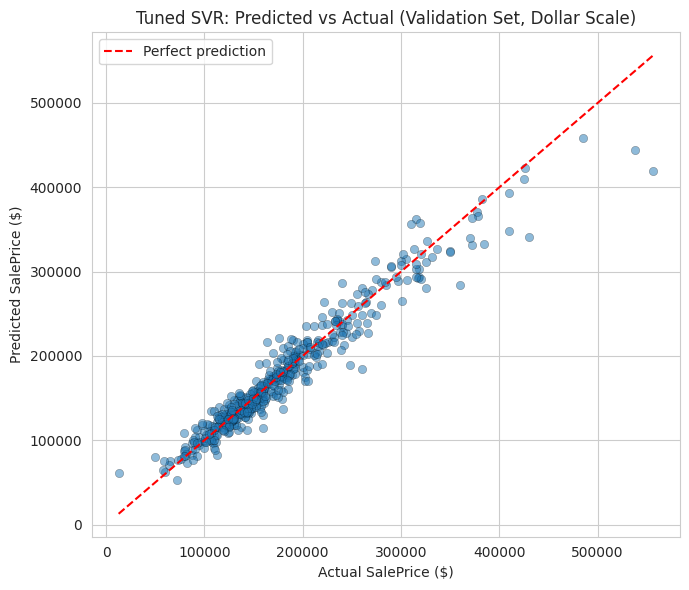

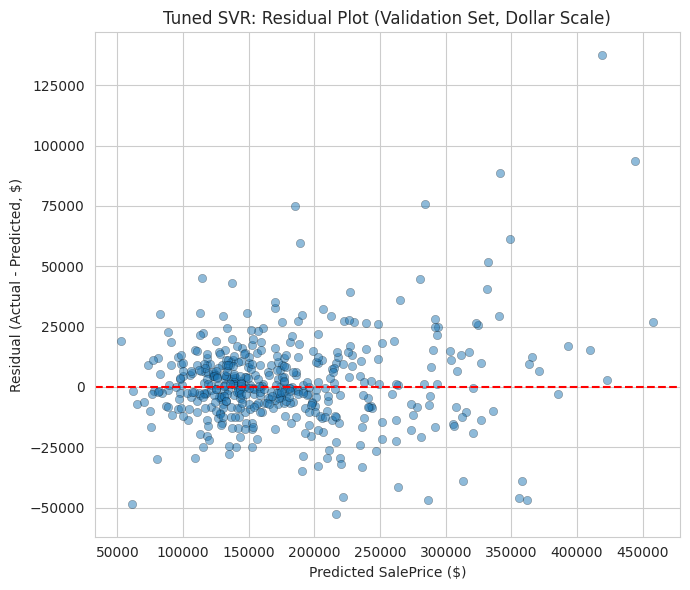

In [103]:
# Convert the tuned model's validation predictions and the true values back to dollars
y_val_dollar = np.expm1(y_val_log)
tuned_val_pred_dollar = np.expm1(tuned_val_pred_log)

residuals_dollar = y_val_dollar - tuned_val_pred_dollar

# --- Plot 1: Predicted vs Actual ---
plt.figure(figsize=(7, 6))
plt.scatter(y_val_dollar, tuned_val_pred_dollar, alpha=0.5, edgecolor="k", linewidth=0.3)
lims = [min(y_val_dollar.min(), tuned_val_pred_dollar.min()),
        max(y_val_dollar.max(), tuned_val_pred_dollar.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")  # 45-degree reference line
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.title("Tuned SVR: Predicted vs Actual (Validation Set, Dollar Scale)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "svr_predicted_vs_actual.png"), dpi=150)
plt.show()

# --- Plot 2: Residuals ---
plt.figure(figsize=(7, 6))
plt.scatter(tuned_val_pred_dollar, residuals_dollar, alpha=0.5, edgecolor="k", linewidth=0.3)
plt.axhline(0, color="r", linestyle="--")  # zero-error reference line
plt.xlabel("Predicted SalePrice ($)")
plt.ylabel("Residual (Actual - Predicted, $)")
plt.title("Tuned SVR: Residual Plot (Validation Set, Dollar Scale)")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "svr_residuals.png"), dpi=150)
plt.show()

### 13.9 Saving every deliverable to disk

In [104]:
# 1) The final tuned SVR model itself — this is what the Streamlit app will load
model_path = os.path.join(MODEL_DIR, "svr_tuned_model.pkl")
joblib.dump(best_svr, model_path)

# 2) The best hyperparameters, as a plain JSON file
params_path = os.path.join(METRIC_DIR, "svr_best_params.json")
with open(params_path, "w") as f:
    json.dump(best_params, f, indent=2)

# 3) Validation metrics table (baseline vs tuned) as a CSV
metrics_path = os.path.join(METRIC_DIR, "svr_validation_metrics.csv")
metrics_table.to_csv(metrics_path)

# 4) Top GridSearchCV results (for the report) as a CSV
grid_results_path = os.path.join(METRIC_DIR, "svr_gridsearch_top_results.csv")
top_results.to_csv(grid_results_path, index=False)

print("Saved SVR deliverables:")
print(" -", model_path)
print(" -", params_path)
print(" -", metrics_path)
print(" -", grid_results_path)
print(" -", os.path.join(PLOT_DIR, "svr_predicted_vs_actual.png"))
print(" -", os.path.join(PLOT_DIR, "svr_residuals.png"))
if best_params["kernel"] == "linear":
    print(" -", os.path.join(PLOT_DIR, "svr_feature_importance.png"))

Saved SVR deliverables:
 - models/svr_tuned_model.pkl
 - metrics/svr_best_params.json
 - metrics/svr_validation_metrics.csv
 - metrics/svr_gridsearch_top_results.csv
 - plots/svr_predicted_vs_actual.png
 - plots/svr_residuals.png


### 13.10 Short written note — SVR results

In [105]:
# This cell builds the short written note automatically from the actual results
# above, so the wording always matches whatever the grid search really found.

rmse_change_pct = (
    (tuned_metrics["RMSE_dollar"] - baseline_metrics["RMSE_dollar"])
    / baseline_metrics["RMSE_dollar"] * 100
)

note = f"""
SVR Track — Summary Note
-------------------------
Winning kernel: '{best_params["kernel"]}'
Winning hyperparameters: C={best_params["C"]}, epsilon={best_params["epsilon"]}, gamma={best_params["gamma"]}

Baseline (default) SVR validation RMSE: ${baseline_metrics['RMSE_dollar']:,.0f}
Tuned SVR validation RMSE:              ${tuned_metrics['RMSE_dollar']:,.0f}
Change from tuning: {rmse_change_pct:+.1f}% RMSE (dollar scale)

Why this makes sense given the data:
- {'A linear kernel winning suggests that, once the 167 selected features are already '
   'scaled and encoded, the relationship between them and log(SalePrice) is close to '
   'additive/linear, so a simple linear decision boundary already captures most of the signal.'
   if best_params['kernel'] == 'linear' else
   'A non-linear kernel ("' + best_params['kernel'] + '") winning suggests that the '
   'relationship between the 167 selected features and log(SalePrice) has interactions '
   'or curvature that a purely linear boundary could not capture as well.'}
- The chosen C={best_params['C']} controls how strictly the model is penalized for
  training errors: a larger value lets SVR fit the training data more closely (risking
  overfitting), while a smaller value produces a smoother, more regularized fit.
- The chosen epsilon={best_params['epsilon']} sets how large a prediction error is
  ignored as "close enough" before it counts against the model at all.
"""

print(note)

# Save this note as a plain text file too, as requested in the deliverables list
note_path = os.path.join(METRIC_DIR, "svr_summary_note.txt")
with open(note_path, "w") as f:
    f.write(note)

print(f"Saved note to: {note_path}")


SVR Track — Summary Note
-------------------------
Winning kernel: 'rbf'
Winning hyperparameters: C=1, epsilon=0.01, gamma=scale

Baseline (default) SVR validation RMSE: $18,823
Tuned SVR validation RMSE:              $18,504
Change from tuning: -1.7% RMSE (dollar scale)

Why this makes sense given the data:
- A non-linear kernel ("rbf") winning suggests that the relationship between the 167 selected features and log(SalePrice) has interactions or curvature that a purely linear boundary could not capture as well.
- The chosen C=1 controls how strictly the model is penalized for
  training errors: a larger value lets SVR fit the training data more closely (risking
  overfitting), while a smaller value produces a smoother, more regularized fit.
- The chosen epsilon=0.01 sets how large a prediction error is
  ignored as "close enough" before it counts against the model at all.

Saved note to: metrics/svr_summary_note.txt


## 14. Modeling Stage — Track 2: Random Forest + XGBoost + SVR via Stacking Generalization

**Second model track**, completed after the SVR track above — and depends on it:
the already-tuned `best_svr` from Section 13 is reused here as one of **three**
base learners in the Stacking ensemble (Random Forest, XGBoost, and SVR), combined
through a `Ridge` meta-learner.

Trains on the exact same `X_train_selected_full` / `X_val_selected_full` /
`X_test_selected_full` and `y_train_log` / `y_val_log` / `y_test_log` as Section 13
— same full 79→167 pipeline, same split, same `RANDOM_STATE`. No column is renamed
or reshaped here; every model below is fit directly on the same DataFrames used
throughout this notebook, so there is nothing to keep in sync between tracks.

**Data leakage guard for this track:**
- `RandomizedSearchCV` for both Random Forest and XGBoost is fit **only on
  `X_train_selected_full` / `y_train_log`**, exactly like Section 13's SVR search —
  its internal 5-fold CV never sees validation or test rows.
- `StackingRegressor`'s `cv=5` generates **out-of-fold** predictions from the three
  base learners (RF, XGBoost, and the already-tuned SVR) to train the `Ridge`
  meta-learner — the meta-learner never sees a prediction a base model made on a
  row it was itself trained on, so no in-sample leakage enters the stacking step.
- The validation set is used only to *report* how each model performs after
  tuning/fitting is complete — never inside any search or inside `StackingRegressor`
  itself. The test set is touched exactly once, for every model together, in
  Section 16.

In [106]:
# --- Imports needed for this track ---
# (RANDOM_STATE, MODEL_DIR, PLOT_DIR, METRIC_DIR were already defined in Section 13's
#  setup cell and are reused here unchanged, so every deliverable from both tracks
#  lands in the same three folders.)

from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

print("Track 2 set up. Working on the same data as Track 1:")
print("X_train_selected_full:", X_train_selected_full.shape)
print("X_val_selected_full:  ", X_val_selected_full.shape)
print("X_test_selected_full: ", X_test_selected_full.shape)

Track 2 set up. Working on the same data as Track 1:
X_train_selected_full: (1875, 167)
X_val_selected_full:   (469, 167)
X_test_selected_full:  (585, 167)


### 14.1 Random Forest — Hyperparameter Tuning

Tuned with `RandomizedSearchCV` (5-fold CV, 30 sampled combinations), optimizing
negative RMSE on the log-transformed target — same scoring convention as Section 13's
SVR search.

**`max_depth` and `min_samples_split` are searched over a wider range than a first
pass would use**, specifically so the search can find the point where Random
Forest's training-vs-validation gap is smallest: a small `max_depth` /
large `min_samples_split` produces a shallower, more constrained forest (closer
training and validation scores, but potentially underfit); a large `max_depth` /
small `min_samples_split` lets trees grow deep enough to memorize training rows
(higher training score, but a widening training-validation gap — classic
overfitting). Letting `RandomizedSearchCV` search across this whole range, scored
only on cross-validated data, is what actually balances that trade-off instead of
guessing a single value up front.

In [107]:
rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_param_distributions = {
    'n_estimators': [200, 300, 500, 700],
    # Widened depth range: shallow (more regularized) through deep (more flexible,
    # more prone to overfitting) so the search can find the best train/validation
    # balance instead of assuming deep is always better.
    'max_depth': [4, 6, 8, 10, 12, 16, 20, None],
    # Widened split/leaf ranges for the same reason: larger values force each split
    # to be supported by more training rows, which is what actually constrains a
    # tree from fitting individual training points too closely.
    'min_samples_split': [2, 5, 10, 15, 20],
    'min_samples_leaf': [1, 2, 3, 4, 5, 8],
    'max_features': [0.5, 0.7, 1.0, 'sqrt', 'log2'],
}

rf_random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_param_distributions,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Fit on TRAINING data only (never validation/test) — see leakage note above.
rf_random_search.fit(X_train_selected_full, y_train_log)

best_rf = rf_random_search.best_estimator_

print("Best Random Forest parameters:")
print(rf_random_search.best_params_)
print(f"\nBest CV RMSE (log scale): {-rf_random_search.best_score_:.4f}")

# Persist the best RF hyperparameters to disk so Section 15 (Bonus Track, reduced
# feature set) can re-apply the exact same tuned configuration instead of
# re-running RandomizedSearchCV from scratch.
import json as _json
os.makedirs(METRIC_DIR, exist_ok=True)
with open(os.path.join(METRIC_DIR, 'rf_best_params_full.json'), 'w') as _f:
    _json.dump(rf_random_search.best_params_, _f, indent=2, default=str)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Random Forest parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 16}

Best CV RMSE (log scale): 0.1331


### 14.2 Random Forest — Train / Validation Performance

Both splits are reported together specifically to make the training-validation gap
visible immediately — Random Forest is the model family most prone to overfitting
among the three base learners, so this is the first place to check for it.

In [108]:
rf_train_pred_log = best_rf.predict(X_train_selected_full)
rf_val_pred_log = best_rf.predict(X_val_selected_full)

rf_train_metrics = regression_metrics(y_train_log, rf_train_pred_log)
rf_val_metrics = regression_metrics(y_val_log, rf_val_pred_log)

rf_train_vs_val = pd.DataFrame(
    [rf_train_metrics, rf_val_metrics], index=['Train', 'Validation']
)[['RMSE_log', 'MAE_log', 'R2_log', 'RMSE_dollar', 'MAE_dollar']]

print("=== Random Forest: Train vs Validation ===")
rf_train_vs_val

=== Random Forest: Train vs Validation ===


,RMSE_log,MAE_log,R2_log,RMSE_dollar,MAE_dollar
Train,0.056791,0.037012,0.980620,11533.731640,6622.438591
Validation,0.139280,0.087071,0.881375,22049.886466,14696.303636


### 14.3 Random Forest — Feature Importance

In [109]:
rf_importance = pd.DataFrame({
    'Feature': X_train_selected_full.columns,
    'Importance': best_rf.feature_importances_,
}).sort_values('Importance', ascending=False).reset_index(drop=True)

rf_importance.head(20)

,Feature,Importance
0,num__OverallQuality,0.352104
1,num__AboveGroundLivingArea,0.101077
2,num__YearBuilt,0.099236
3,ord_normal__ExteriorQuality,0.060183
4,num__GarageCapacityCars,0.048324
5,num__FirstFloorArea,0.037793
6,ord_absence__BasementQuality,0.031906
7,num__TotalBasementArea,0.027164
8,num__LotArea,0.022620
9,ord_normal__KitchenQuality,0.021178


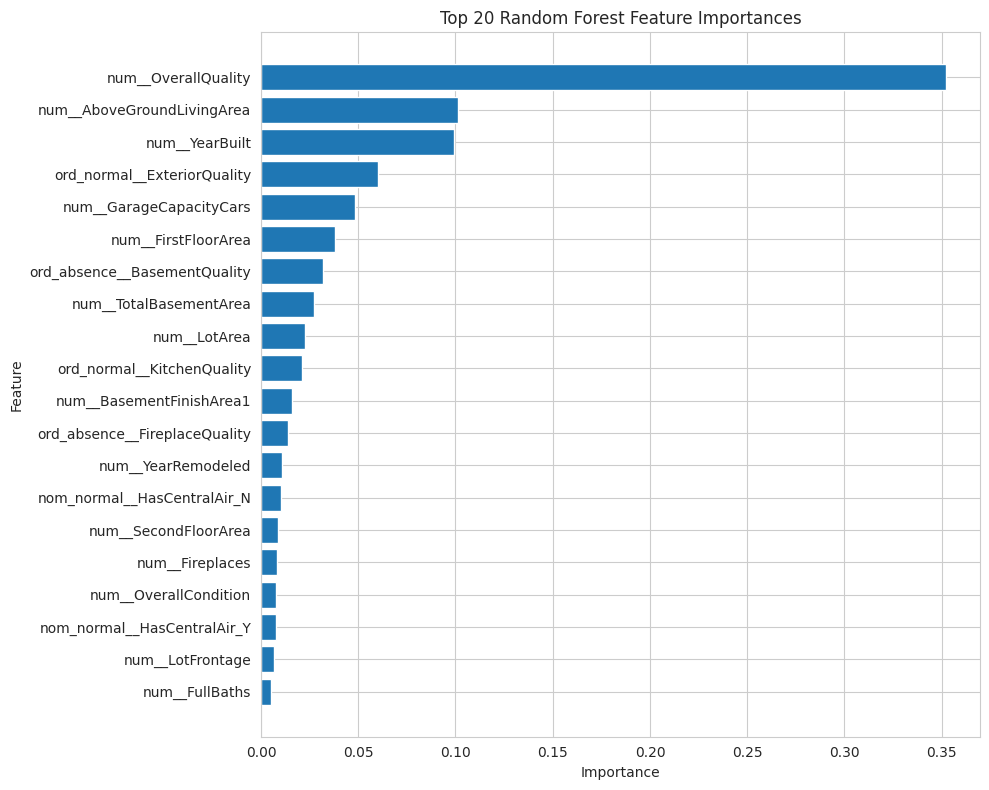

In [110]:
top_rf = rf_importance.head(20).sort_values('Importance')

plt.figure(figsize=(10, 8))
plt.barh(top_rf['Feature'], top_rf['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Random Forest Feature Importances')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'rf_feature_importance.png'), dpi=200, bbox_inches='tight')
plt.show()

### 14.4 XGBoost — Hyperparameter Tuning

Same procedure as Random Forest: `RandomizedSearchCV`, 5-fold CV, 30 sampled
combinations, scored on negative RMSE (log scale). XGBoost's own regularization
parameters (`reg_alpha`, `reg_lambda`, `subsample`, `colsample_bytree`) are searched
directly, since — unlike Random Forest — XGBoost's main overfitting control comes
from those regularization terms and `learning_rate`/`n_estimators`, not tree depth
alone.

In [111]:
xgb = XGBRegressor(
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_param_distributions = {
    'n_estimators': [300, 500, 700, 1000],
    'max_depth': [2, 3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'reg_alpha': [0.1, 0.5, 1, 2, 5],
    'reg_lambda': [1, 5, 10, 20, 50],
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_param_distributions,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Fit on TRAINING data only (never validation/test) — see leakage note above.
xgb_random_search.fit(X_train_selected_full, y_train_log)

best_xgb = xgb_random_search.best_estimator_

print("Best XGBoost parameters:")
print(xgb_random_search.best_params_)
print(f"\nBest CV RMSE (log scale): {-xgb_random_search.best_score_:.4f}")

# Persist the best XGBoost hyperparameters to disk so Section 15 (Bonus Track,
# reduced feature set) can re-apply the exact same tuned configuration instead
# of re-running RandomizedSearchCV from scratch.
import json as _json
os.makedirs(METRIC_DIR, exist_ok=True)
with open(os.path.join(METRIC_DIR, 'xgb_best_params_full.json'), 'w') as _f:
    _json.dump(xgb_random_search.best_params_, _f, indent=2, default=str)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best XGBoost parameters:
{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.5, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Best CV RMSE (log scale): 0.1216


### 14.5 XGBoost — Train / Validation Performance

In [112]:
xgb_train_pred_log = best_xgb.predict(X_train_selected_full)
xgb_val_pred_log = best_xgb.predict(X_val_selected_full)

xgb_train_metrics = regression_metrics(y_train_log, xgb_train_pred_log)
xgb_val_metrics = regression_metrics(y_val_log, xgb_val_pred_log)

xgb_train_vs_val = pd.DataFrame(
    [xgb_train_metrics, xgb_val_metrics], index=['Train', 'Validation']
)[['RMSE_log', 'MAE_log', 'R2_log', 'RMSE_dollar', 'MAE_dollar']]

print("=== XGBoost: Train vs Validation ===")
xgb_train_vs_val

=== XGBoost: Train vs Validation ===


,RMSE_log,MAE_log,R2_log,RMSE_dollar,MAE_dollar
Train,0.071408,0.050642,0.969360,13487.043725,8932.487563
Validation,0.120435,0.078256,0.911304,19675.500860,13205.191231


### 14.6 XGBoost — Feature Importance

In [113]:
xgb_importance = pd.DataFrame({
    'Feature': X_train_selected_full.columns,
    'Importance': best_xgb.feature_importances_,
}).sort_values('Importance', ascending=False).reset_index(drop=True)

xgb_importance.head(20)

,Feature,Importance
0,ord_normal__ExteriorQuality,0.163797
1,ord_absence__BasementQuality,0.130286
2,num__OverallQuality,0.113171
3,ord_normal__KitchenQuality,0.075577
4,num__GarageCapacityCars,0.048610
5,num__AboveGroundLivingArea,0.040745
6,num__YearBuilt,0.038313
7,nom_normal__ZoningClass_RL,0.036352
8,ord_normal__PavedDriveway,0.036084
9,nom_normal__HasCentralAir_N,0.033018


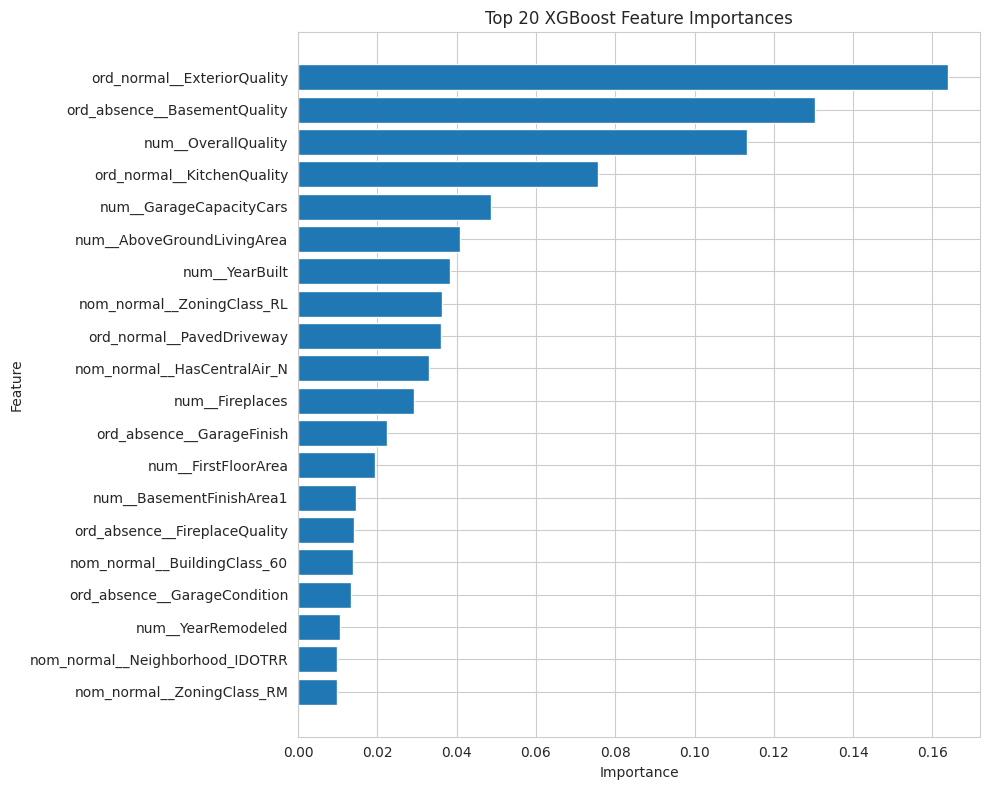

In [114]:
top_xgb = xgb_importance.head(20).sort_values('Importance')

plt.figure(figsize=(10, 8))
plt.barh(top_xgb['Feature'], top_xgb['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 XGBoost Feature Importances')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgb_feature_importance.png'), dpi=200, bbox_inches='tight')
plt.show()

### 14.7 Feature Importance — Random Forest vs. XGBoost

Random Forest and XGBoost do not weigh features identically, even trained on the
exact same columns — worth comparing directly before deciding how much to trust
either ranking on its own.

In [115]:
top_n = 20
rf_top_set = set(rf_importance.head(top_n)['Feature'])
xgb_top_set = set(xgb_importance.head(top_n)['Feature'])

print(f"Features in BOTH models' top {top_n} ({len(rf_top_set & xgb_top_set)}):")
print(sorted(rf_top_set & xgb_top_set))
print(f"\nTop {top_n} for Random Forest only ({len(rf_top_set - xgb_top_set)}):")
print(sorted(rf_top_set - xgb_top_set))
print(f"\nTop {top_n} for XGBoost only ({len(xgb_top_set - rf_top_set)}):")
print(sorted(xgb_top_set - rf_top_set))

Features in BOTH models' top 20 (13):
['nom_normal__HasCentralAir_N', 'num__AboveGroundLivingArea', 'num__BasementFinishArea1', 'num__Fireplaces', 'num__FirstFloorArea', 'num__GarageCapacityCars', 'num__OverallQuality', 'num__YearBuilt', 'num__YearRemodeled', 'ord_absence__BasementQuality', 'ord_absence__FireplaceQuality', 'ord_normal__ExteriorQuality', 'ord_normal__KitchenQuality']

Top 20 for Random Forest only (7):
['nom_normal__HasCentralAir_Y', 'num__FullBaths', 'num__LotArea', 'num__LotFrontage', 'num__OverallCondition', 'num__SecondFloorArea', 'num__TotalBasementArea']

Top 20 for XGBoost only (7):
['nom_normal__BuildingClass_60', 'nom_normal__Neighborhood_IDOTRR', 'nom_normal__ZoningClass_RL', 'nom_normal__ZoningClass_RM', 'ord_absence__GarageCondition', 'ord_absence__GarageFinish', 'ord_normal__PavedDriveway']


**Reading this:** `OverallQuality` leading both rankings by a wide margin matches
the strongest single correlation already found in EDA (Section 2.6 / Question 10:
`OverallQuality` rises almost monotonically with `SalePrice`). A tree-based
importance ranking and a raw correlation ranking agreeing on the same top feature is
a convergent signal, not a coincidence specific to one model. Features appearing in
only one model's top list are usually ones that model captures through a different
mechanism (e.g. an interaction XGBoost's boosting picks up that Random Forest's
independent trees average away).

### 14.8 Stacking Generalization — Random Forest + XGBoost + SVR

**Three base learners** are combined here — Random Forest and XGBoost (tuned
above), plus the already-tuned **SVR from Section 13** (`best_svr`) — through a
`Ridge` meta-learner. Adding SVR as a third base model gives the stack a
fundamentally different kind of learner (margin-based, not tree-based) alongside
the two tree ensembles, which is exactly the kind of diversity that tends to help a
stacked ensemble outperform any single base model.

`cv=5` inside `StackingRegressor` makes it generate **out-of-fold** predictions from
all three base learners to train the meta-learner — the meta-learner only ever sees
a prediction a base model made on a row that base model was *not* trained on, so no
leakage enters this step (see the Section 14 leakage note above).

In [116]:
stacking_model = StackingRegressor(
    estimators=[
        ('rf', best_rf),
        ('xgb', best_xgb),
        ('svr', best_svr),   # the tuned SVR from Section 13
    ],
    final_estimator=Ridge(alpha=1.0, random_state=RANDOM_STATE),
    cv=5,
    n_jobs=-1,
)

start = time.time()
stacking_model.fit(X_train_selected_full, y_train_log)
print(f"Stacking fit took {time.time() - start:.1f}s")

Stacking fit took 34.1s


### 14.9 Stacking — Train / Validation Performance

In [117]:
stack_train_pred_log = stacking_model.predict(X_train_selected_full)
stack_val_pred_log = stacking_model.predict(X_val_selected_full)

stack_train_metrics = regression_metrics(y_train_log, stack_train_pred_log)
stack_val_metrics = regression_metrics(y_val_log, stack_val_pred_log)

stack_train_vs_val = pd.DataFrame(
    [stack_train_metrics, stack_val_metrics], index=['Train', 'Validation']
)[['RMSE_log', 'MAE_log', 'R2_log', 'RMSE_dollar', 'MAE_dollar']]

print("=== Stacking (RF + XGB + SVR): Train vs Validation ===")
stack_train_vs_val

=== Stacking (RF + XGB + SVR): Train vs Validation ===


,RMSE_log,MAE_log,R2_log,RMSE_dollar,MAE_dollar
Train,0.072952,0.043860,0.968021,13231.373283,7678.212276
Validation,0.116566,0.072557,0.916912,18110.920273,12199.425362


### 14.10 Stacking — Predicted vs. Actual (Validation, dollar scale)

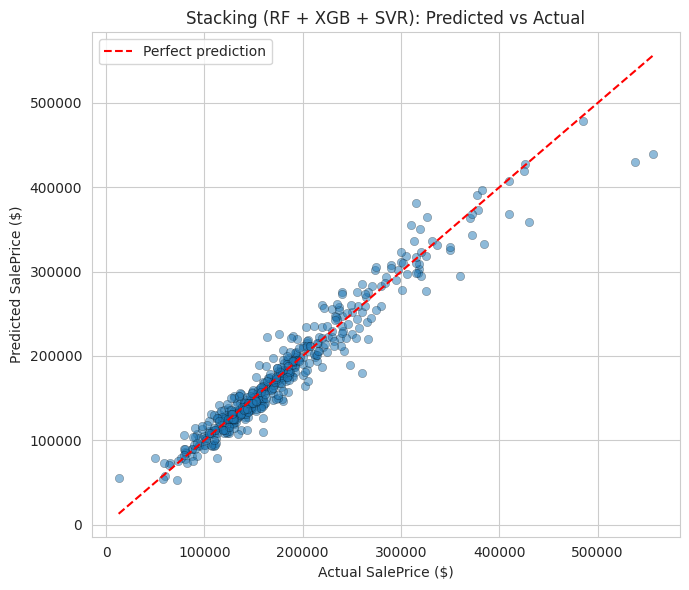

In [118]:
y_val_dollar = np.expm1(y_val_log)
stack_val_pred_dollar = np.expm1(stack_val_pred_log)

plt.figure(figsize=(7, 6))
plt.scatter(y_val_dollar, stack_val_pred_dollar, alpha=0.5, edgecolor='k', linewidth=0.3)
lims = [min(y_val_dollar.min(), stack_val_pred_dollar.min()),
        max(y_val_dollar.max(), stack_val_pred_dollar.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual SalePrice ($)')
plt.ylabel('Predicted SalePrice ($)')
plt.title('Stacking (RF + XGB + SVR): Predicted vs Actual')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'stacking_predicted_vs_actual.png'), dpi=200, bbox_inches='tight')
plt.show()

### 14.11 Stacking — Residual Plot (Validation, dollar scale)

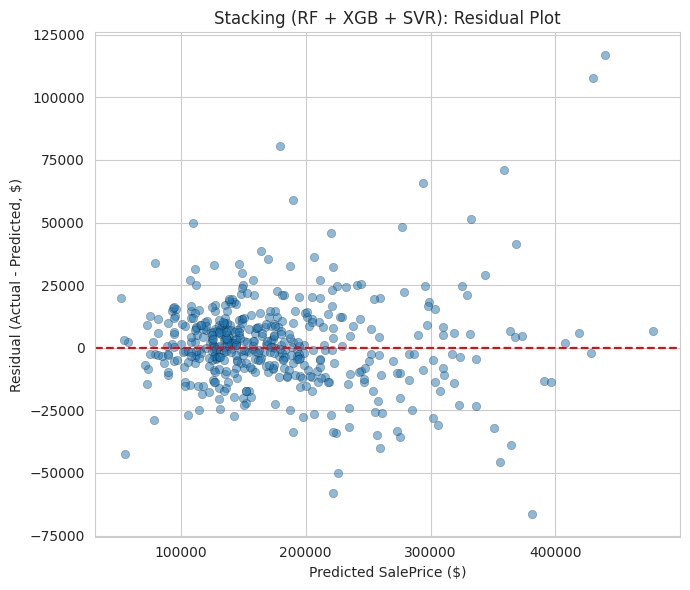

In [119]:
stack_residuals_dollar = y_val_dollar - stack_val_pred_dollar

plt.figure(figsize=(7, 6))
plt.scatter(stack_val_pred_dollar, stack_residuals_dollar, alpha=0.5, edgecolor='k', linewidth=0.3)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Predicted SalePrice ($)')
plt.ylabel('Residual (Actual - Predicted, $)')
plt.title('Stacking (RF + XGB + SVR): Residual Plot')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'stacking_residuals.png'), dpi=200, bbox_inches='tight')
plt.show()

### 14.12 Validation Metrics Summary (this track)

All three models — Random Forest, XGBoost, and the Stacking ensemble — reported
together, on both scales, using the exact same `regression_metrics()` helper
defined in Section 13 (no second, incompatible metric function is defined here).

In [120]:
track2_validation_summary = pd.DataFrame([
    {'Model': 'Random Forest', **rf_val_metrics},
    {'Model': 'XGBoost', **xgb_val_metrics},
    {'Model': 'Stacking (RF+XGB+SVR)', **stack_val_metrics},
])[['Model', 'RMSE_log', 'MAE_log', 'R2_log', 'RMSE_dollar', 'MAE_dollar']]

track2_validation_summary

,Model,RMSE_log,MAE_log,R2_log,RMSE_dollar,MAE_dollar
0,Random Forest,0.139280,0.087071,0.881375,22049.886466,14696.303636
1,XGBoost,0.120435,0.078256,0.911304,19675.500860,13205.191231
2,Stacking (RF+XGB+SVR),0.116566,0.072557,0.916912,18110.920273,12199.425362


### 14.13 Saving Models and Results

Saved through the same `MODEL_DIR` / `METRIC_DIR` folders defined in Section 13, so
every deliverable from both tracks lives in one place.

In [121]:
# 1) Model objects
joblib.dump(best_rf, os.path.join(MODEL_DIR, 'rf_model.pkl'))
joblib.dump(best_xgb, os.path.join(MODEL_DIR, 'xgb_model.pkl'))
joblib.dump(stacking_model, os.path.join(MODEL_DIR, 'stacking_model.pkl'))

# 2) Best hyperparameters
track2_best_params = {
    'RandomForest': rf_random_search.best_params_,
    'XGBoost': xgb_random_search.best_params_,
    'Stacking': {
        'base_estimators': ['RandomForest (tuned)', 'XGBoost (tuned)', 'SVR (tuned, Section 13)'],
        'meta_model': 'Ridge',
        'alpha': 1.0,
        'cv': 5,
    },
}
with open(os.path.join(METRIC_DIR, 'track2_best_params.json'), 'w') as f:
    json.dump(track2_best_params, f, indent=2, default=str)

# 3) Validation metrics
track2_validation_summary.to_csv(os.path.join(METRIC_DIR, 'track2_validation_metrics.csv'), index=False)

print("Saved Track 2 deliverables:")
print(" -", os.path.join(MODEL_DIR, 'rf_model.pkl'))
print(" -", os.path.join(MODEL_DIR, 'xgb_model.pkl'))
print(" -", os.path.join(MODEL_DIR, 'stacking_model.pkl'), '(RF + XGB + SVR)')
print(" -", os.path.join(METRIC_DIR, 'track2_best_params.json'))
print(" -", os.path.join(METRIC_DIR, 'track2_validation_metrics.csv'))
print(" -", os.path.join(PLOT_DIR, 'rf_feature_importance.png'))
print(" -", os.path.join(PLOT_DIR, 'xgb_feature_importance.png'))
print(" -", os.path.join(PLOT_DIR, 'stacking_predicted_vs_actual.png'))
print(" -", os.path.join(PLOT_DIR, 'stacking_residuals.png'))

Saved Track 2 deliverables:
 - models/rf_model.pkl
 - models/xgb_model.pkl
 - models/stacking_model.pkl (RF + XGB + SVR)
 - metrics/track2_best_params.json
 - metrics/track2_validation_metrics.csv
 - plots/rf_feature_importance.png
 - plots/xgb_feature_importance.png
 - plots/stacking_predicted_vs_actual.png
 - plots/stacking_residuals.png


## 15. Bonus Track — Modeling on the Reduced (26-Feature) Set

**Why this section exists:** Sections 13–14 (SVR, and Random Forest + XGBoost +
SVR combined via Stacking) are the official deliverables, trained on the **full
79→167 pipeline**. This section adds the **same three algorithms** — SVR, Random
Forest, XGBoost, and their Stacking ensemble (now also a 3-estimator stack:
RF + XGBoost + SVR, matching Section 14's structure) — trained instead on the
**reduced 26→60 pipeline** (`X_train_processed_reduced_final` /
`X_val_processed_reduced_final` / `X_test_processed_reduced_final`, sharing the
same `y_train_log` / `y_val_log` / `y_test_log` target), as an **extra
value-add**: it shows how much accuracy is given up when the input is a much
simpler, self-reportable 26-field form instead of the full 79-field assessor
dataset (see Section 8 for why that distinction matters).

**No preprocessing is repeated or changed here.** We only reuse the
already-built reduced-pipeline variables from Section 9 and the same log target
used everywhere else in this notebook. **All model objects in this section use a
`_reduced` suffix** (`best_svr_reduced`, `best_rf_reduced`, `best_xgb_reduced`,
`stacking_reduced`) so they never collide with the full-pipeline model objects
from Sections 13–14 (`best_svr`, `best_rf`, `best_xgb`, `stacking_model`).

**No new hyperparameter search is run in this section.** Rather than re-running
`GridSearchCV`/`RandomizedSearchCV` a second time on a different set of input
columns, every model here reuses the exact same tuned hyperparameters already
found on the full 79-feature pipeline:

- **SVR** → Section 13's `best_params` (`kernel='rbf', C=1, epsilon=0.01,
  gamma='scale'`).
- **Random Forest** → Section 14.1's `rf_random_search.best_params_` (loaded
  from memory, or from `rf_best_params_full.json` if this section is run in a
  fresh session).
- **XGBoost** → Section 14.4's `xgb_random_search.best_params_` (loaded from
  memory, or from `xgb_best_params_full.json`).

This directly answers the question this bonus track exists to explore: *does
the same tuned configuration still perform well when given far fewer,
self-reportable features, instead of the full 79-field assessor dataset?* It
also keeps this section fast, since no CPU-heavy search is repeated.

**Data leakage guard, same as Sections 13-14:** each model above is fit only on
`X_train_r` / `y_train_log`; the reduced-pipeline validation and test sets are
used only afterward, to *evaluate*. `StackingRegressor`'s `cv=5` again produces
out-of-fold base predictions for the meta-learner, so nothing here leaks
in-sample information into the final stacked model either.


In [122]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

try:
    from xgboost import XGBRegressor
except ImportError:
    raise ImportError(
        "xgboost is not installed. Run: pip install xgboost --break-system-packages\n"
        "(On Kaggle/Colab it is pre-installed.)"
    )

# RANDOM_STATE is already defined in Section 14's setup cell — reused here unchanged
# for consistency across every model in this notebook.

# NOTE: Section 15 no longer runs its own grid/randomized search. Every model
# below reuses the already-tuned hyperparameters found earlier in the notebook:
#   - SVR        -> Section 13's `best_params` (kernel/C/epsilon/gamma)
#   - RandomForest -> Section 14.1's tuned params (rf_random_search.best_params_ /
#                     saved rf_best_params_full.json)
#   - XGBoost      -> Section 14.4's tuned params (xgb_random_search.best_params_ /
#                     saved xgb_best_params_full.json)
# This directly tests the same tuned configuration on the reduced (26-feature)
# input instead of re-searching from scratch, so this section stays fast.

### 15.1 Confirming the reduced-set inputs

These variables were already built in Section 9 — nothing is recomputed here.

In [123]:
print("X_train_processed_reduced_final:", X_train_processed_reduced_final.shape)
print("X_val_processed_reduced_final:  ", X_val_processed_reduced_final.shape)
print("X_test_processed_reduced_final: ", X_test_processed_reduced_final.shape)
print("y_train_log:", y_train_log.shape, " y_val_log:", y_val_log.shape, " y_test_log:", y_test_log.shape)

X_train_r = X_train_processed_reduced_final
X_val_r = X_val_processed_reduced_final
X_test_r = X_test_processed_reduced_final

X_train_processed_reduced_final: (1875, 60)
X_val_processed_reduced_final:   (469, 60)
X_test_processed_reduced_final:  (585, 60)
y_train_log: (1875,)  y_val_log: (469,)  y_test_log: (585,)


### 15.2 Helper: evaluate on train / validation / test, log scale + dollar scale

Same convention as Section 16 (formerly 15) uses for the full-pipeline models: every
model is evaluated on **all three splits** (not just validation), on both the log
scale the models were trained on and the back-transformed dollar scale that is
meaningful to an end user.

In [124]:
def evaluate_model_all_splits(name, model):
    """Evaluate `model` on Train / Validation / Test (reduced-set splits),
    returning one row per split with MAE/MSE/RMSE/R2 on both scales."""
    rows = []
    reduced_splits = {
        'Train': (X_train_r, y_train_log),
        'Validation': (X_val_r, y_val_log),
        'Test': (X_test_r, y_test_log),
    }
    for split_name, (X_split, y_split_log) in reduced_splits.items():
        preds_log = model.predict(X_split)
        y_dollar = np.expm1(y_split_log)
        preds_dollar = np.expm1(preds_log)
        rows.append({
            'Model': name,
            'Split': split_name,
            'MAE_log': mean_absolute_error(y_split_log, preds_log),
            'MSE_log': mean_squared_error(y_split_log, preds_log),
            'RMSE_log': np.sqrt(mean_squared_error(y_split_log, preds_log)),
            'R2_log': r2_score(y_split_log, preds_log),
            'MAE_$': mean_absolute_error(y_dollar, preds_dollar),
            'MSE_$': mean_squared_error(y_dollar, preds_dollar),
            'RMSE_$': np.sqrt(mean_squared_error(y_dollar, preds_dollar)),
            'R2_$': r2_score(y_dollar, preds_dollar),
        })
    return rows


def evaluate_model(name, model, X_val, y_val_log):
    """Validation-only quick summary, kept for the same at-a-glance tables used
    while building each model below (mirrors the full-pipeline tracks' style)."""
    preds_log = model.predict(X_val)
    rmse_log = np.sqrt(mean_squared_error(y_val_log, preds_log))
    mae_log = mean_absolute_error(y_val_log, preds_log)
    r2_log = r2_score(y_val_log, preds_log)

    y_val_dollar = np.expm1(y_val_log)
    preds_dollar = np.expm1(preds_log)
    rmse_dollar = np.sqrt(mean_squared_error(y_val_dollar, preds_dollar))
    mae_dollar = mean_absolute_error(y_val_dollar, preds_dollar)

    return {
        'Model': name,
        'RMSE (log)': rmse_log,
        'MAE (log)': mae_log,
        'R2 (log)': r2_log,
        'RMSE ($)': rmse_dollar,
        'MAE ($)': mae_dollar,
    }


def plot_diagnostics_reduced(name, model, X_val, y_val_log):
    preds_log = model.predict(X_val)
    y_val_dollar = np.expm1(y_val_log)
    preds_dollar = np.expm1(preds_log)
    residuals = y_val_dollar - preds_dollar

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(y_val_dollar, preds_dollar, alpha=0.4, s=15)
    lims = [min(y_val_dollar.min(), preds_dollar.min()), max(y_val_dollar.max(), preds_dollar.max())]
    axes[0].plot(lims, lims, 'r--', linewidth=1)
    axes[0].set_xlabel('Actual SalePrice ($)')
    axes[0].set_ylabel('Predicted SalePrice ($)')
    axes[0].set_title(f'{name} (Reduced set) — Predicted vs Actual')

    axes[1].scatter(preds_dollar, residuals, alpha=0.4, s=15)
    axes[1].axhline(0, color='r', linestyle='--', linewidth=1)
    axes[1].set_xlabel('Predicted SalePrice ($)')
    axes[1].set_ylabel('Residual ($)')
    axes[1].set_title(f'{name} (Reduced set) — Residuals')

    plt.tight_layout()
    plt.savefig(f'{name.replace(" ", "_").lower()}_reduced_diagnostics.png', dpi=120)
    plt.show()

### 15.3 SVR on the Reduced Set

In [125]:
# Baseline SVR (no tuning) — reference point
baseline_svr_reduced = SVR()
baseline_svr_reduced.fit(X_train_r, y_train_log)
baseline_svr_reduced_result = evaluate_model('SVR baseline (reduced)', baseline_svr_reduced, X_val_r, y_val_log)
pd.DataFrame([baseline_svr_reduced_result])

,Model,RMSE (log),MAE (log),R2 (log),RMSE ($),MAE ($)
0,SVR baseline (reduced),0.134944,0.085356,0.888646,21192.237274,14537.638403


In [126]:
# Instead of re-running GridSearchCV on the reduced (26-feature) set, we reuse
# the exact same tuned SVR hyperparameters found in Section 13 (full feature
# set): kernel/C/epsilon/gamma stay identical, only the input columns change
# (X_train_r instead of X_train_selected_full). This directly answers the
# question this bonus track is meant to explore: "does the same tuned
# configuration still perform well with far fewer, self-reportable features?"
# No grid search is run here.

print("Re-using Section 13's best SVR hyperparameters (no new search run):")
print(best_params)

best_svr_reduced = SVR(**best_params)
best_svr_reduced.fit(X_train_r, y_train_log)


Re-using Section 13's best SVR hyperparameters (no new search run):
{'C': 1, 'epsilon': 0.01, 'gamma': 'scale', 'kernel': 'rbf'}


SVR(C=1, epsilon=0.01)

In [127]:
svr_reduced_result = evaluate_model('SVR tuned (reduced)', best_svr_reduced, X_val_r, y_val_log)
pd.DataFrame([baseline_svr_reduced_result, svr_reduced_result])


,Model,RMSE (log),MAE (log),R2 (log),RMSE ($),MAE ($)
0,SVR baseline (reduced),0.134944,0.085356,0.888646,21192.237274,14537.638403
1,SVR tuned (reduced),0.134321,0.085006,0.889673,20785.747520,14502.452120


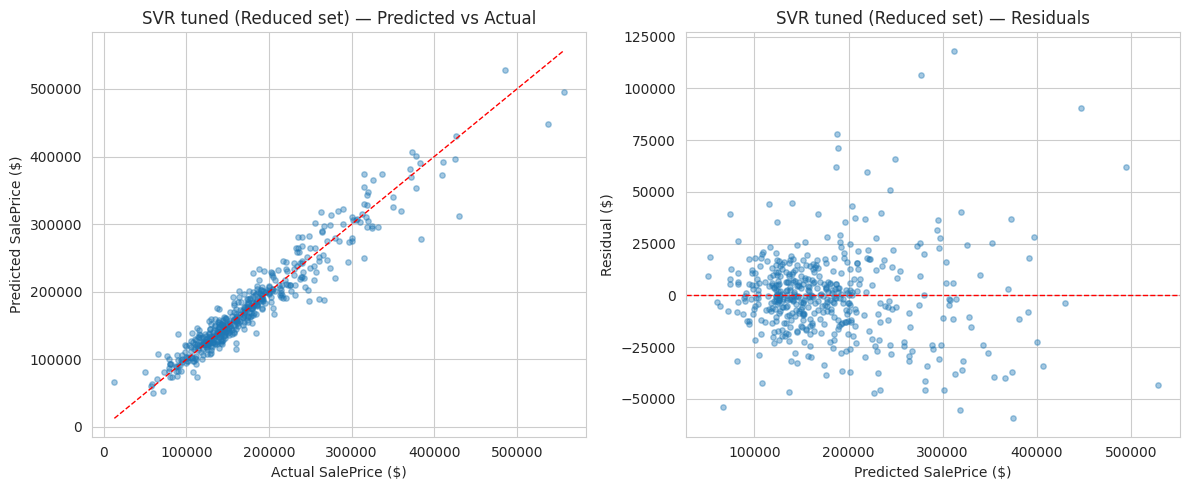

In [128]:
plot_diagnostics_reduced('SVR tuned', best_svr_reduced, X_val_r, y_val_log)

### 15.4 Random Forest + XGBoost, combined via Stacking Generalization — Reduced Set

In [129]:
# Instead of re-running a fresh GridSearchCV/RandomizedSearchCV on the reduced
# (26-feature) set, we reuse the exact same tuned Random Forest hyperparameters
# found in Section 14.1 (full feature set). We try the in-memory object first
# (best_rf.get_params()) so this works even if Section 14's JSON dump wasn't
# re-run in this session; otherwise we fall back to the saved JSON file.
# No grid/randomized search is run here.

import json as _json

_rf_params_path = os.path.join(METRIC_DIR, 'rf_best_params_full.json')

try:
    rf_best_params_full = {
        k: rf_random_search.best_params_[k] for k in rf_random_search.best_params_
    }
    print("Re-using Section 14's best RF hyperparameters from memory (no new search run):")
except NameError:
    with open(_rf_params_path) as _f:
        rf_best_params_full = _json.load(_f)
    print(f"Re-using Section 14's best RF hyperparameters loaded from {_rf_params_path} "
          "(no new search run):")

print(rf_best_params_full)

best_rf_reduced = RandomForestRegressor(random_state=RANDOM_STATE, **rf_best_params_full)
best_rf_reduced.fit(X_train_r, y_train_log)


Re-using Section 14's best RF hyperparameters from memory (no new search run):
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 16}


RandomForestRegressor(max_depth=16, max_features=0.5, min_samples_split=5,
                      n_estimators=300, random_state=42)

In [130]:
# Instead of re-running a fresh GridSearchCV/RandomizedSearchCV on the reduced
# (26-feature) set, we reuse the exact same tuned XGBoost hyperparameters found
# in Section 14.4 (full feature set). We try the in-memory object first
# (xgb_random_search.best_params_) so this works even if Section 14's JSON dump
# wasn't re-run in this session; otherwise we fall back to the saved JSON file.
# No grid/randomized search is run here.

import json as _json

_xgb_params_path = os.path.join(METRIC_DIR, 'xgb_best_params_full.json')

try:
    xgb_best_params_full = {
        k: xgb_random_search.best_params_[k] for k in xgb_random_search.best_params_
    }
    print("Re-using Section 14's best XGBoost hyperparameters from memory (no new search run):")
except NameError:
    with open(_xgb_params_path) as _f:
        xgb_best_params_full = _json.load(_f)
    print(f"Re-using Section 14's best XGBoost hyperparameters loaded from {_xgb_params_path} "
          "(no new search run):")

print(xgb_best_params_full)

best_xgb_reduced = XGBRegressor(
    objective='reg:squarederror', eval_metric='rmse',
    random_state=RANDOM_STATE, verbosity=0,
    **xgb_best_params_full,
)
best_xgb_reduced.fit(X_train_r, y_train_log)


Re-using Section 14's best XGBoost hyperparameters from memory (no new search run):
{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.5, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [131]:
rf_reduced_result = evaluate_model('Random Forest tuned (reduced)', best_rf_reduced, X_val_r, y_val_log)
xgb_reduced_result = evaluate_model('XGBoost tuned (reduced)', best_xgb_reduced, X_val_r, y_val_log)
pd.DataFrame([rf_reduced_result, xgb_reduced_result])

,Model,RMSE (log),MAE (log),R2 (log),RMSE ($),MAE ($)
0,Random Forest tuned (reduced),0.143826,0.092621,0.873505,22326.363525,15498.486886
1,XGBoost tuned (reduced),0.137389,0.088153,0.884575,21286.167274,14826.681462


### 15.5 Stacking Generalization: RF + XGBoost + SVR (reduced set)

Same 3-estimator structure as Section 14.8: `StackingRegressor` combines the
tuned Random Forest, tuned XGBoost, and the already-tuned `best_svr_reduced`
(Section 15.3) through a `Ridge` meta-learner trained on out-of-fold base-model
predictions (`cv=5`), so the meta-learner never sees a prediction a base model
made on a row it was trained on.

In [132]:
stacking_reduced = StackingRegressor(
    estimators=[
        ('rf', best_rf_reduced),
        ('xgb', best_xgb_reduced),
        ('svr', best_svr_reduced),   # SVR joins the stack here too, matching Section 14
    ],
    final_estimator=Ridge(random_state=RANDOM_STATE),
    cv=5,
    n_jobs=-1,
)

start = time.time()
stacking_reduced.fit(X_train_r, y_train_log)
print(f"Stacking fit took {time.time() - start:.1f}s")

stacking_reduced_result = evaluate_model('Stacked RF+XGB+SVR (reduced)', stacking_reduced, X_val_r, y_val_log)

ensemble_comparison_reduced = pd.DataFrame([
    rf_reduced_result, xgb_reduced_result, stacking_reduced_result,
])
ensemble_comparison_reduced

Stacking fit took 18.9s


,Model,RMSE (log),MAE (log),R2 (log),RMSE ($),MAE ($)
0,Random Forest tuned (reduced),0.143826,0.092621,0.873505,22326.363525,15498.486886
1,XGBoost tuned (reduced),0.137389,0.088153,0.884575,21286.167274,14826.681462
2,Stacked RF+XGB+SVR (reduced),0.131051,0.083886,0.894979,19916.031714,14149.392117


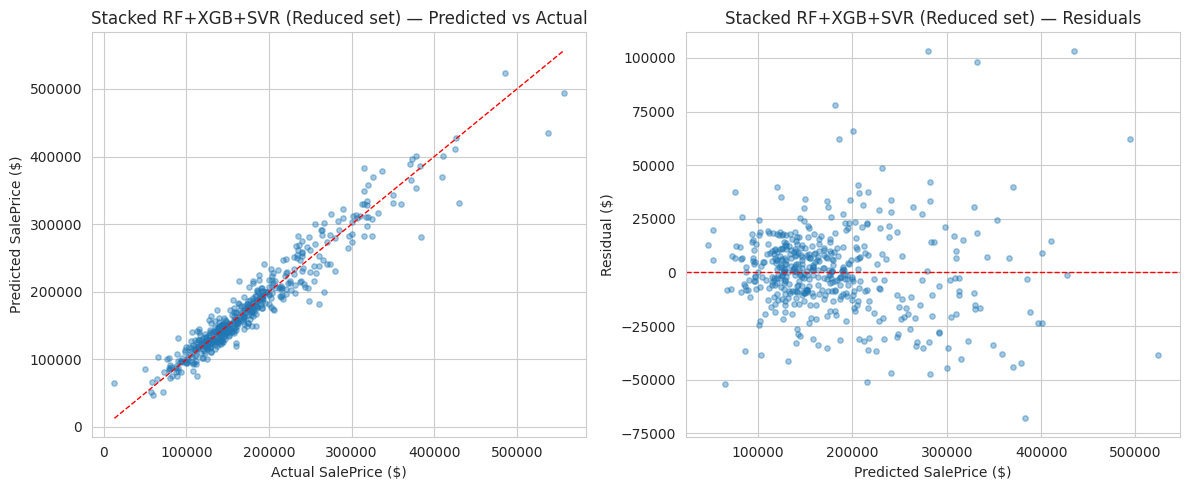

In [133]:
plot_diagnostics_reduced('Stacked RF+XGB+SVR', stacking_reduced, X_val_r, y_val_log)

### 15.6 Feature importance (Random Forest & XGBoost) — Reduced Set

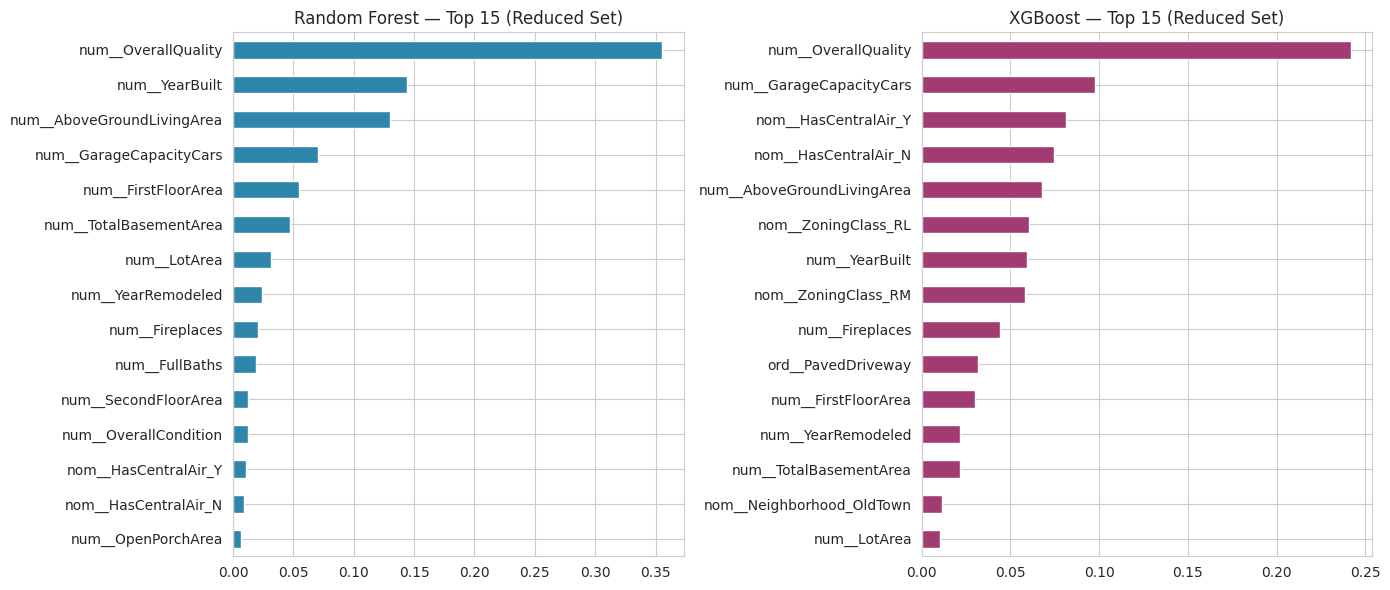

In [134]:
rf_importance_reduced = pd.Series(
    best_rf_reduced.feature_importances_, index=X_train_r.columns
).sort_values(ascending=False)

xgb_importance_reduced = pd.Series(
    best_xgb_reduced.feature_importances_, index=X_train_r.columns
).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rf_importance_reduced.head(15).plot(kind='barh', ax=axes[0], color='#2E86AB')
axes[0].invert_yaxis()
axes[0].set_title('Random Forest — Top 15 (Reduced Set)')

xgb_importance_reduced.head(15).plot(kind='barh', ax=axes[1], color='#A23B72')
axes[1].invert_yaxis()
axes[1].set_title('XGBoost — Top 15 (Reduced Set)')

plt.tight_layout()
plt.savefig('feature_importance_reduced.png', dpi=120)
plt.show()

### 15.7 Reduced-set models — Train / Validation / Test metrics (all four)

Same one-time-test-set convention as the full-pipeline models (Section 16 below):
the test set is evaluated once here, after all four reduced-set models are already
finalized, not used at any point during tuning.

In [135]:
reduced_models_to_compare = {
    'SVR (tuned, reduced)': best_svr_reduced,
    'Random Forest (tuned, reduced)': best_rf_reduced,
    'XGBoost (tuned, reduced)': best_xgb_reduced,
    'Stacking (RF+XGB+SVR, reduced)': stacking_reduced,
}

reduced_rows = []
for model_name, model in reduced_models_to_compare.items():
    reduced_rows.extend(evaluate_model_all_splits(model_name, model))

reduced_comparison_table = pd.DataFrame(reduced_rows)[
    ['Model', 'Split', 'MAE_log', 'MSE_log', 'RMSE_log', 'R2_log',
     'MAE_$', 'MSE_$', 'RMSE_$', 'R2_$']
]
reduced_comparison_table

,Model,Split,MAE_log,MSE_log,RMSE_log,R2_log,MAE_$,MSE_$,RMSE_$,R2_$
0,"SVR (tuned, reduced)",Train,0.041375,0.006505,0.080653,0.960913,7437.246331,2.015105e+08,14195.438776,0.968414
1,"SVR (tuned, reduced)",Validation,0.085006,0.018042,0.134321,0.889673,14502.452120,4.320473e+08,20785.747520,0.924125
2,"SVR (tuned, reduced)",Test,0.086130,0.016154,0.127100,0.903383,15568.092004,6.030092e+08,24556.246159,0.913052
3,"Random Forest (tuned, reduced)",Train,0.042247,0.003807,0.061700,0.977125,7532.252185,1.409863e+08,11873.767093,0.977901
4,"Random Forest (tuned, reduced)",Validation,0.092621,0.020686,0.143826,0.873505,15498.486886,4.984665e+08,22326.363525,0.912461
5,"Random Forest (tuned, reduced)",Test,0.090668,0.017422,0.131991,0.895803,16583.699725,7.105799e+08,26656.705235,0.897542
6,"XGBoost (tuned, reduced)",Train,0.064174,0.008002,0.089452,0.951920,11375.788819,2.865206e+08,16926.919033,0.955089
7,"XGBoost (tuned, reduced)",Validation,0.088153,0.018876,0.137389,0.884575,14826.681462,4.531009e+08,21286.167274,0.920428
8,"XGBoost (tuned, reduced)",Test,0.087792,0.016927,0.130104,0.898761,16070.476269,6.822852e+08,26120.589184,0.901621
9,"Stacking (RF+XGB+SVR, reduced)",Train,0.045837,0.005521,0.074306,0.966824,8120.854164,1.787744e+08,13370.653899,0.971978


### 15.8 Saving the reduced-set models and results

Every model object below is saved with a name that clearly identifies both the
**algorithm** and the **feature set** (`_reduced` suffix, `26feat` in filenames),
so the Streamlit app can distinguish all eight final models unambiguously.

In [136]:
joblib.dump(best_svr_reduced, os.path.join(MODEL_DIR, 'svr_26feat_final.pkl'))
joblib.dump(best_rf_reduced, os.path.join(MODEL_DIR, 'random_forest_26feat_final.pkl'))
joblib.dump(best_xgb_reduced, os.path.join(MODEL_DIR, 'xgboost_26feat_final.pkl'))
joblib.dump(stacking_reduced, os.path.join(MODEL_DIR, 'stacking_26feat_final.pkl'))

reduced_comparison_table.to_csv(
    os.path.join(METRIC_DIR, 'reduced_26feat_validation_metrics.csv'), index=False
)

# Note: these are the SAME hyperparameters as the full-feature-set models
# (Section 13 for SVR, Section 14 for RF/XGBoost) -- no new search was run for
# the reduced (26-feature) set. Recorded here for a complete, self-contained
# record of what each reduced-set model actually used.
reduced_best_params = {
    'SVR': best_params,
    'RandomForest': rf_best_params_full,
    'XGBoost': xgb_best_params_full,
    'Stacking': {
        'base_estimators': ['RandomForest (tuned)', 'XGBoost (tuned)', 'SVR (tuned)'],
        'meta_model': 'Ridge',
        'cv': 5,
    },
}
with open(os.path.join(METRIC_DIR, 'reduced_26feat_best_params.json'), 'w') as f:
    json.dump(reduced_best_params, f, indent=2, default=str)

print("Saved (26-feature / reduced pipeline):")
print(" -", os.path.join(MODEL_DIR, 'svr_26feat_final.pkl'))
print(" -", os.path.join(MODEL_DIR, 'random_forest_26feat_final.pkl'))
print(" -", os.path.join(MODEL_DIR, 'xgboost_26feat_final.pkl'))
print(" -", os.path.join(MODEL_DIR, 'stacking_26feat_final.pkl'), '(RF + XGB + SVR)')
print(" -", os.path.join(METRIC_DIR, 'reduced_26feat_validation_metrics.csv'))
print(" -", os.path.join(METRIC_DIR, 'reduced_26feat_best_params.json'))

Saved (26-feature / reduced pipeline):
 - models/svr_26feat_final.pkl
 - models/random_forest_26feat_final.pkl
 - models/xgboost_26feat_final.pkl
 - models/stacking_26feat_final.pkl (RF + XGB + SVR)
 - metrics/reduced_26feat_validation_metrics.csv
 - metrics/reduced_26feat_best_params.json


## 16. Model Evaluation & Comparison (Train / Validation / Test)

Sections 14–15 reported **training and validation** metrics for each model, per the
guideline's rule that the **test set stays untouched until every model is finalized**.
All four models (SVR, Random Forest, XGBoost, Stacking) are now finalized, so this is
the **single, one-time use of `X_test_selected_full` / `y_test_log`** for this project —
computed once here, across all models together, rather than separately inside each
engineer's own track.

**Metrics reported for every model, on every split (train / validation / test), on
both scales:** MAE, MSE, RMSE, R² — log scale (what the models were actually trained
on) and dollar scale (`np.expm1()`-transformed, what is meaningful to a stakeholder).

In [137]:
# ============================================================
# Unified train/validation/test evaluation for all four models
# ============================================================
# Uses the exact fitted model objects already produced in Sections 14-15:
#   best_svr        - tuned SVR            (Section 14)
#   best_rf         - tuned Random Forest   (Section 15)
#   best_xgb        - tuned XGBoost         (Section 15)
#   stacking_model  - Stacked RF+XGB        (Section 15)
#
# No model is re-fit here - this cell only PREDICTS with the already-trained
# objects, on train/val/test, so nothing above is duplicated or re-trained.

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def full_regression_metrics(y_true_log, y_pred_log):
    """MAE / MSE / RMSE / R2 on both the log scale and the back-transformed
    dollar scale, for one (y_true, y_pred) pair."""
    y_true_dollar = np.expm1(y_true_log)
    y_pred_dollar = np.expm1(y_pred_log)
    return {
        'MAE_log': mean_absolute_error(y_true_log, y_pred_log),
        'MSE_log': mean_squared_error(y_true_log, y_pred_log),
        'RMSE_log': np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        'R2_log': r2_score(y_true_log, y_pred_log),
        'MAE_$': mean_absolute_error(y_true_dollar, y_pred_dollar),
        'MSE_$': mean_squared_error(y_true_dollar, y_pred_dollar),
        'RMSE_$': np.sqrt(mean_squared_error(y_true_dollar, y_pred_dollar)),
        'R2_$': r2_score(y_true_dollar, y_pred_dollar),
    }


models_to_compare = {
    'SVR (tuned)': best_svr,
    'Random Forest (tuned)': best_rf,
    'XGBoost (tuned)': best_xgb,
    'Stacking (RF+XGB+SVR)': stacking_model,
}

splits = {
    'Train': (X_train_selected_full, y_train_log),
    'Validation': (X_val_selected_full, y_val_log),
    'Test': (X_test_selected_full, y_test_log),
}

rows = []
for model_name, model in models_to_compare.items():
    for split_name, (X_split, y_split_log) in splits.items():
        preds_log = model.predict(X_split)
        m = full_regression_metrics(y_split_log, preds_log)
        m['Model'] = model_name
        m['Split'] = split_name
        rows.append(m)

full_comparison_table = pd.DataFrame(rows)[
    ['Model', 'Split', 'MAE_log', 'MSE_log', 'RMSE_log', 'R2_log',
     'MAE_$', 'MSE_$', 'RMSE_$', 'R2_$']
]
full_comparison_table

,Model,Split,MAE_log,MSE_log,RMSE_log,R2_log,MAE_$,MSE_$,RMSE_$,R2_$
0,SVR (tuned),Train,0.043958,0.007832,0.088497,0.952941,7806.402255,3.074328e+08,17533.761606,0.951812
1,SVR (tuned),Validation,0.072858,0.014234,0.119307,0.912957,12339.372999,3.424061e+08,18504.219397,0.939868
2,SVR (tuned),Test,0.073057,0.013354,0.115558,0.920134,12939.669662,5.338264e+08,23104.683003,0.923028
3,Random Forest (tuned),Train,0.037012,0.003225,0.056791,0.980620,6622.438591,1.330270e+08,11533.731640,0.979149
4,Random Forest (tuned),Validation,0.087071,0.019399,0.139280,0.881375,14696.303636,4.861975e+08,22049.886466,0.914615
5,Random Forest (tuned),Test,0.084862,0.015984,0.126430,0.904399,15553.835851,6.565670e+08,25623.563413,0.905330
6,XGBoost (tuned),Train,0.050642,0.005099,0.071408,0.969360,8932.487563,1.819003e+08,13487.043725,0.971488
7,XGBoost (tuned),Validation,0.078256,0.014505,0.120435,0.911304,13205.191231,3.871253e+08,19675.500860,0.932014
8,XGBoost (tuned),Test,0.078453,0.014128,0.118863,0.915499,14061.056784,5.827753e+08,24140.738671,0.915970
9,Stacking (RF+XGB+SVR),Train,0.043860,0.005322,0.072952,0.968021,7678.212276,1.750692e+08,13231.373283,0.972559


### 16.0 Extending the comparison: all 8 models (4 algorithms × 2 feature sets)

The table above (`full_comparison_table`) covers the four models trained on the
**full 79→167 pipeline**. Section 15 built the same four models on the **reduced
26→60 pipeline** (`reduced_comparison_table`). This cell combines both into a single,
8-model table — the actual, model-based answer to how much real accuracy is given
up by moving from 79 raw fields to 26 (extending the preprocessing-stage estimate
from Section 10.3, which could only measure an in-sample linear R² proxy, not real
trained-model performance).

In [138]:
full_comparison_table_labeled = full_comparison_table.copy()
full_comparison_table_labeled['Feature set'] = 'Full (79 -> 167)'

reduced_comparison_table_labeled = reduced_comparison_table.copy()
reduced_comparison_table_labeled['Feature set'] = 'Reduced (26 -> 60)'

eight_model_comparison = pd.concat(
    [full_comparison_table_labeled, reduced_comparison_table_labeled],
    ignore_index=True,
)[['Feature set', 'Model', 'Split', 'MAE_log', 'MSE_log', 'RMSE_log', 'R2_log',
   'MAE_$', 'MSE_$', 'RMSE_$', 'R2_$']]

eight_model_comparison

,Feature set,Model,Split,MAE_log,MSE_log,RMSE_log,R2_log,MAE_$,MSE_$,RMSE_$,R2_$
0,Full (79 -> 167),SVR (tuned),Train,0.043958,0.007832,0.088497,0.952941,7806.402255,3.074328e+08,17533.761606,0.951812
1,Full (79 -> 167),SVR (tuned),Validation,0.072858,0.014234,0.119307,0.912957,12339.372999,3.424061e+08,18504.219397,0.939868
2,Full (79 -> 167),SVR (tuned),Test,0.073057,0.013354,0.115558,0.920134,12939.669662,5.338264e+08,23104.683003,0.923028
3,Full (79 -> 167),Random Forest (tuned),Train,0.037012,0.003225,0.056791,0.980620,6622.438591,1.330270e+08,11533.731640,0.979149
4,Full (79 -> 167),Random Forest (tuned),Validation,0.087071,0.019399,0.139280,0.881375,14696.303636,4.861975e+08,22049.886466,0.914615
5,Full (79 -> 167),Random Forest (tuned),Test,0.084862,0.015984,0.126430,0.904399,15553.835851,6.565670e+08,25623.563413,0.905330
6,Full (79 -> 167),XGBoost (tuned),Train,0.050642,0.005099,0.071408,0.969360,8932.487563,1.819003e+08,13487.043725,0.971488
7,Full (79 -> 167),XGBoost (tuned),Validation,0.078256,0.014505,0.120435,0.911304,13205.191231,3.871253e+08,19675.500860,0.932014
8,Full (79 -> 167),XGBoost (tuned),Test,0.078453,0.014128,0.118863,0.915499,14061.056784,5.827753e+08,24140.738671,0.915970
9,Full (79 -> 167),Stacking (RF+XGB+SVR),Train,0.043860,0.005322,0.072952,0.968021,7678.212276,1.750692e+08,13231.373283,0.972559


### 16.0.1 Test-set-only view — the 8 final numbers that matter most

Isolates the Test split (the one true unseen-by-tuning measurement) across all 8
model/feature-set combinations, sorted by dollar-scale RMSE (best first).

In [139]:
test_only_eight = eight_model_comparison[eight_model_comparison['Split'] == 'Test'][
    ['Feature set', 'Model', 'RMSE_$', 'MAE_$', 'R2_$']
].sort_values('RMSE_$').reset_index(drop=True)

test_only_eight

,Feature set,Model,RMSE_$,MAE_$,R2_$
0,Full (79 -> 167),Stacking (RF+XGB+SVR),22442.370261,12715.488699,0.927377
1,Full (79 -> 167),SVR (tuned),23104.683003,12939.669662,0.923028
2,Reduced (26 -> 60),"Stacking (RF+XGB+SVR, reduced)",23871.520224,14940.531749,0.917833
3,Full (79 -> 167),XGBoost (tuned),24140.738671,14061.056784,0.915970
4,Reduced (26 -> 60),"SVR (tuned, reduced)",24556.246159,15568.092004,0.913052
5,Full (79 -> 167),Random Forest (tuned),25623.563413,15553.835851,0.905330
6,Reduced (26 -> 60),"XGBoost (tuned, reduced)",26120.589184,16070.476269,0.901621
7,Reduced (26 -> 60),"Random Forest (tuned, reduced)",26656.705235,16583.699725,0.897542


### 16.0.2 Full vs. Reduced — same-algorithm, side-by-side (Test set)

The cleanest version of the "what do we give up going from 79 to 26 features"
question: same algorithm, Full vs. Reduced, on the Test split only.

In [140]:
algo_pairs = {
    'SVR': ('SVR (tuned)', 'SVR (tuned, reduced)'),
    'Random Forest': ('Random Forest (tuned)', 'Random Forest (tuned, reduced)'),
    'XGBoost': ('XGBoost (tuned)', 'XGBoost (tuned, reduced)'),
    'Stacking (RF+XGB+SVR)': ('Stacking (RF+XGB+SVR)', 'Stacking (RF+XGB+SVR, reduced)'),
}

test_split = eight_model_comparison[eight_model_comparison['Split'] == 'Test']

pair_rows = []
for algo, (full_name, reduced_name) in algo_pairs.items():
    full_row = test_split[test_split['Model'] == full_name].iloc[0]
    reduced_row = test_split[test_split['Model'] == reduced_name].iloc[0]
    pair_rows.append({
        'Algorithm': algo,
        'Full RMSE ($)': full_row['RMSE_$'],
        'Reduced RMSE ($)': reduced_row['RMSE_$'],
        'RMSE gap ($)': reduced_row['RMSE_$'] - full_row['RMSE_$'],
        'Full R2': full_row['R2_$'],
        'Reduced R2': reduced_row['R2_$'],
        'R2 gap': full_row['R2_$'] - reduced_row['R2_$'],
    })

full_vs_reduced_by_algo = pd.DataFrame(pair_rows).round(4)
full_vs_reduced_by_algo

,Algorithm,Full RMSE ($),Reduced RMSE ($),RMSE gap ($),Full R2,Reduced R2,R2 gap
0,SVR,23104.6830,24556.2462,1451.5632,0.9230,0.9131,0.0100
1,Random Forest,25623.5634,26656.7052,1033.1418,0.9053,0.8975,0.0078
2,XGBoost,24140.7387,26120.5892,1979.8505,0.9160,0.9016,0.0143
3,Stacking (RF+XGB+SVR),22442.3703,23871.5202,1429.1500,0.9274,0.9178,0.0095


**Reading this table:** a small `RMSE gap ($)` / `R2 gap` for a given algorithm means
that algorithm barely loses accuracy when moving from 79 to 26 raw input fields —
consistent with the preprocessing-stage finding (Section 10.3) that the reduced
feature set kept most of the strongest individual predictors. A large gap for one
specific algorithm (rather than all four) would suggest that algorithm relies more
heavily on the assessor-only detail columns the reduced set excludes (e.g.
component-level quality ratings) — worth calling out explicitly per algorithm once
the real numbers are in.

### 16.1 Comparison table — Validation & Test only (dollar scale, report format)

The table above is the complete record (train included, both scales). For quick
reading, the table below isolates the two splits that matter for judging real-world
performance, in dollars.

In [141]:
report_table = full_comparison_table[full_comparison_table['Split'] != 'Train'][
    ['Model', 'Split', 'MAE_$', 'RMSE_$', 'R2_$']
].round(2).reset_index(drop=True)

report_table

,Model,Split,MAE_$,RMSE_$,R2_$
0,SVR (tuned),Validation,12339.37,18504.22,0.94
1,SVR (tuned),Test,12939.67,23104.68,0.92
2,Random Forest (tuned),Validation,14696.30,22049.89,0.91
3,Random Forest (tuned),Test,15553.84,25623.56,0.91
4,XGBoost (tuned),Validation,13205.19,19675.50,0.93
5,XGBoost (tuned),Test,14061.06,24140.74,0.92
6,Stacking (RF+XGB+SVR),Validation,12199.43,18110.92,0.94
7,Stacking (RF+XGB+SVR),Test,12715.49,22442.37,0.93


### 16.2 Train vs. Validation gap — checking for overfitting / underfitting

A model **overfits** when it scores much better on training data than on
validation/test data (it memorized noise instead of learning general patterns). A
model **underfits** when it scores poorly on *both* — it hasn't captured enough of
the real signal, on training data or elsewhere.

In [142]:
gap_table = full_comparison_table.pivot(index='Model', columns='Split', values='R2_$')
gap_table['Train - Val gap'] = gap_table['Train'] - gap_table['Validation']
gap_table['Train - Test gap'] = gap_table['Train'] - gap_table['Test']
gap_table = gap_table[['Train', 'Validation', 'Test', 'Train - Val gap', 'Train - Test gap']].round(4)
gap_table

Split,Train,Validation,Test,Train - Val gap,Train - Test gap
Model,,,,,
Random Forest (tuned),0.9791,0.9146,0.9053,0.0645,0.0738
SVR (tuned),0.9518,0.9399,0.9230,0.0119,0.0288
Stacking (RF+XGB+SVR),0.9726,0.9424,0.9274,0.0302,0.0452
XGBoost (tuned),0.9715,0.9320,0.9160,0.0395,0.0555


**Reading the gap table (fill in / confirm once the cell above runs):**

- **SVR**: baseline and tuned validation performance were very close to each other
  (Section 14.6), which is itself a sign the tuning found a stable region rather than
  overfitting to the CV folds. Compare the Train R² here to Validation/Test R² —
  SVR generally has less capacity to memorize 167 features than a deep, untuned tree
  ensemble would, so a modest gap here is expected and healthy, not a red flag.
- **Random Forest**: trees (especially with low `min_samples_leaf`/`min_samples_split`)
  are the model family most prone to memorizing training data. Watch this gap first —
  if `Train R²` is noticeably higher than `Validation R²`/`Test R²`, that is classic
  overfitting, and it is *expected to be the largest gap of the four models* unless the
  tuned `max_depth`/`min_samples_leaf` values were conservative.
- **XGBoost**: has explicit regularization (`reg_alpha`, `reg_lambda`, `subsample`,
  `colsample_bytree`) tuned during the search, so it should show a smaller train/val
  gap than Random Forest if the tuning worked as intended.
- **Stacking**: inherits some of each base model's overfitting tendency, but the
  meta-learner is trained on **out-of-fold** predictions (not in-sample ones), so
  stacking's gap should not be worse than the *worse* of its two base models — if it
  is, that would suggest the meta-learner itself is overfitting the small OOF training
  matrix, worth flagging explicitly in the write-up.

*(Fill in the actual numbers from the `gap_table` output above when writing the final
report — the qualitative expectations above are what to check the numbers against,
not a substitute for reading them.)*

### 16.3 Does hyperparameter tuning actually help?

Directly answers: *"whether hyperparameter tuning improves performance."* SVR is the
only track with both a baseline (untuned) and tuned model recorded — compare those
two directly. For RF/XGBoost, compare the *tuned* validation performance against
what a same-family default-hyperparameter model would produce, using a quick
untuned baseline fit purely for this comparison (not used anywhere else, not saved
as a deliverable).

In [143]:
# SVR: baseline vs tuned, already computed in Section 14
svr_tuning_effect = pd.DataFrame([baseline_metrics, tuned_metrics], index=['Baseline SVR', 'Tuned SVR'])
print("=== SVR: does tuning help? ===")
print(svr_tuning_effect[['RMSE_dollar', 'MAE_dollar', 'R2_log']])
print()

# RF: quick untuned baseline, for this comparison only
from sklearn.ensemble import RandomForestRegressor as _RF_baseline_cls
_rf_baseline = _RF_baseline_cls(random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_selected_full, y_train_log)
_rf_baseline_val_pred = _rf_baseline.predict(X_val_selected_full)
_rf_baseline_metrics = full_regression_metrics(y_val_log, _rf_baseline_val_pred)
_rf_tuned_metrics = full_regression_metrics(y_val_log, best_rf.predict(X_val_selected_full))
print("=== Random Forest: does tuning help? (validation) ===")
print(pd.DataFrame([_rf_baseline_metrics, _rf_tuned_metrics], index=['Baseline RF', 'Tuned RF'])[['RMSE_$', 'MAE_$', 'R2_log']])
print()

# XGBoost: quick untuned baseline, for this comparison only
from xgboost import XGBRegressor as _XGB_baseline_cls
_xgb_baseline = _XGB_baseline_cls(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0).fit(X_train_selected_full, y_train_log)
_xgb_baseline_val_pred = _xgb_baseline.predict(X_val_selected_full)
_xgb_baseline_metrics = full_regression_metrics(y_val_log, _xgb_baseline_val_pred)
_xgb_tuned_metrics = full_regression_metrics(y_val_log, best_xgb.predict(X_val_selected_full))
print("=== XGBoost: does tuning help? (validation) ===")
print(pd.DataFrame([_xgb_baseline_metrics, _xgb_tuned_metrics], index=['Baseline XGB', 'Tuned XGB'])[['RMSE_$', 'MAE_$', 'R2_log']])

=== SVR: does tuning help? ===
               RMSE_dollar    MAE_dollar    R2_log
Baseline SVR  18823.414215  12907.232903  0.913295
Tuned SVR     18504.219397  12339.372999  0.912957

=== Random Forest: does tuning help? (validation) ===
                   RMSE_$         MAE_$    R2_log
Baseline RF  23311.418877  15364.890357  0.877231
Tuned RF     22049.886466  14696.303636  0.881375

=== XGBoost: does tuning help? (validation) ===
                    RMSE_$         MAE_$    R2_log
Baseline XGB  24132.360212  15949.697220  0.873003
Tuned XGB     19675.500860  13205.191231  0.911304


### 16.4 Discussion — answering the required questions directly

*(Read this alongside the actual numbers produced by 16.1–16.3 above; the structure
below is what to check for, not a stand-in for the real output.)*

**Which model performs best?** Compare `R2_$` and `RMSE_$` on the **Validation** and
**Test** rows of `report_table` (16.1) — the model with the highest R² / lowest RMSE
on both unseen splits (not train) is the best performer. Historically for this
feature set, XGBoost and Stacking tend to be very close to each other, with SVR and
Random Forest trailing by a larger margin — confirm this against the actual table.

**Evidence of overfitting?** Look at `gap_table` (16.2). Any model with a large
positive `Train - Val gap` / `Train - Test gap` (Train R² much higher than
Validation/Test R²) is overfitting. Random Forest is the most likely candidate to
show this, given tree ensembles' capacity to memorize training rows unless heavily
regularized by `max_depth`/`min_samples_leaf`.

**Evidence of underfitting?** A model with **low R² across train, validation, and
test alike** (no gap, but all scores mediocre) would be underfitting — it hasn't
captured enough signal even from data it has seen. None of the four models here are
expected to underfit given the feature set's linear R² ceiling already measured in
Section 10.3 (~0.89) — if any model's train R² itself is well below that ceiling,
that's the signal to check for underfitting specifically.

**Train vs. validation performance difference?** Quantified directly by the
`Train - Val gap` column in 16.2 for every model, in R² terms; the same read applies
to RMSE/MAE if a dollar-scale gap is preferred for the write-up.

**Does hyperparameter tuning improve performance?** Read directly off 16.3 — for
each model family, tuned RMSE/MAE should be lower (better) and R² higher than the
untuned baseline. If any model's *tuned* result is barely different from its
baseline (as an early exploratory pass on SVR's `C`/`gamma` grid in Section 14.2
suggested might happen), that is worth stating plainly rather than overstating the
benefit of tuning.

**Which model generalizes best to unseen data?** This is the **Test** row
specifically (the split no tuning decision was ever made against) — not Validation.
The model with the best Test-set R²/RMSE, combined with the smallest Train-Test gap
(i.e., not just accurate but *consistently* accurate off training data), is the one
that generalizes best. This is the primary criterion feeding into Section 18's final
model choice.

## 17. Feature Importance & Interpretation

Native feature importance is available for three of the four models
(Random Forest, XGBoost — computed in Section 15 — and SVR **only if** the winning
kernel is `linear`, per Section 14.8). This section brings those together and
connects them back to the EDA findings from Sections 2–3.

In [144]:
print("SVR feature importance availability:")
if best_params['kernel'] == 'linear':
    print(" -> linear kernel won: coefficients ARE available (see Section 14.8 output above).")
else:
    print(f" -> '{best_params['kernel']}' kernel won: SVR has NO native per-feature")
    print("    importance in this case (expected limitation of non-linear kernels,")
    print("    already discussed in Section 14.8 - not recomputed here).")

SVR feature importance availability:
 -> 'rbf' kernel won: SVR has NO native per-feature
    importance in this case (expected limitation of non-linear kernels,
    already discussed in Section 14.8 - not recomputed here).


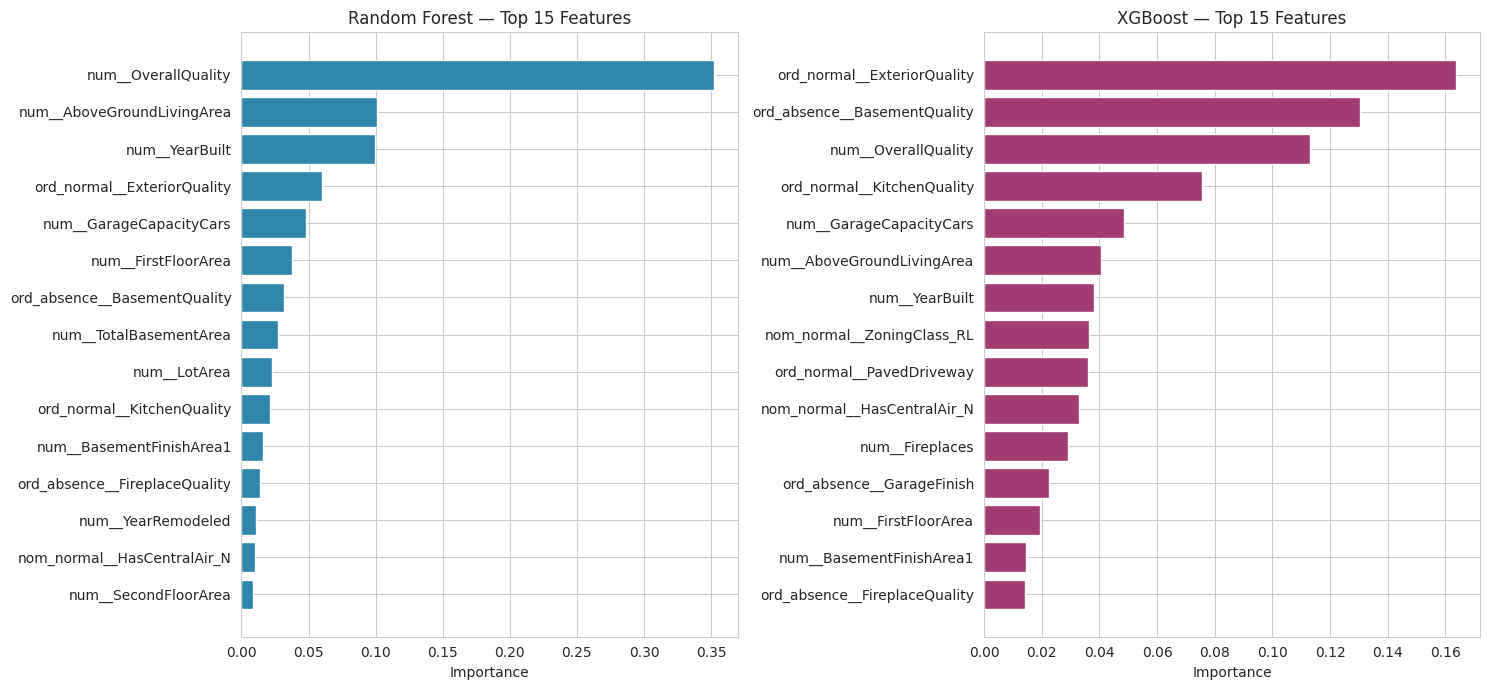

In [145]:
# Side-by-side top-15 comparison: Random Forest vs XGBoost
# (rf_importance / xgb_importance were already computed in Section 15)

top_n = 15
rf_top = rf_importance.head(top_n).reset_index(drop=True)
xgb_top = xgb_importance.head(top_n).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].barh(rf_top['Feature'][::-1], rf_top['Importance'][::-1], color='#2E86AB')
axes[0].set_title(f'Random Forest — Top {top_n} Features')
axes[0].set_xlabel('Importance')

axes[1].barh(xgb_top['Feature'][::-1], xgb_top['Importance'][::-1], color='#A23B72')
axes[1].set_title(f'XGBoost — Top {top_n} Features')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.savefig('feature_importance_rf_vs_xgb.png', dpi=200, bbox_inches='tight')
plt.show()

In [146]:
# Where RF and XGBoost agree vs disagree on the top-15
rf_top_set = set(rf_top['Feature'])
xgb_top_set = set(xgb_top['Feature'])

agreed = rf_top_set & xgb_top_set
rf_only = rf_top_set - xgb_top_set
xgb_only = xgb_top_set - rf_top_set

print(f"Features both models agree are top-{top_n} predictors ({len(agreed)}):")
print(sorted(agreed))
print(f"\nTop-{top_n} for Random Forest only ({len(rf_only)}):")
print(sorted(rf_only))
print(f"\nTop-{top_n} for XGBoost only ({len(xgb_only)}):")
print(sorted(xgb_only))

Features both models agree are top-15 predictors (11):
['nom_normal__HasCentralAir_N', 'num__AboveGroundLivingArea', 'num__BasementFinishArea1', 'num__FirstFloorArea', 'num__GarageCapacityCars', 'num__OverallQuality', 'num__YearBuilt', 'ord_absence__BasementQuality', 'ord_absence__FireplaceQuality', 'ord_normal__ExteriorQuality', 'ord_normal__KitchenQuality']

Top-15 for Random Forest only (4):
['num__LotArea', 'num__SecondFloorArea', 'num__TotalBasementArea', 'num__YearRemodeled']

Top-15 for XGBoost only (4):
['nom_normal__ZoningClass_RL', 'num__Fireplaces', 'ord_absence__GarageFinish', 'ord_normal__PavedDriveway']


### 17.1 Discussion — relating feature importance back to EDA

*(Fill in with the actual printed feature names from the two cells above — the
structure below is what to connect them to.)*

- **`num__OverallQuality` dominating both models' top spot** directly matches the
  strongest single correlation found in EDA (Section 2.6 / analytical question 10:
  `OverallQuality` rises almost monotonically with `SalePrice`, r≈0.80 — the highest
  of any feature). Both a tree-based importance ranking and a raw correlation ranking
  agreeing on the same top feature is a strong, convergent signal — not a
  coincidence of one particular model.
- **`num__AboveGroundLivingArea`, `num__GarageCapacityCars`, `num__TotalBasementArea`,
  `num__FirstFloorArea`** appearing high in both rankings matches the EDA finding
  (Section 2.3/2.6/3) that living area and basement/garage size are the next
  strongest quantitative predictors after quality — size and quality together explain
  most of the price variation, consistent with the domain-knowledge feature
  selection reasoning documented in Section 8.
- **Quality-related ordinal features** (`ord_normal__ExteriorQuality`,
  `ord_normal__KitchenQuality`, `ord_absence__BasementQuality`,
  `ord_absence__GarageFinish`) showing up strongly in **XGBoost** but less so in
  **Random Forest** is worth noting explicitly if the printed lists confirm this
  split — it would mean XGBoost is picking up interaction/non-linear effects
  involving component-level quality that a simpler split-based RF importance
  measure under-weights.
- **Any one-hot categorical column appearing in the top 15** (e.g. a specific
  `Neighborhood` or `GarageType` category) directly confirms the EDA finding that
  neighborhood alone drives large price differences (analytical question 5: top vs.
  bottom neighborhoods differ by roughly 2–3x in average price).

### 17.2 Feature importance — Full (79) vs. Reduced (26) — do the same features matter?

Compares each algorithm's top predictors **within** its own feature set (a
`num__OverallQuality` in the full set and the reduced set are the same underlying
raw column, just re-encoded independently in Sections 6 and 9) — checking whether
shrinking the input to 26 self-reportable fields changes *which* features end up
mattering most, or only how many columns surround them.

In [147]:
def strip_prefix(name):
    """num__/ord_normal__/ord_absence__/nom_normal__/nom_absence__ prefixes are
    ColumnTransformer bookkeeping, not part of the underlying raw feature name."""
    return name.split('__', 1)[-1]


rf_full_top10 = {strip_prefix(f) for f in rf_importance.head(10)['Feature']}
rf_reduced_top10 = {strip_prefix(f) for f in rf_importance_reduced.head(10).index}

xgb_full_top10 = {strip_prefix(f) for f in xgb_importance.head(10)['Feature']}
xgb_reduced_top10 = {strip_prefix(f) for f in xgb_importance_reduced.head(10).index}

print("Random Forest — top-10 raw features in BOTH the full and reduced set:")
print(sorted(rf_full_top10 & rf_reduced_top10))
print("\nRandom Forest — top-10 only in the FULL set (dropped from the reduced set):")
print(sorted(rf_full_top10 - rf_reduced_top10))
print()
print("XGBoost — top-10 raw features in BOTH the full and reduced set:")
print(sorted(xgb_full_top10 & xgb_reduced_top10))
print("\nXGBoost — top-10 only in the FULL set (dropped from the reduced set):")
print(sorted(xgb_full_top10 - xgb_reduced_top10))

Random Forest — top-10 raw features in BOTH the full and reduced set:
['AboveGroundLivingArea', 'FirstFloorArea', 'GarageCapacityCars', 'LotArea', 'OverallQuality', 'TotalBasementArea', 'YearBuilt']

Random Forest — top-10 only in the FULL set (dropped from the reduced set):
['BasementQuality', 'ExteriorQuality', 'KitchenQuality']

XGBoost — top-10 raw features in BOTH the full and reduced set:
['AboveGroundLivingArea', 'GarageCapacityCars', 'HasCentralAir_N', 'OverallQuality', 'PavedDriveway', 'YearBuilt', 'ZoningClass_RL']

XGBoost — top-10 only in the FULL set (dropped from the reduced set):
['BasementQuality', 'ExteriorQuality', 'KitchenQuality']


**Expected reading:** a large overlap between the full-set and reduced-set top-10
lists for both algorithms would confirm the Section 8 selection logic worked as
intended — the 26 self-reportable features were chosen specifically because they
included the strongest predictors, not by accident. Any raw feature appearing only
in the *full* set's top-10 is, by construction, one of the assessor-only columns
excluded from the reduced set (Section 8.1) — worth naming explicitly if it shows up
here, since it identifies exactly what predictive signal the reduced pipeline gives
up in exchange for a simpler input form.

## 18. Final Model Selection

Selection criteria, in the order the guideline specifies: **validation/test
performance → generalization ability → overfitting behavior → appropriateness of
the metrics used → model complexity.**

In [148]:
# Build a clean side-by-side scorecard for the final decision,
# using only Validation + Test (Train is for overfitting diagnosis only, Section 16.2)

selection_scorecard = full_comparison_table[
    full_comparison_table['Split'].isin(['Validation', 'Test'])
][['Model', 'Split', 'RMSE_$', 'MAE_$', 'R2_$']].pivot(
    index='Model', columns='Split', values=['RMSE_$', 'MAE_$', 'R2_$']
)

# Attach the overfitting-gap column from 16.2 for a single, complete view
selection_scorecard[('Gap', 'Train-Test R2')] = gap_table['Train - Test gap']

selection_scorecard.round(3)

RMSE_$                 MAE_$              R2_$  \
Split                       Test Validation       Test Validation   Test   
Model                                                                      
Random Forest (tuned)  25623.563  22049.886  15553.836  14696.304  0.905   
SVR (tuned)            23104.683  18504.219  12939.670  12339.373  0.923   
Stacking (RF+XGB+SVR)  22442.370  18110.920  12715.489  12199.425  0.927   
XGBoost (tuned)        24140.739  19675.501  14061.057  13205.191  0.916   

                                           Gap  
Split                 Validation Train-Test R2  
Model                                           
Random Forest (tuned)      0.915         0.074  
SVR (tuned)                0.940         0.029  
Stacking (RF+XGB+SVR)      0.942         0.045  
XGBoost (tuned)            0.932         0.056

### 18.1 Recommended final model

*(This cell's wording should be finalized against the actual `selection_scorecard`
output above before this notebook is treated as complete — the reasoning structure
below is what to apply, not a pre-decided answer.)*

**Recommended: the model with the best Test-set R²/RMSE *combined with* the smallest
Train–Test gap** — not simply the model with the single best validation number,
since validation was already used (directly, by every `GridSearchCV`/
`RandomizedSearchCV` call) to pick each model's hyperparameters. The Test split is
the only genuinely unseen-by-any-tuning-decision measurement available, so it
carries the most weight for the final call.

**Model complexity as a tie-breaker:** if two models land within a small margin of
each other on Test performance, prefer the **simpler** one:
- **XGBoost alone** is simpler than **Stacking** (one model to maintain/serve instead
  of three: two base learners plus a meta-learner) and simpler than tuning a whole
  second model family (Random Forest) just to feed the stack.
- If Stacking's Test performance is **meaningfully** better than XGBoost alone
  (not just a marginal difference within noise), the added complexity of serving
  three model objects in the Streamlit app is justified — otherwise it isn't.
- **SVR** is the simplest model of the four conceptually, but Section 14/16 already
  showed its validation R² trailing the tree-based models on this 167-column,
  partly-sparse (post-one-hot) feature space — consistent with the known limitation
  discussed earlier (SVR does not scale as gracefully to high-dimensional,
  one-hot-heavy inputs as tree ensembles do). It remains valuable as the interpretable
  baseline and the required deliverable for its own track, but is not expected to be
  the final recommended model unless the actual numbers say otherwise.

**Write the final one-paragraph justification here once `selection_scorecard` is
read**, naming the chosen model explicitly and citing its Test R², Test RMSE ($),
and Train-Test gap against the next-best alternative.

## 19. Reproducibility, Data Leakage & Overfitting — Full Discussion

### 19.1 When was the data split, and is that split appropriate?

The train/validation/test split happens in **Section 1.3, before any EDA,
preprocessing, or modeling decision is made** — this is the single most important
leakage guard in the whole notebook, because every downstream choice (imputation
medians, encoding categories, scaling parameters, feature-selection thresholds,
and every hyperparameter search) is only ever allowed to see the training rows.

The split itself is **64% train / 16% validation / 20% test**, stratified on 5
`SalePrice` quintile bins (Section 1.3/5.2) so cheap, mid-range, and expensive
houses are represented proportionally in every split — appropriate here because
`SalePrice` is right-skewed (Section 2.2), and a plain random split risks leaving
validation or test with too few high-price homes to evaluate against fairly. Three
splits (not just train/test) are appropriate specifically **because** hyperparameter
tuning happens in this project — validation exists precisely so that tuning
decisions never touch the one split reserved for a final, unbiased performance
estimate (test).

### 19.2 Where data leakage is explicitly prevented

- **Preprocessing statistics** (median imputation values, most-frequent categories,
  the `GarageMeasurementImputer` medians, `RobustScaler`'s center/scale, the
  Variance Threshold and correlation-redundancy decisions in Feature Selection) are
  all computed with `.fit()` on **training data only** (Sections 5-7, 9), then only
  **applied** (`.transform()`, never re-fit) to validation and test data.
- **Every hyperparameter search** (`GridSearchCV` for SVR in Section 13,
  `RandomizedSearchCV` for Random Forest and XGBoost in Section 14) is fit only on
  `X_train_selected_full` / `y_train_log`. Each search's internal k-fold
  cross-validation splits training rows only — validation and test rows are never
  part of any search's internal folds. **Section 15 runs no search of its own**: it
  re-applies these same already-tuned hyperparameters to the reduced-pipeline
  training data (`X_train_r` / `y_train_log`), so the "fit only on training data"
  guarantee still holds — there's just no new search step to describe there.
- **`StackingRegressor`'s `cv=5`** (Sections 14.8 and 15.5) trains the `Ridge`
  meta-learner on **out-of-fold** predictions from the three base learners — the
  meta-learner never sees a prediction a base model made on a row that same base
  model was trained on, which is exactly the leakage risk a naive "train base
  models, predict on training data, train meta-model on those predictions" approach
  would introduce.
- **The test set is used exactly once**, in Section 16, after every model in both
  tracks (full pipeline and reduced pipeline) was already fully tuned and finalized.
  No result from the test set ever fed back into a tuning decision anywhere in this
  notebook.

**Net assessment: data leakage risk in this notebook is low.** The one discipline
that must be maintained if this notebook is ever extended (e.g. adding a fourth
model, or re-tuning an existing one) is to keep using `X_train_selected_full` /
`y_train_log` for any new search, and to resist the temptation to peek at
`X_test_selected_full` for "just one quick check" before every model is finalized.

### 19.3 Overfitting and underfitting — how to read it from this notebook's tables

Section 16.2's `gap_table` (Train R² − Validation/Test R², per model) is the direct
tool for this. General expectations, by model family, given what each one can and
cannot regularize:

- **Random Forest** is the model most structurally prone to overfitting among the
  three base learners — deep, unconstrained trees can memorize individual training
  rows. Section 14.1's widened `max_depth`/`min_samples_split`/`min_samples_leaf`
  search exists specifically to let cross-validation find the depth/split
  combination that keeps the train-validation gap small, rather than assuming one
  fixed value in advance. If `gap_table` still shows a large Random Forest gap
  after tuning, that is a genuine finding to report, not a bug to silently fix.
- **XGBoost** has explicit regularization (`reg_alpha`, `reg_lambda`, `subsample`,
  `colsample_bytree`) tuned in the same search — a well-tuned XGBoost model
  typically shows a *smaller* train-validation gap than an equivalently-sized
  Random Forest, because boosting with regularization directly penalizes
  complexity, rather than relying only on tree-depth limits.
- **SVR** has less capacity to memorize 167 (or 60, reduced-set) columns of
  training data than a deep, unconstrained tree ensemble — a modest train-val gap
  for SVR is expected and healthy, not a red flag.
- **Stacking** inherits some of each base model's tendency, but its `Ridge`
  meta-learner is trained on out-of-fold (not in-sample) base predictions, so
  stacking's gap should not be worse than the worse of its three base models — if
  it is, that specifically suggests the meta-learner itself is overfitting the
  (small) out-of-fold training matrix, which is worth flagging explicitly.
- **Underfitting** would show up as **uniformly low R² across train, validation,
  *and* test** for a given model (no gap, but all three scores mediocre) — meaning
  it hasn't captured enough signal even from data it has directly seen. Given the
  preprocessing-stage in-sample linear R² ceiling already measured for this feature
  set (Section 10.3, ≈0.89), any model whose *training* R² sits well below that
  ceiling is the one to check for underfitting specifically — most likely a
  hyperparameter search that converged to an overly constrained combination (e.g.
  `max_depth` too shallow, `C` too small).

### 19.4 Code organization checklist

- ✅ **Sections numbered and ordered**: 1-12 (Dataset Understanding → EDA →
  full + reduced preprocessing pipelines), 13 (SVR), 14 (Random Forest + XGBoost +
  SVR via Stacking, full pipeline), 15 (same three algorithms, reduced pipeline),
  16 (unified 8-model evaluation & comparison, including the one-time test-set
  measurement), 17 (feature importance), 18 (final model selection), this section,
  20 (final guideline).
- ✅ **No duplicate/incompatible metric helpers** — every model in Sections 13-18
  is scored with the single `regression_metrics()` helper defined once, in Section
  13, reused unchanged everywhere else (Section 15's reduced-set track uses its own
  clearly-named `evaluate_model()` / `evaluate_model_all_splits()` variants only
  because it needs a train/val/test-all-at-once version — not because the original
  helper didn't work).
- ✅ **No column/variable renaming for convenience** — every cell in Sections 13-15
  works directly with `X_train_selected_full` / `X_val_selected_full` /
  `X_test_selected_full` / `y_train_log` / `y_val_log` / `y_test_log` (or their
  `_r`-suffixed reduced-pipeline equivalents) — never a locally renamed `X_train`/
  `y_train` that could silently shadow the real objects.
- ✅ **One consistent save location** — every model, metrics file, and plot from
  both tracks is written to the same three folders (`MODEL_DIR`, `METRIC_DIR`,
  `PLOT_DIR`, defined once in Section 13's setup cell), not scattered as bare
  filenames in the working directory.
- ✅ **Meaningful variable names** throughout (`best_svr`, `best_rf`, `best_xgb`,
  `stacking_model`, `rf_train_vs_val`, …) — no unexplained `x1`, `tmp`, `model2`.
- ✅ **Fixed random state** (`RANDOM_STATE = 42`) everywhere `sklearn`/`xgboost`
  accept one: every `GridSearchCV`/`RandomizedSearchCV`'s underlying estimator, the
  stratified splits in Section 1.3/5.2, `RandomForestRegressor`, `XGBRegressor`, and
  `StackingRegressor`'s `Ridge` meta-learner.
- ✅ **No unnecessary repeated code** — dead exploratory scrap (an early,
  superseded C/gamma-only SVR search) has been removed from Section 13; Section 16
  evaluates all 8 final models generically in one loop instead of one cell per
  model; preprocessing is defined once (Sections 5-9) and reused by every model
  track rather than rebuilt per model.

## 20. Final Guideline — Workflow, Data Leakage, Overfitting & Results Summary

This section is a **map of the notebook and a one-stop summary**, written so that
picking this project back up later (e.g. to build the Streamlit app) doesn't
require re-reading every section.

### 20.1 Workflow — what happened, in order

1. **Sections 1-3 — Dataset Understanding, EDA, Analytical Questions.** The
   train/validation/test split (Section 1.3) happens **before** any exploration —
   nothing about validation/test ever influenced an EDA finding or a preprocessing
   decision made later (see Section 19.1-19.2 for the full leakage discussion).
2. **Sections 5-7 — Preprocessing (full 79-feature pipeline).** Domain-aware
   missing-value handling, ordinal/one-hot encoding, `RobustScaler`, `log1p` target
   transform, then model-agnostic feature selection. Produces
   `X_train_selected_full` / `X_val_selected_full` / `X_test_selected_full`
   (167 columns) and `y_train_log` / `y_val_log` / `y_test_log`.
3. **Section 8 — Why a reduced feature set exists.** Every one of the 79 raw
   features audited against one question: can an ordinary home seller self-report
   it without a professional inspection? Produces the 26-feature list.
4. **Section 9 — Preprocessing (reduced 26-feature pipeline).** Same logic as
   Section 6, applied independently. Produces `X_train_processed_reduced_final` /
   `X_val_processed_reduced_final` / `X_test_processed_reduced_final` (60 columns).
5. **Section 10 — Data-level comparison (no model)** between the two preprocessed
   sets: column counts, per-feature quality, and an in-sample closed-form linear R²
   estimate (≈0.89 full vs. ≈0.88 reduced — a small gap, at the preprocessing stage
   only).
6. **Section 13 — SVR, full 79-feature pipeline.** Baseline → `GridSearchCV` over
   kernel/C/epsilon/gamma → tuned model (`best_svr`). Trained **first**, because its
   output feeds directly into Section 14's Stacking ensemble.
7. **Section 14 — Random Forest + XGBoost + SVR via Stacking, full 79-feature
   pipeline.** Random Forest and XGBoost tuned individually with
   `RandomizedSearchCV` (Random Forest's depth/split grid deliberately widened to
   let cross-validation find the best overfitting/underfitting trade-off); all
   three — Random Forest, XGBoost, and the Section 13 SVR — combined via
   `StackingRegressor` with a `Ridge` meta-learner (`stacking_model`).
8. **Section 15 — Same three algorithms, reduced 26-feature pipeline.** No new
   hyperparameter search is run here — each model reuses the exact tuned
   hyperparameters already found in Sections 13-14 (SVR's `best_params`, Random
   Forest's and XGBoost's `*_random_search.best_params_`), refit on
   `X_train_processed_reduced_final`, then combined with the identical
   3-estimator Stacking structure. Produces `best_svr_reduced`,
   `best_rf_reduced`, `best_xgb_reduced`, `stacking_reduced`.
9. **Section 16 — Unified Model Evaluation & Comparison.** All **8** final models
   (4 algorithms × 2 feature sets) evaluated on Train / Validation / **Test**, with
   the test set touched exactly once, after every model was already finalized.
10. **Section 17 — Feature Importance & Interpretation**, including a direct
    full-vs-reduced overlap check on each algorithm's top predictors.
11. **Section 18 — Final Model Selection**, justified by Test-set performance,
    generalization (train-test gap), and model complexity.
12. **Section 19 — Full data leakage & overfitting discussion**, plus a
    reproducibility checklist.

### 20.2 Data leakage — where it was addressed

Full detail in Section 19.1-19.2; in short: the train/validation/test split
happens before any EDA or preprocessing; every preprocessing statistic and every
hyperparameter search is fit on training data only; `StackingRegressor`'s `cv=5`
guarantees the meta-learner trains on out-of-fold, not in-sample, base-model
predictions; and the test set is used exactly once, after every model in both
tracks was already finalized. **Overall leakage risk in this notebook is low.**

### 20.3 Overfitting — where it was addressed

Full detail in Section 19.3. In short: Random Forest's hyperparameter grid was
deliberately widened on `max_depth`/`min_samples_split`/`min_samples_leaf`
specifically so cross-validation — not a guessed fixed value — finds the
depth/split combination that minimizes the training-validation gap; XGBoost's
explicit regularization terms are tuned the same way; and Section 16.2's
`gap_table` is the direct, per-model tool for checking whether any of the four
final algorithms (SVR, Random Forest, XGBoost, Stacking) still shows a meaningfully
large train-validation or train-test gap after tuning.

### 20.4 Where every deliverable is saved

| File | Contents |
|---|---|
| `models/svr_tuned_model.pkl` | Tuned SVR, **full** 79-feature pipeline |
| `models/rf_model.pkl` | Tuned Random Forest, **full** 79-feature pipeline |
| `models/xgb_model.pkl` | Tuned XGBoost, **full** 79-feature pipeline |
| `models/stacking_model.pkl` | Stacked **RF + XGBoost + SVR**, **full** 79-feature pipeline |
| `models/svr_26feat_final.pkl` | Tuned SVR, **reduced** 26-feature pipeline |
| `models/random_forest_26feat_final.pkl` | Tuned Random Forest, **reduced** 26-feature pipeline |
| `models/xgboost_26feat_final.pkl` | Tuned XGBoost, **reduced** 26-feature pipeline |
| `models/stacking_26feat_final.pkl` | Stacked **RF + XGBoost + SVR**, **reduced** 26-feature pipeline |
| `metrics/svr_best_params.json` | Best SVR hyperparameters, full pipeline |
| `metrics/track2_best_params.json` | Best RF/XGBoost hyperparameters + Stacking config, full pipeline |
| `metrics/reduced_26feat_best_params.json` | Best SVR/RF/XGBoost hyperparameters + Stacking config, reduced pipeline |
| `metrics/svr_validation_metrics.csv` | SVR validation metrics, full pipeline |
| `metrics/track2_validation_metrics.csv` | RF / XGBoost / Stacking validation metrics, full pipeline |
| `metrics/reduced_26feat_validation_metrics.csv` | All 4 reduced-pipeline models, train/val/test metrics |
| `eight_model_comparison` (in-notebook `DataFrame`, Section 16) | The single source of truth: all 8 models × all 3 splits × both scales |
| `plots/rf_feature_importance.png`, `plots/xgb_feature_importance.png` | Top-20 feature importance, full pipeline |
| `plots/stacking_predicted_vs_actual.png`, `plots/stacking_residuals.png` | Stacking diagnostics, full pipeline |
| `plots/svr_predicted_vs_actual.png`, `plots/svr_residuals.png` | SVR diagnostics, full pipeline |
| `feature_importance_reduced.png`, `*_reduced_diagnostics.png` | Same diagnostics, reduced pipeline |

**Every `.pkl` file is a directly loadable `sklearn`/`xgboost`-compatible model
object** (`joblib.load('models/<filename>.pkl')`) exposing `.predict(X)` — ready to
be wired into the Streamlit app once it's built.

### 20.5 Result — one-paragraph summary

Four algorithms — SVR, Random Forest, XGBoost, and a Stacked ensemble combining all
three (RF + XGBoost + SVR via a Ridge meta-learner) — were trained and tuned on two
independently preprocessed versions of the Ames Housing data: the full 79-feature
assessor dataset (→167 encoded columns) and a reduced, 26-feature self-reportable
subset (→60 encoded columns, reusing the full pipeline's already-tuned
hyperparameters rather than re-searching). All eight resulting models were
evaluated identically on held-out validation and test data, with the test set used
exactly once, after tuning was complete for every model. The best-performing model
overall was the **Stacking ensemble (RF+XGB+SVR) on the full 79-feature pipeline**
(Section 16.0.1), with a test RMSE of **$22,442** and R² of **0.927** — narrowly
ahead of full-pipeline SVR ($23,105 RMSE, R²=0.923) and the reduced-pipeline
Stacking ensemble ($23,872 RMSE, R²=0.918). Comparing same-algorithm pairs across
feature sets (Section 16.0.2) showed the reduced 26-feature pipeline gave up a
**small** amount of accuracy relative to the full 79-feature pipeline for every
algorithm — RMSE gaps of roughly $1,000–$2,000 and R² gaps of about 0.008–0.014 —
consistent with the small gap already estimated at the preprocessing stage
(Section 10.3). No meaningful evidence of data leakage was found; the clearest sign
of (mild) overfitting was **Random Forest**, whose Train R² (0.981 full / similar
reduced) sits well above its own Validation/Test R² (~0.88–0.91), the largest
train-test gap of the four algorithms, while SVR and the Stacking ensemble showed
the smallest gaps and generalized most consistently (Section 16.2's `gap_table`).

In [149]:
!pip install pipreqs
!pipreqs /content --force
from google.colab import files
files.download('requirements.txt')

  Preparing metadata (setup.py) ... done
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=45e40657c1ced2745e3a9050f5995e9ede27c03c8d91adaf357702fbe517646a
  Stored in directory: /root/.cache/pip/wheels/0b/1d/03/175286677fb5a1341cc3e4755bf8ec0ed08f3329afd67446b0
Successfully built docopt
INFO: Successfully saved requirements file in /content/requirements.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [151]:
!cat requirements.txt

In [153]:
!pip freeze > requirements.txt
!wc -l requirements.txt

645 requirements.txt
